# Import libraries


In [153]:
!sudo apt-get update
!sudo apt-get install texlive-latex-extra texlive-fonts-recommended dvipng cm-super

Hit:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading

In [154]:
!pip install ace_tools folium numpy osmnx SPARQLWrapper


In [155]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [156]:
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import random
import requests
import time

from datetime import datetime
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from tqdm import tqdm

In [157]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10
})

# Prepare pedestrian routing data


In [115]:
# folder path of the files
input_file_path = '/content/drive/MyDrive/Colab Notebooks/phd_data/exposure/'
output_path = '/content/drive/MyDrive/Colab Notebooks/phd_data/exposure/'

exawaro_path = '/content/drive/MyDrive/Colab Notebooks/exawaro/pedestrian/'

In [116]:
# Define Pisa center boundaries
ymax, ymin, xmax, xmin = (43.7295, 43.7025, 10.4214, 10.3824) # Pisa 3x3

In [117]:
# download the road network
graph = ox.graph_from_bbox(bbox=(xmin, ymin, xmax, ymax),
                           network_type="walk",               # pedestrian network
                           simplify=False,  retain_all=True)

graph = ox.convert.to_undirected(graph)                       # undirected just in case

In [118]:
nodes_gdf = ox.graph_to_gdfs(graph, nodes=True, edges=False)
len(f"Number of nodes: {nodes_gdf}")

1629

In [119]:
# Convert graph edges to a GeoDataFrame
# G_proj = ox.project_graph(graph)

edges_gdf = ox.graph_to_gdfs(graph, nodes=False, edges=True)

edges_gdf['road_link'] = edges_gdf.index
edges_gdf = edges_gdf.reset_index()
edges_gdf['walking_time'] = edges_gdf['length'] / 1.4  # Time in seconds

edges_gdf.head(1)[['u', 'v', 'key', 'road_link', 'osmid', 'length', 'walking_time', 'geometry']]

,u,v,key,road_link,osmid,length,walking_time,geometry
0,31770712,8803236872,0,"(31770712, 8803236872, 0)",303806090,7.154473,5.110338,"LINESTRING (10.4105 43.70998, 10.41043 43.71002)"


The exported GeoDataFrame columns are listed below.


In [120]:
edges_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 17939 entries, 0 to 17938
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   u             17939 non-null  int64   
 1   v             17939 non-null  int64   
 2   key           17939 non-null  int64   
 3   osmid         17939 non-null  int64   
 4   highway       17939 non-null  object  
 5   name          8012 non-null   object  
 6   oneway        17939 non-null  bool    
 7   reversed      17939 non-null  bool    
 8   length        17939 non-null  float64 
 9   from          17939 non-null  int64   
 10  to            17939 non-null  int64   
 11  geometry      17939 non-null  geometry
 12  junction      986 non-null    object  
 13  maxspeed      2922 non-null   object  
 14  lanes         1718 non-null   object  
 15  width         302 non-null    object  
 16  ref           143 non-null    object  
 17  access        602 non-null    object  
 18

In [121]:
# Load the concentration map grid from the file
concentration_map = np.load(input_file_path + 'concentration_map_pisa_3x3_all.npy')

Assign each road segment a concentration value from the precomputed grid.


In [122]:
# Function to get concentration from the precomputed grid
def get_concentration_from_grid(concentration_map, x, y, xmin, xmax, ymin, ymax):
    pr = int((y - ymin) / (ymax - ymin) * concentration_map.shape[0])
    pc = int((x - xmin) / (xmax - xmin) * concentration_map.shape[1])
    if 0 <= pr < concentration_map.shape[0] and 0 <= pc < concentration_map.shape[1]:
        return concentration_map[pr, pc]
    else:
        return 0

In [123]:
# Step 1: Calculate midpoint coordinates and assign concentration values
def calculate_exposure(edges_gdf):
    midpoints = edges_gdf.geometry.apply(lambda geom: geom.interpolate(0.5, normalized=True).coords[0])
    edges_gdf['mid_x'] = midpoints.apply(lambda coord: coord[0])  # Longitude
    edges_gdf['mid_y'] = midpoints.apply(lambda coord: coord[1])  # Latitude
    edges_gdf['carbon_concentration'] = edges_gdf.apply(
        lambda row: get_concentration_from_grid(
            concentration_map, row['mid_x'], row['mid_y'], xmin, xmax, ymin, ymax
        ), axis=1
    )
    edges_gdf['personal_exposure'] = edges_gdf['carbon_concentration'] * edges_gdf['walking_time']
    return edges_gdf


In [124]:
edges_gdf = calculate_exposure(edges_gdf)

Calculate exposure along a route from the per-segment values.


In [126]:
def normalize_columns(edges_gdf, columns, suffix='_norm'):
    """
    Normalize specified columns in a GeoDataFrame to the range [0, 1].

    Parameters:
        edges_gdf (GeoDataFrame): The GeoDataFrame containing the columns to normalize.
        columns (list): List of column names to normalize.
        suffix (str): Suffix for the normalized columns (default: '_norm').

    Returns:
        GeoDataFrame: The updated GeoDataFrame with normalized columns.
    """
    for column in columns:
        min_val, max_val = edges_gdf[column].min(), edges_gdf[column].max()
        if max_val == min_val:
            # Handle constant columns (avoid division by zero)
            edges_gdf[column + suffix] = 0
        else:
            edges_gdf[column + suffix] = (edges_gdf[column] - min_val) / (max_val - min_val)
    return edges_gdf


In [127]:
def compute_walking_cost(edges_gdf, weight, time_col='walking_time_norm',
                         exposure_col='personal_exposure_norm', cost_col='cost'):
    """
    Compute a single weighted cost given travel time and exposure.

    Parameters:
        edges_gdf (GeoDataFrame): GeoDataFrame containing road segment data.

        weight (float): Weight for travel time in the cost function (0 ≤ weight ≤ 1).
                        (0: exposure aware route, 1: fastest route)

        time_col (str): Name of the column representing travel time (default: 'walking_time').
        exposure_col (str): Name of the column representing exposure (default: 'exposure').
        cost_col (str): Name of the column to store computed costs (default: 'cost').

    Returns:
        GeoDataFrame: Updated GeoDataFrame with the computed cost column.
    """
    # Validate weight
    if not (0 <= weight <= 1):
        raise ValueError("Weight must be a number between 0 and 1.")

    # Compute the weighted cost
    edges_gdf[cost_col] = weight * edges_gdf[time_col] + (1 - weight) * edges_gdf[exposure_col]

    return edges_gdf


In [128]:
edges_gdf.head()

,u,v,key,osmid,highway,name,oneway,reversed,length,from,...,access,service,tunnel,bridge,road_link,walking_time,mid_x,mid_y,carbon_concentration,personal_exposure
0,31770712,8803236872,0,303806090,secondary,Via Giacomo Matteotti,False,False,7.154473,8803236872,...,NaN,NaN,NaN,NaN,"(31770712, 8803236872, 0)",5.110338,10.410466,43.710001,0.000677,0.003459
1,31770712,3446498345,0,1006192939,secondary,Piazza Caduti di Cefalonia divisione Acqui,False,True,0.805186,3446498345,...,NaN,NaN,NaN,NaN,"(31770712, 3446498345, 0)",0.575133,10.410427,43.710022,0.000692,0.000398
2,31770712,3446498346,0,1006192940,secondary,Rotatoria Vigili del Fuoco caduti in servizio,False,False,0.756703,3446498346,...,NaN,NaN,NaN,NaN,"(31770712, 3446498346, 0)",0.540502,10.410430,43.710016,0.000692,0.000374
3,31770713,3446498339,0,1006192939,secondary,Piazza Caduti di Cefalonia divisione Acqui,False,True,0.816463,3446498339,...,NaN,NaN,NaN,NaN,"(31770713, 3446498339, 0)",0.583188,10.410176,43.710104,0.000735,0.000429
4,31770713,3446498333,0,1006192939,secondary,Piazza Caduti di Cefalonia divisione Acqui,False,False,0.810753,3446498333,...,NaN,NaN,NaN,NaN,"(31770713, 3446498333, 0)",0.579109,10.410186,43.710107,0.000735,0.000426


In [129]:
def update_costs_for_routing(graph, edges_gdf, weight):
    """
    Update the graph with walking costs for routing based on the given weight.

    Parameters:
        graph (NetworkX graph): The graph to update.
        edges_gdf (GeoDataFrame): The edges GeoDataFrame with segment data.
        weight (float): Weight for walking time in the cost function.

    Returns:
        None: Updates the graph in place.
    """
    # Step 1: Compute walking costs using compute_walking_cost
    cost_col = f'cost_{weight}'
    edges_gdf = compute_walking_cost(edges_gdf, weight, time_col='walking_time_norm', exposure_col='personal_exposure_norm', cost_col=cost_col)

    # Step 2: Update the graph with the computed costs
    nx.set_edge_attributes(graph, edges_gdf.set_index(['u', 'v', 'key'])[cost_col].to_dict(), cost_col)


In [130]:
# Step 1: Normalize walking_time and exposure columns
edges_gdf = normalize_columns(edges_gdf, ['walking_time', 'personal_exposure'])

# Convert edges_gdf to a dictionary using (u, v, key) as the index
edges_dict = edges_gdf.set_index(['u', 'v', 'key']).to_dict(orient='index')

# Step 2: Update graph edges with walking_time and exposure (once)
for u, v, key, data in graph.edges(keys=True, data=True):
    edge_data = edges_dict.get((u, v, key))
    if edge_data:
        # Update walking_time and exposure-related attributes
        data['walking_time'] = edge_data['walking_time']
        data['walking_time_norm'] = edge_data['walking_time_norm']
        data['personal_exposure'] = edge_data['personal_exposure']
        data['personal_exposure_norm'] = edge_data['personal_exposure_norm']


In [131]:
tradeoff_df = pd.read_csv(exawaro_path + "tables/routing_results_pisa_50000_pairs.csv")
tradeoff_df['time_diff_percentage'] = ((tradeoff_df['least_cost_time'] - tradeoff_df['fastest_time']) / tradeoff_df['fastest_time']) * 100
tradeoff_df['exposure_diff_percentage'] = ((tradeoff_df['least_cost_exposure'] - tradeoff_df['fastest_exposure']) / tradeoff_df['fastest_exposure']) * 100

tradeoff_df.head()

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,418743718,303595400,0.134,"[418743718, 418743717, 4447981064, 9301315480,...","[418743718, 418743717, 4447981064, 9301315480,...",823.455335,822.764477,0.404427,0.405867,0.922259,0.083968,-0.354917
1,11434998450,9288051633,0.134,"[11434998450, 11434998451, 11434998452, 243667...","[11434998450, 11434998451, 11434998452, 243667...",1505.145851,1179.818814,0.403215,0.957777,0.035942,27.574322,-57.900949
2,8773819709,11480656562,0.134,"[8773819709, 1676246554, 4233692606, 167624656...","[8773819709, 1676246554, 4233692606, 167624656...",1071.085314,1064.430996,0.614806,0.856419,0.437273,0.625153,-28.211961
3,252756504,3499473877,0.134,"[252756504, 417072474, 252756505, 292619034, 4...","[252756504, 417072474, 252756505, 292619034, 4...",903.171810,903.171810,0.597267,0.597267,1.000000,0.000000,0.000000
4,1596063928,259967532,0.134,"[1596063928, 279535526, 8932714350, 3629443122...","[1596063928, 279535526, 8932714350, 3629443122...",1202.961431,1202.961431,0.420761,0.420761,1.000000,0.000000,0.000000


In [132]:
hypervolume_df = pd.read_csv(exawaro_path + "/tables/local_hypervolume_df.csv")
hypervolume_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
1,31770712,3170958032,0.107,14.283439,0.336544,-0.747498,824.496196,0.609666,2
2,31770712,3170958032,0.086,14.283439,0.336544,-0.747498,824.496196,0.609666,2
3,31770712,3170958032,0.069,14.283439,0.336544,-0.747498,824.496196,0.609666,2
4,31770712,3170958032,0.055,14.283439,0.336544,-0.747498,824.496196,0.609666,2


In [133]:
# Select the best route (highest hypervolume) for each OD pair
best_routes_df = hypervolume_df.loc[hypervolume_df.groupby(['origin', 'destination'])['hypervolume'].idxmax()]

best_routes_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
21,31770712,10072741345,0.086,105.072880,2.723170,-3.290149,1201.536608,0.605400,4
41,31770713,1375182252,0.069,10.282953,47.754934,-30.373887,816.180680,0.573832,3
73,31770713,1419172536,0.262,211.638325,13.592136,-36.160555,741.583795,0.571297,5
77,31770713,5579145657,0.107,148.649116,7.047676,-11.990539,1116.205298,0.458296,3


# Pedestrian routing


Compute a weighted walking cost for each segment, then find the shortest path for each weight.


In [ ]:
# Step 3: Test for different weights
weights = [0.01, 0.5, 0.99]

for weight in weights:
    # Add a new cost column to edges_gdf for this weight
    cost_col = f'cost_{weight}'
    edges_gdf[cost_col] = (
        weight * edges_gdf['walking_time_norm'] +
        (1 - weight) * edges_gdf['personal_exposure_norm']
    )

    # Update edges_dict with the new cost column
    edges_dict = edges_gdf.set_index(['u', 'v', 'key']).to_dict(orient='index')

    # Update the graph with the cost for this weight
    for u, v, key, data in graph.edges(keys=True, data=True):
        edge_data = edges_dict.get((u, v, key))
        if edge_data:
            # Update the cost attribute for the current weight
            data[cost_col] = edge_data[cost_col]


In [ ]:
edges_gdf[['u', 'v', 'key', 'highway', 'walking_time_norm',	'personal_exposure_norm',	'cost_0.99',	'cost_0.01', 'cost_0.5']].head()

,u,v,key,highway,walking_time_norm,personal_exposure_norm,cost_0.99,cost_0.01,cost_0.5
0,31770712,8803236872,0,secondary,0.025384,0.003258,0.025163,0.003479,0.014321
1,31770712,3446498345,0,secondary,0.002489,0.000375,0.002468,0.000396,0.001432
2,31770712,3446498346,0,secondary,0.002315,0.000353,0.002295,0.000372,0.001334
3,31770713,3446498339,0,secondary,0.002530,0.000404,0.002509,0.000425,0.001467
4,31770713,3446498333,0,secondary,0.002509,0.000401,0.002488,0.000422,0.001455


Plot the example routes from Porta Lucca to Piazza Garibaldi for each weight.


In [ ]:
# Define origin and destination nodes
origin_point = (43.7348, 10.4051)  # Porta Lucca
destination_point = (43.7163, 10.4021)  # Piazza Garibaldi

In [ ]:
origin_node = ox.distance.nearest_nodes(graph, X=origin_point[1], Y=origin_point[0])
destination_node = ox.distance.nearest_nodes(graph, X=destination_point[1], Y=destination_point[0])

# Dictionary to store paths for different weights
paths_by_weight = {}

# Find shortest paths using precomputed cost attributes
for weight in weights:
    # Reference the correct cost attribute for the current weight
    cost_col = f'cost_{weight}'

    # Compute shortest path for the current weight
    path = nx.shortest_path(graph, source=origin_node, target=destination_node, weight=cost_col)
    paths_by_weight[weight] = path  # Save the path for the current weight

    print(f"Path for weight {weight}: {path}")


Path for weight 0.01: [9807469393, 9807469402, 9807493953, 9807469398, 2977200957, 11434819597, 11434819584, 11434819583, 11434819582, 11434819599, 11434819602, 11434819581, 12437000487, 12437000489, 11917355142, 12437000488, 12437000486, 11434813068, 12437000495, 11434819569, 3971190039, 3971190038, 10911074433, 186894958, 10911074432, 6886682573, 11564514253, 11564514251, 5586137070, 6617238566, 6617238565, 6617238564, 11434757144, 11434757143, 11434757146, 11434757142, 11434757200, 11434757205, 11434757141, 11434757224, 8869779509, 213099314, 5242688133, 9301315496, 38551899, 3198929897, 213099398, 280717281, 280717279, 213099402, 280717267, 418743719, 8933915068, 4447981063, 8933915042, 418743718, 418743717, 4447981064, 9301315480, 8933915062, 9301315464, 213099403, 215147876, 8255768038, 8255768039, 11479231315, 11479231314, 11479231316, 11479231317, 3007137256, 11479231318, 3007137255, 11388380087, 11388380088, 11388380089, 2481136430, 2268209082, 2996195894, 2996195887, 38037910

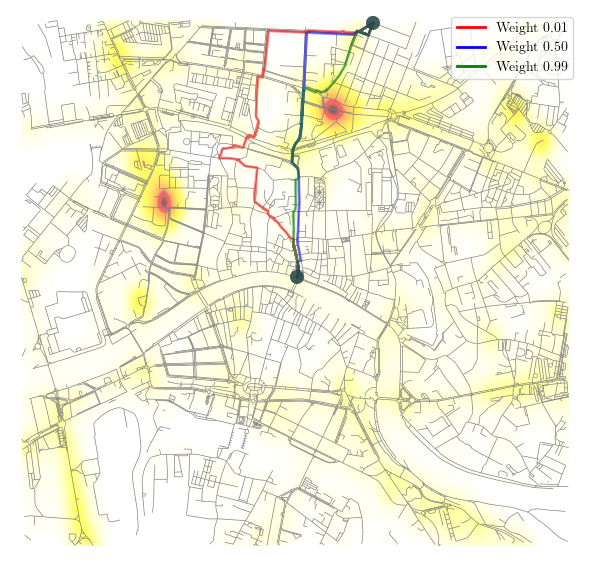

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Define colors for paths
colors = ['red', 'blue', 'green']
cmap = LinearSegmentedColormap.from_list('custom_colormap', ['white', 'yellow', 'gold', 'orange', 'darkorange', 'r', 'red', 'darkred', 'black'])

# Create a figure
fig, ax = plt.subplots(figsize=(6, 6))

# Step 1: Plot the concentration map
img = ax.imshow(concentration_map, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap=cmap, alpha=0.6)
# plt.colorbar(label="Concentration Level")

# Lock the map extent to ensure subsequent plots do not reset the axis
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])

# Step 2.1: Remove any background color
# ax.set_facecolor('none')  # Ensure no background color

# Step 2: Plot the road network
ox.plot_graph(graph, ax=ax, node_color='none', node_size=0,
              edge_color='grey', edge_linewidth=0.5, show=False, close=False)

# Step 3: Plot each path for different weights
for i, (weight, path) in enumerate(paths_by_weight.items()):
    color = colors[i % len(colors)]  # Cycle through colors

    # Plot the route without recreating the figure
    ox.plot_graph_route(
        graph,
        route=path,
        route_color=color,
        route_linewidth=2,
        ax=ax,
        show=False,
        close=False,
    )


# Step 4: Add a legend for the weights
handles = [plt.Line2D([0], [0], color=colors[i % len(colors)], lw=2, label=f'Weight {weight:.2f}')
           for i, weight in enumerate(paths_by_weight.keys())]

plt.legend(handles=handles, loc='upper right')
plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Save the plot as a PDF
plot_name = "plots/concentration_map_and_routes.pdf"
plt.tight_layout()  # Adjust layout to avoid clipping
plt.show()


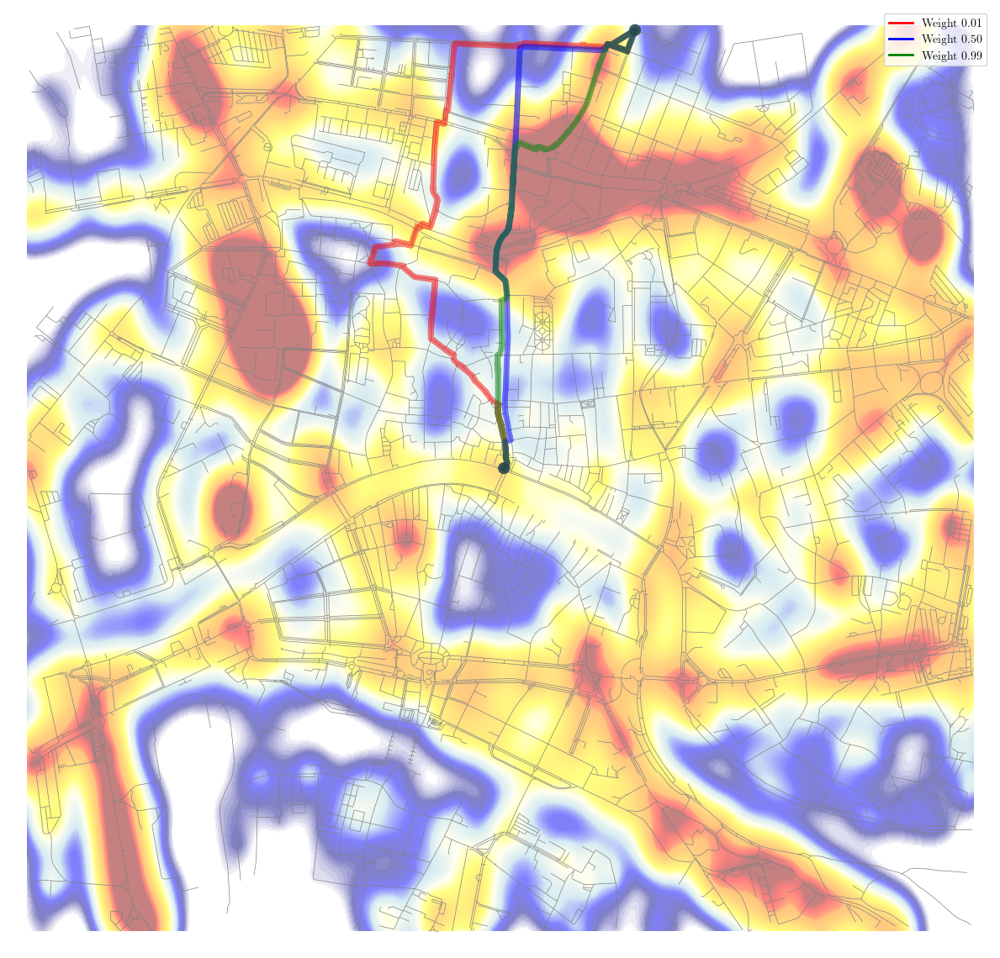

In [ ]:
# Step 3: Define the Custom Colormap (same as before)
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'white'),
    (0.03, 'darkblue'),
    (0.07, 'blue'),
    (0.12, 'lightblue'),
    # (0.15, 'lemonchiffon'),
    (0.20, 'lightyellow'),
    (0.30, 'yellow'),
    (0.40, 'gold'),
    (0.55, 'orange'),
    (0.70, 'darkorange'),
    (0.75, 'orangered'),
    (0.90, 'red'),
    (1.00, 'darkred'),
    # (1.00, 'black')
], N=256)

# Step 1: Compute Log-Transformed Concentration Values
logged_concentration_map = np.log1p(concentration_map)  # log1p to avoid log(0) issues

# Step 2: Normalize Values for Better Visualization
log_norm = Normalize(vmin=np.percentile(logged_concentration_map, 5), vmax=np.percentile(logged_concentration_map, 95))  # Clip outliers

# Create figure and axis
fig, ax = plt.subplots(figsize=(12, 12))

im = ax.imshow(logged_concentration_map, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap=cmap, norm=log_norm, alpha=0.5)


# Add a colorbar linked to the image.
# cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.01)  # Ensure colorbar is linked to the correct axis
# cbar.set_label("Log-Scaled Concentration")

# Step 2: Plot the road network
ox.plot_graph(graph, ax=ax, node_color='none', node_size=0,
              edge_color='grey', edge_linewidth=0.5, show=False, close=False)

# Step 3: Plot each path for different weights
for i, (weight, path) in enumerate(paths_by_weight.items()):
    color = colors[i % len(colors)]  # Cycle through colors

    # Plot the route without recreating the figure
    ox.plot_graph_route(
        graph,
        route=path,
        route_color=color,
        route_linewidth=5,
        ax=ax,
        show=False,
        close=False,
    )


# Step 4: Add a legend for the weights
handles = [plt.Line2D([0], [0], color=colors[i % len(colors)], lw=2, label=f'Weight {weight:.2f}')
           for i, weight in enumerate(paths_by_weight.keys())]

plt.legend(handles=handles, loc='upper right')
plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Save the plot as a PDF
plot_name = "plots/logged_concentration_map_and_routes.pdf"
plt.tight_layout()  # Adjust layout to avoid clipping
plt.show()



# Fastest and least-cost pedestrian routes


## Parameters and functions


In [134]:
weights = [round(0.8**x, 3) for x in range(1, 19)]
print(weights)

[0.8, 0.64, 0.512, 0.41, 0.328, 0.262, 0.21, 0.168, 0.134, 0.107, 0.086, 0.069, 0.055, 0.044, 0.035, 0.028, 0.023, 0.018]


In [135]:
from math import sqrt, radians, cos

def haversine_distance(lat1, lon1, lat2, lon2):
    """
    Calculate the great-circle distance between two latitude-longitude points (in metres).
    """
    R = 6371000  # Earth's radius in meters
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    x = (lon2 - lon1) * cos((lat1 + lat2) / 2)
    y = lat2 - lat1
    return sqrt(x * x + y * y) * R


def generate_valid_od_pairs(graph, nodes, min_dist=200, max_dist=1500, num_pairs=1000):
    """
    Generate a specified number of OD pairs with distances between min_dist and max_dist meters.

    Parameters:
        graph (NetworkX graph): The road network graph.
        nodes (list): List of graph nodes.
        min_dist (float): Minimum distance for OD pairs (in meters).
        max_dist (float): Maximum distance for OD pairs (in meters).
        num_pairs (int): Number of OD pairs to generate.

    Returns:
        list: List of valid (origin, destination) node pairs.
    """
    valid_pairs = []
    for _ in range(num_pairs * 2):  # Oversample to ensure enough valid pairs
        origin, destination = random.sample(nodes, 2)
        origin_coords = (graph.nodes[origin]['y'], graph.nodes[origin]['x'])
        destination_coords = (graph.nodes[destination]['y'], graph.nodes[destination]['x'])

        # Calculate Haversine distance
        distance = haversine_distance(
            origin_coords[0], origin_coords[1],
            destination_coords[0], destination_coords[1]
        )

        if min_dist <= distance <= max_dist:
            valid_pairs.append((origin, destination))
            if len(valid_pairs) >= num_pairs:
                break  # Stop once the desired number of pairs is reached

    return valid_pairs


In [136]:
def calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs, least_cost_weight):
    """
    Calculate the fastest and least-cost routes for each OD pair.

    Parameters:
        graph (NetworkX graph): The road network graph.
        edges_gdf (GeoDataFrame): The edges GeoDataFrame.
        od_pairs (list): List of origin-destination node pairs.
        least_cost_weight (float): Weight for walking time in the cost function for the least-cost route.

    Returns:
        List[dict]: Routing results for each OD pair.
    """
    results = []

    # Step 1: Update the graph for fastest routes (based on travel time)
    edges_gdf['fastest_cost'] = edges_gdf['walking_time']  # Use travel time for fastest route
    nx.set_edge_attributes(
        graph,
        edges_gdf.set_index(['u', 'v', 'key'])['fastest_cost'].to_dict(),
        'fastest_cost'
    )

    # Step 2: Update the graph for least-cost routes (based on combined time and exposure)
    edges_gdf = compute_walking_cost(
        edges_gdf, weight=least_cost_weight,
        time_col='walking_time_norm',
        exposure_col='personal_exposure_norm',
        cost_col='least_cost'
    )
    nx.set_edge_attributes(
        graph,
        edges_gdf.set_index(['u', 'v', 'key'])['least_cost'].to_dict(),
        'least_cost'
    )

    # Step 3: Iterate through OD pairs and calculate routes
    for origin, destination in tqdm(od_pairs, desc="Routing for OD Pairs"):
        try:
            # Fastest route
            fastest_path = nx.shortest_path(graph, source=origin, target=destination, weight='fastest_cost')
            fastest_time, fastest_exposure = calculate_route_metrics(graph, fastest_path)

            # Least-cost route
            least_cost_path = nx.shortest_path(graph, source=origin, target=destination, weight='least_cost')
            least_cost_time, least_cost_exposure = calculate_route_metrics(graph, least_cost_path)

            # Calculate route similarity
            similarity = calculate_route_similarity(graph, fastest_path, least_cost_path)

            # Append results
            results.append({
                'origin': origin,
                'destination': destination,

                'fastest_path': fastest_path,
                'least_cost_path': least_cost_path,

                'fastest_time': fastest_time,
                'least_cost_time': least_cost_time,

                'fastest_exposure': fastest_exposure,
                'least_cost_exposure': least_cost_exposure,

                'similarity': similarity
            })
        except Exception as e:
            # Handle errors for unreachable routes
            results.append({
                'origin': origin,
                'destination': destination,
                'fastest_path': None,
                'least_cost_path': None,
                'fastest_time': None,
                'fastest_exposure': None,
                'least_cost_time': None,
                'least_cost_exposure': None,
                'similarity': None,
                'error': str(e)
            })

    return results


In [137]:
def calculate_route_metrics(graph, path):
    """
    Calculate total time and exposure for a given path.
    """
    total_time = 0
    total_exposure = 0

    edges = list(zip(path[:-1], path[1:]))
    for edge in edges:
        data = graph[edge[0]][edge[1]][0]  # Assumes no multiple edges
        total_time += data['walking_time']
        total_exposure += data.get('personal_exposure', 0)

    return total_time, total_exposure


In [138]:
def calculate_route_similarity(graph, path1, path2):
    """
    Calculate distance-weighted Jaccard similarity between two paths.
    """
    # Get edges for both paths
    edges1 = set(zip(path1[:-1], path1[1:]))
    edges2 = set(zip(path2[:-1], path2[1:]))

    # Calculate intersection and union
    intersection = edges1 & edges2
    union = edges1 | edges2

    # Calculate weights (lengths) for intersection and union
    intersection_weight = sum(graph[u][v][0]['length'] for u, v in intersection)
    union_weight = sum(graph[u][v][0]['length'] for u, v in union)

    # Jaccard similarity
    return intersection_weight / union_weight if union_weight > 0 else 0


## Origin-destination pairs


In [ ]:
from tqdm import tqdm

# Define the number of OD pairs
num_od_pairs = 50000

# Extract all nodes
nodes = list(graph.nodes)

# Generate OD pairs
# od_pairs = generate_valid_od_pairs(graph, nodes, min_dist=200, max_dist=1500, num_pairs=num_od_pairs)

In [ ]:
import json

# Save to JSON
# with open(exawaro_path + "od_pairs.json", "w") as f:
#     json.dump(od_pairs, f)

# Reload from JSON
with open(exawaro_path + "od_pairs.json", "r") as f:
    od_pairs = json.load(f)

print(len(od_pairs), od_pairs[:5])  # Print the first 5 OD pairs


48663 [[418743718, 303595400], [11434998450, 9288051633], [8773819709, 11480656562], [252756504, 3499473877], [1596063928, 259967532]]


In [ ]:
# Step 1: Extract origin and destination nodes from OD pairs
origins = {origin for origin, destination in od_pairs}
destinations = {destination for origin, destination in od_pairs}

valid_origins = [n for n in origins if n in graph.nodes]
valid_destinations = [n for n in destinations if n in graph.nodes]

# Step 2: Prepare coordinates for origins and destinations
origin_x = [graph.nodes[node]['x'] for node in valid_origins]  # Longitude
origin_y = [graph.nodes[node]['y'] for node in valid_origins]  # Latitude

destination_x = [graph.nodes[node]['x'] for node in valid_destinations]  # Longitude
destination_y = [graph.nodes[node]['y'] for node in valid_destinations]  # Latitude

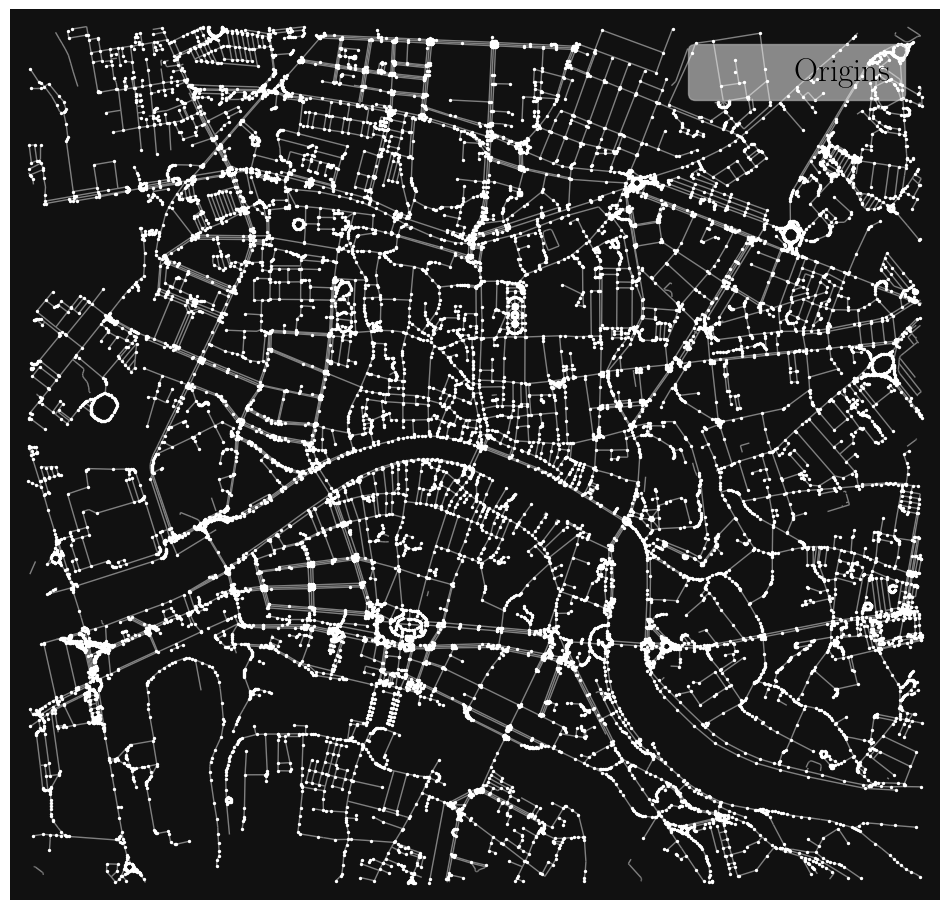

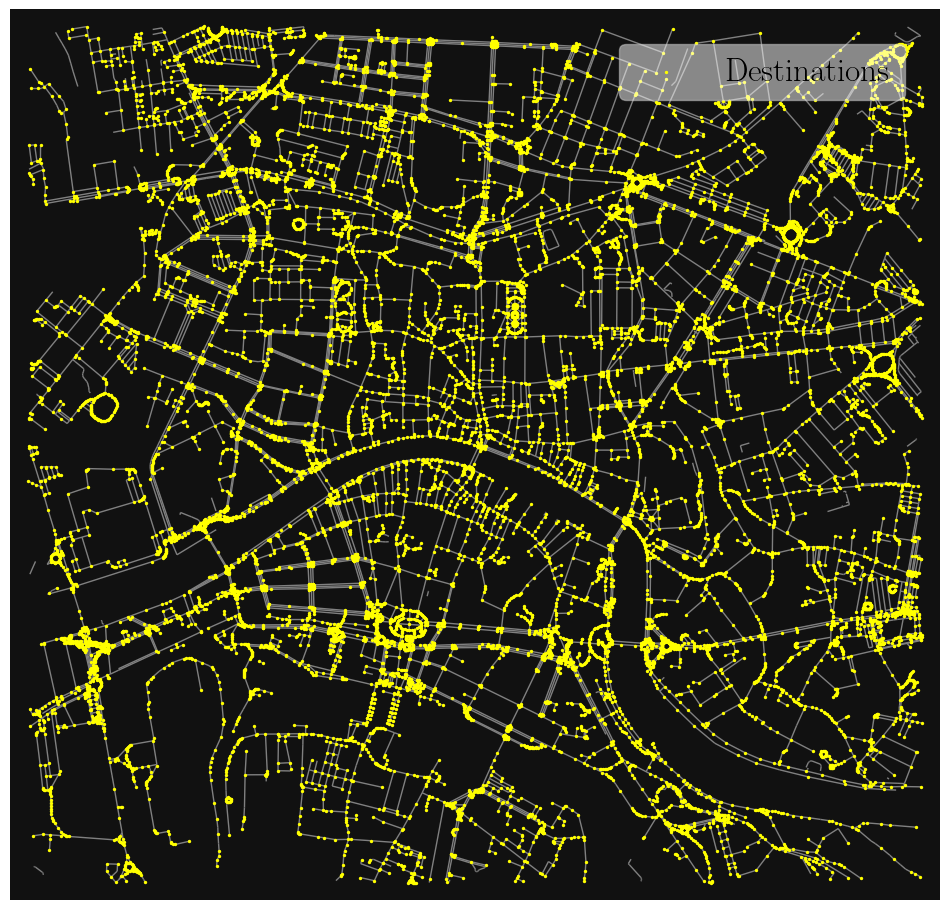

In [ ]:
# Step 3: Plot the graph with origins
fig, ax = ox.plot_graph(graph, show=False, close=False, edge_color='gray', node_size=0, figsize=(12, 12))

legend_fontsize = 24

# Plot origins
ax.scatter(origin_x, origin_y, c='white', s=2, label='Origins', zorder=5)
ax.legend(
    fontsize=legend_fontsize,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),  # Fine-tune position within the plot
    frameon=True,                 # Keep the frame
    fancybox=True,                # Rounded edges for the legend box
    framealpha=0.5,               # Set transparency for the legend background
)
plt.show()

# Step 4: Plot the graph with destinations
fig, ax = ox.plot_graph(graph, show=False, close=False, edge_color='gray', node_size=0, figsize=(12, 12))

# Plot destinations
ax.scatter(destination_x, destination_y, c='yellow', s=2, label='Destinations', zorder=5)
ax.legend(
    fontsize=legend_fontsize,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    frameon=True,
    fancybox=True,
    framealpha=0.5,
)
plt.show()

In [ ]:
import osmnx as ox
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# Step 1: Count the number of destinations for each origin
origin_counts = tradeoff_df.groupby('origin')['destination'].nunique()

# Step 2: Filter origins that have at least 3 destinations
valid_origins = origin_counts[origin_counts >= 3].index.tolist()

# Step 3: Randomly select 10 such origins
random.seed(42)  # Ensure reproducibility
selected_origins = random.sample(valid_origins, min(3, len(valid_origins)))  # Pick 10 or max available

# Step 4: Extract destinations for the selected origins
selected_pairs = tradeoff_df[tradeoff_df['origin'].isin(selected_origins)][['origin', 'destination']]

# Step 5: Extract coordinates for origins and destinations
od_dict = {}
for origin in selected_origins:
    if origin in graph.nodes:
        origin_coords = (graph.nodes[origin]['x'], graph.nodes[origin]['y'])
        od_dict[origin_coords] = []

        destinations = selected_pairs[selected_pairs['origin'] == origin]['destination']
        for destination in destinations:
            if destination in graph.nodes:
                destination_coords = (graph.nodes[destination]['x'], graph.nodes[destination]['y'])
                od_dict[origin_coords].append(destination_coords)

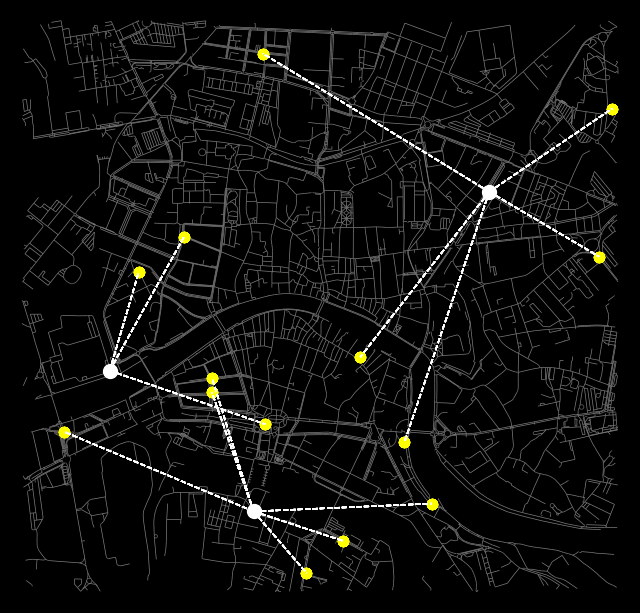

In [ ]:
# Step 6: Plot the road network and OD pairs
fig, ax = plt.subplots(figsize=(8, 8), facecolor='black')  # Black background
ax.set_facecolor('black')  # Set background of the plot

ox.plot_graph(graph, ax=ax, node_size=0, edge_color='grey', edge_linewidth=0.5, show=False, close=False)

# Step 7: Plot origins with destination rings
for origin_coords, destinations in od_dict.items():
    # Plot origin
    ax.scatter(*origin_coords, color='white', s=100, label="Origin" if 'Origin' not in ax.get_legend_handles_labels()[1] else "")

    # Plot destinations
    for destination_coords in destinations:
        ax.scatter(*destination_coords, color='yellow', s=50, label="Destination" if 'Destination' not in ax.get_legend_handles_labels()[1] else "")
        ax.plot([origin_coords[0], destination_coords[0]], [origin_coords[1], destination_coords[1]], color='white', linestyle='--', linewidth=1)

# Step 8: Add Legend and Show Plot
# plt.legend(fontsize=legend_fontsize-8)
# Save the plot as a PDF
plot_name = "plots/od_pairs_example.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()


## Compute route trade-offs


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Results container
pareto_results = []

timestamp = datetime.now().strftime("%m_%d_%H%M")  # Format: month-day-hourminute

for weight in weights:
    # Perform routing with the current weight
    print(f"  Routing with weight: {weight}")
    routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs,
                                                              least_cost_weight=weight)
    results_df = pd.DataFrame(routing_results)
    # results_df.to_csv(output_path+f"routing_results_{weight}_01211830.csv", index=False)

    # Calculate percentage differences
    time_diff = results_df['least_cost_time'] - results_df['fastest_time']
    exposure_diff = results_df['least_cost_exposure'] - results_df['fastest_exposure']

    time_diff_percentage = (time_diff / results_df['fastest_time']) * 100
    exposure_diff_percentage = (exposure_diff / results_df['fastest_exposure']) * 100

    # Replace infinities and NaNs with 0 for clean calculation
    time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    time_diff_percentage.fillna(0, inplace=True)
    exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    exposure_diff_percentage.fillna(0, inplace=True)

    # Store results
    pareto_results.append({
        'weight': weight,

        'avg_time_diff_percentage': time_diff_percentage.mean(),
        'avg_exposure_diff_percentage': exposure_diff_percentage.mean(),

        'median_time_diff_percentage': time_diff_percentage.median(),
        'median_exposure_diff_percentage': exposure_diff_percentage.median(),

        'time_45th': time_diff_percentage.quantile(0.45),
        'time_55th': time_diff_percentage.quantile(0.55),
        'exposure_45th': exposure_diff_percentage.quantile(0.45),
        'exposure_55th': exposure_diff_percentage.quantile(0.55),

        'time_25th': time_diff_percentage.quantile(0.25),
        'time_75th': time_diff_percentage.quantile(0.75),
        'exposure_25th': exposure_diff_percentage.quantile(0.25),
        'exposure_75th': exposure_diff_percentage.quantile(0.75),

    })

# Convert to DataFrame for plotting
pareto_df = pd.DataFrame(pareto_results)
pareto_df.to_csv(output_path+f"pareto_df_{timestamp}.csv", index=False)

  Routing with weight: 1.0


Routing for OD Pairs: 100%|██████████| 945/945 [00:42<00:00, 22.14it/s]


  Routing with weight: 0.8


Routing for OD Pairs: 100%|██████████| 945/945 [00:39<00:00, 24.00it/s]


  Routing with weight: 0.64


Routing for OD Pairs: 100%|██████████| 945/945 [00:39<00:00, 24.00it/s]


... (30 outputs left out)

  Routing with weight: 0.018


Routing for OD Pairs: 100%|██████████| 945/945 [00:37<00:00, 25.05it/s]


  Routing with weight: 0.014


Routing for OD Pairs: 100%|██████████| 945/945 [00:40<00:00, 23.61it/s]


In [ ]:
areto_df = pd.read_csv(exawaro_path + 'pareto_df_01211830.csv')
pareto_df

,weight,avg_time_diff_percentage,avg_exposure_diff_percentage,median_time_diff_percentage,median_exposure_diff_percentage,time_45th,time_55th,exposure_45th,exposure_55th,time_25th,time_75th,exposure_25th,exposure_75th
0,0.01,17.900018,-20.543310,9.860868,-16.365520,7.284854,12.218653,-18.808765,-13.818517,1.448826,25.712495,-30.192699,-3.896980
1,0.02,14.305449,-20.076523,6.907377,-15.699114,5.254060,8.945019,-18.133069,-12.949035,0.781392,20.825963,-29.956098,-3.381875
2,0.03,12.372663,-19.618669,5.586007,-14.673893,3.768097,7.117154,-17.404731,-12.072653,0.570985,18.240572,-29.672548,-2.352808
3,0.04,10.564253,-18.980413,4.039064,-13.710378,2.900625,5.790178,-16.449348,-11.091460,0.315031,15.592816,-29.109440,-1.173407
4,0.05,9.504985,-18.470289,3.415536,-12.588133,2.461868,4.751896,-15.491442,-9.742692,0.191684,13.315529,-28.766293,-0.864730
5,0.06,8.360789,-17.780961,2.689137,-11.082618,1.921547,3.603971,-14.410652,-8.870152,0.121815,11.013846,-28.289946,-0.605271
6,0.07,7.407392,-17.120376,1.955039,-9.672667,1.237624,2.758271,-12.796218,-7.280135,0.036729,9.521919,-27.743895,-0.185384
7,0.08,6.424217,-16.477334,1.440393,-8.974698,0.918931,2.352197,-11.163930,-6.423655,0.001623,7.728745,-26.232734,0.000000
8,0.09,5.815943,-15.954437,1.208109,-7.801124,0.711426,1.899061,-9.996703,-5.462709,0.000000,6.845627,-25.591696,0.000000
9,0.10,5.268790,-15.402354,1.075123,-7.445153,0.583163,1.576159,-9.602786,-4.883072,0.000000,6.003382,-24.058658,0.000000


In [ ]:
# NOTE: Interrupted exploratory run; the KeyboardInterrupt output is not a paper result.
for weight in weights:
  # Perform routing
  routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs, least_cost_weight=weight)

  # Save and analyze results
  results_df = pd.DataFrame(routing_results)
  results_df.to_csv(f"routing_results_{weight}_0117.csv", index=False)

  # Compare metrics
  time_diff = results_df['fastest_time'] - results_df['least_cost_time']
  exposure_diff = results_df['fastest_exposure'] - results_df['least_cost_exposure']

  # Calculate percentage differences (handling division by zero)
  # opposite places
  time_diff_percentage = (time_diff / results_df['fastest_time']) * 100
  time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)  # Replace infinities with 0
  time_diff_percentage.fillna(0, inplace=True)  # Replace NaN with 0

  exposure_diff_percentage = (exposure_diff / results_df['fastest_exposure']) * 100
  exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)  # Replace infinities with 0
  exposure_diff_percentage.fillna(0, inplace=True)  # Replace NaN with 0


  # Aggregate similarity
  average_similarity = results_df['similarity'].mean()

  print()
  print(f"Average Route Similarity (Weighted Jaccard): {average_similarity:.4f}")

  # Print descriptive statistics for absolute and percentage differences with formatted output
  print("Absolute Differences:")
  print(f"Time Difference Summary:\n{time_diff.describe().apply(lambda x: f'{x:.2f}')}")  # Format to 2 decimal places
  print(f"Exposure Difference Summary:\n{exposure_diff.describe().apply(lambda x: f'{x:.4f}')}")  # Format to 4 decimal places
  print()
  print("\nPercentage Differences:")
  print(f"Time Difference (Percentage) Summary:\n{time_diff_percentage.describe().apply(lambda x: f'{x:.2f}')}")  # 2 decimals
  print(f"Exposure Difference (Percentage) Summary:\n{exposure_diff_percentage.describe().apply(lambda x: f'{x:.2f}')}")  # 2 decimals

  print()

  # weight for time
  # 1-w for exposure

  # check variables saved for each weight

Routing for OD Pairs: 100%|██████████| 966/966 [00:35<00:00, 27.06it/s]



Average Route Similarity (Weighted Jaccard): 0.3117
Absolute Differences:
Time Difference Summary:
count      966.00
mean      -213.86
std        248.05
min      -1765.04
25%       -325.61
50%       -129.77
75%        -19.64
max          0.00
dtype: object
Exposure Difference Summary:
count    966.0000
mean       0.1795
std        0.3682
min        0.0000
25%        0.0103
50%        0.0658
75%        0.1684
max        2.1650
dtype: object


Percentage Differences:
Time Difference (Percentage) Summary:
count     966.00
mean      -21.78
std        24.78
min      -180.52
25%       -32.74
50%       -14.76
75%        -2.68
max         0.00
dtype: object
Exposure Difference (Percentage) Summary:
count    966.00
mean      20.74
std       20.24
min        0.00
25%        3.67
50%       15.98
75%       31.05
max       92.41
dtype: object



Routing for OD Pairs: 100%|██████████| 966/966 [00:34<00:00, 27.76it/s]



Average Route Similarity (Weighted Jaccard): 0.4608
Absolute Differences:
Time Difference Summary:
count     966.00
mean      -86.45
std       128.38
min      -723.75
25%      -115.34
50%       -27.02
75%        -0.80
max         0.00
dtype: object
Exposure Difference Summary:
count    966.0000
mean       0.1675
std        0.3643
min        0.0000
25%        0.0015
50%        0.0486
75%        0.1605
max        2.1556
dtype: object


Percentage Differences:
Time Difference (Percentage) Summary:
count     966.00
mean       -8.80
std        13.81
min      -149.86
25%       -11.84
50%        -3.07
75%        -0.11
max         0.00
dtype: object
Exposure Difference (Percentage) Summary:
count    966.00
mean      18.46
std       20.57
min        0.00
25%        0.46
50%       12.38
75%       29.38
max       92.37
dtype: object



Routing for OD Pairs: 100%|██████████| 966/966 [00:34<00:00, 27.65it/s]



Average Route Similarity (Weighted Jaccard): 0.5582
Absolute Differences:
Time Difference Summary:
count     966.00
mean      -48.89
std        88.18
min      -723.26
25%       -55.67
50%        -9.10
75%         0.00
max         0.00
dtype: object
Exposure Difference Summary:
count    966.0000
mean       0.1517
std        0.3582
min       -0.0001
25%        0.0000
50%        0.0259
75%        0.1308
max        2.1421
dtype: object


Percentage Differences:
Time Difference (Percentage) Summary:
count     966.00
mean       -5.03
std        10.43
min      -149.86
25%        -5.73
50%        -0.83
75%         0.00
max         0.00
dtype: object
Exposure Difference (Percentage) Summary:
count    966.00
mean      15.69
std       20.41
min       -0.05
25%        0.00
50%        6.44
75%       25.84
max       92.37
dtype: object



Routing for OD Pairs:  58%|█████▊    | 559/966 [00:21<00:15, 25.54it/s]


KeyboardInterrupt: 

## Recompute the detailed trade-off table


In [ ]:
# Generate the first table with detailed routing results

for weight in weights:
    detailed_results = []
    print(f"Routing with weight: {weight}")
    routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs, least_cost_weight=weight)
    results_df = pd.DataFrame(routing_results)

    for _, row in results_df.iterrows():
        # Extract route details
        detailed_results.append({
            'origin': row['origin'],
            'destination': row['destination'],
            'weight': weight,

            'fastest_path' : row['fastest_path'],
            'least_cost_path': row['least_cost_path'],

            'least_cost_time': row['least_cost_time'],
            'fastest_time': row['fastest_time'],

            'least_cost_exposure': row['least_cost_exposure'],
            'fastest_exposure': row['fastest_exposure'],

            'similarity': row['similarity']
        })

    # Convert to DataFrame
    detailed_df = pd.DataFrame(detailed_results)
    detailed_df.to_csv(exawaro_path+f"tables/routing_results_{weight}_{num_od_pairs}_pairs.csv", index=False)


Routing with weight: 0.512


Routing for OD Pairs: 100%|██████████| 48663/48663 [30:39<00:00, 26.45it/s]


Routing with weight: 0.41


Routing for OD Pairs: 100%|██████████| 48663/48663 [31:32<00:00, 25.71it/s]


Routing with weight: 0.328


Routing for OD Pairs: 100%|██████████| 48663/48663 [33:28<00:00, 24.23it/s]


... (2 outputs left out)

Routing with weight: 0.21


Routing for OD Pairs: 100%|██████████| 48663/48663 [31:38<00:00, 25.64it/s]


Routing with weight: 0.168


Routing for OD Pairs: 100%|██████████| 48663/48663 [31:15<00:00, 25.94it/s]


In [ ]:
import os
import pandas as pd

# Specify the directory where the files are located
directory = exawaro_path + "tables/"
print(os.listdir(directory))

# Gather all files matching the pattern
files = [f for f in os.listdir(directory) if f.startswith("routing_results_") and f.endswith("50000_pairs.csv")]
print(files)

# Initialize an empty list to store DataFrames
dataframes = []

# Loop through the files and read them into DataFrames
for file in files:
    file_path = os.path.join(directory, file)
    df = pd.read_csv(file_path)  # Adjust the function if your file isn't CSV (e.g., pd.read_excel for Excel files)
    dataframes.append(df)

# Concatenate all DataFrames
tradeoff_df = pd.concat(dataframes, ignore_index=True)
tradeoff_df.head()

['.ipynb_checkpoints', 'routing_results_0.134_50000_pairs.csv', 'routing_results_0.107_50000_pairs.csv', 'routing_results_0.086_50000_pairs.csv', 'routing_results_0.069_50000_pairs.csv', 'routing_results_0.055_50000_pairs.csv', 'routing_results_0.044_50000_pairs.csv', 'routing_results_0.035_50000_pairs.csv', 'routing_results_0.028_50000_pairs.csv', 'routing_results_0.023_50000_pairs.csv', 'routing_results_0.018_50000_pairs.csv', 'routing_results_0.014_50000_pairs.csv', 'routing_results_0.8_50000_pairs.csv', 'routing_results_0.64_50000_pairs.csv', 'routing_results_0.512_50000_pairs.csv', 'routing_results_0.41_50000_pairs.csv', 'routing_results_0.328_50000_pairs.csv', 'routing_results_0.262_50000_pairs.csv', 'routing_results_0.21_50000_pairs.csv', 'routing_results_0.168_50000_pairs.csv']
['routing_results_0.134_50000_pairs.csv', 'routing_results_0.107_50000_pairs.csv', 'routing_results_0.086_50000_pairs.csv', 'routing_results_0.069_50000_pairs.csv', 'routing_results_0.055_50000_pairs.csv

In [ ]:
# Save the concatenated result into a single file
output_file = os.path.join(directory, "routing_results_pisa_50000_pairs.csv")
tradeoff_df.to_csv(output_file, index=False)

print(f"Files concatenated and saved to {output_file}")

In [ ]:
tradeoff_df[['similarity', 'least_cost_time', 'fastest_time', 'least_cost_exposure', 'fastest_exposure']].describe()

,similarity,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure
count,924507.000000,924507.000000,924507.000000,924507.000000,924507.000000
mean,0.602586,989.573446,930.301161,0.406165,0.539500
std,0.381430,387.637573,344.031326,0.219473,0.439962
min,0.000000,146.987992,146.987992,0.007745,0.007745
25%,0.218716,702.178268,672.667130,0.253667,0.282981
50%,0.657885,1000.756509,951.266673,0.375797,0.438539
75%,1.000000,1254.887435,1184.063729,0.515873,0.638605
max,1.000000,3332.802879,3024.985825,3.278474,3.295932


In [ ]:
 tradeoff_df['least_cost_path'].nunique()

160700

In [ ]:
tradeoff_df['fastest_path'].nunique()

48979

In [ ]:
print(tradeoff_df[['origin', 'destination']].nunique())

origin         14771
destination    14748
dtype: int64


In [ ]:
tradeoff_df['od'] = tradeoff_df['origin'].astype(str) + '_' + tradeoff_df['destination'].astype(str)
print(tradeoff_df[['od']].nunique())

od    48657
dtype: int64


# Analyse route trade-offs


In [180]:
# load calculated routes before the analysis of trade-offs

tradeoff_df = pd.read_csv(exawaro_path + "tables/routing_results_pisa_50000_pairs.csv")
tradeoff_df['time_diff_percentage'] = ((tradeoff_df['least_cost_time'] - tradeoff_df['fastest_time']) / tradeoff_df['fastest_time']) * 100
tradeoff_df['exposure_diff_percentage'] = ((tradeoff_df['least_cost_exposure'] - tradeoff_df['fastest_exposure']) / tradeoff_df['fastest_exposure']) * 100

tradeoff_df.head()

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,418743718,303595400,0.134,"[418743718, 418743717, 4447981064, 9301315480,...","[418743718, 418743717, 4447981064, 9301315480,...",823.455335,822.764477,0.404427,0.405867,0.922259,0.083968,-0.354917
1,11434998450,9288051633,0.134,"[11434998450, 11434998451, 11434998452, 243667...","[11434998450, 11434998451, 11434998452, 243667...",1505.145851,1179.818814,0.403215,0.957777,0.035942,27.574322,-57.900949
2,8773819709,11480656562,0.134,"[8773819709, 1676246554, 4233692606, 167624656...","[8773819709, 1676246554, 4233692606, 167624656...",1071.085314,1064.430996,0.614806,0.856419,0.437273,0.625153,-28.211961
3,252756504,3499473877,0.134,"[252756504, 417072474, 252756505, 292619034, 4...","[252756504, 417072474, 252756505, 292619034, 4...",903.171810,903.171810,0.597267,0.597267,1.000000,0.000000,0.000000
4,1596063928,259967532,0.134,"[1596063928, 279535526, 8932714350, 3629443122...","[1596063928, 279535526, 8932714350, 3629443122...",1202.961431,1202.961431,0.420761,0.420761,1.000000,0.000000,0.000000


In [195]:
# Results container for hypervolume calculations
hypervolume_results = []
counter = 0
# Group by OD pair to compute hypervolume
od_groups = tradeoff_df.groupby(['origin', 'destination'])

for (origin, destination), group in od_groups:
  min_exposure = group['least_cost_exposure'].min()
  min_weight_exposure = group[group['weight'] == 0.014][['least_cost_exposure']].values[0]
  # print(type(min_exposure), type(min_weight_exposure))
  if min_exposure < min_weight_exposure:
    counter += 1
    print()
    # print(f'{origin}, {destination}: {min_weight_exposure} vs. {min_exposure} ')

print(counter)

98


In [197]:
# Results container for hypervolume calculations
hypervolume_results = []
counter = 0
# Group by OD pair to compute hypervolume
od_groups = tradeoff_df.groupby(['origin', 'destination'])

for (origin, destination), group in od_groups:
  min_exposure = group['least_cost_exposure'].min()
  min_weight_exposure = group[group['weight'] == 0.014][['least_cost_exposure']].values[0]
  # print(type(min_exposure), type(min_weight_exposure))
  if min_exposure < min_weight_exposure:
    counter += 1
    # print()
    print(f'{origin}, {destination}: {100*(min_weight_exposure-min_exposure)/min_weight_exposure}% ')

# print(counter)

199398765, 2474030098: [0.00598219]\% 
213411036, 1952499549: [0.01014664]\% 
213411036, 11659355291: [0.00500735]\% 
245917972, 8725786970: [0.31540277]\% 
252758173, 8725787829: [0.25416985]\% 
722333051, 7727337378: [0.0135691]\% 
887108829, 12327505560: [0.00847963]\% 
887108999, 11479409769: [0.3893199]\% 
1209810875, 5022056659: [0.2574927]\% 
1210578686, 8725786974: [0.22062197]\% 
1386672970, 8725786973: [0.25050114]\% 
1668761714, 8725786973: [0.09856111]\% 
1676297414, 8725786975: [0.24938114]\% 
2614055202, 8725786978: [0.25609004]\% 
3073790391, 8725786974: [0.21140442]\% 
3080437017, 8725786969: [0.16885679]\% 
3082461952, 11480659018: [8.63563758]\% 
3446498327, 5022056659: [0.37061497]\% 
3499473879, 8725786961: [0.00830923]\% 
3499473881, 8725786965: [0.29585485]\% 
4590938816, 9297778000: [0.12309849]\% 
4760367467, 8725786961: [0.00645729]\% 
5022056657, 11750502418: [0.51335772]\% 
5022056659, 11724956090: [0.37084966]\% 
5131166914, 6886612853: [0.06977132]\% 
51411

In [196]:
len(od_groups)

48657

## Fastest-path distributions


## Histograms


Distribution of fastest walking times and exposure values.


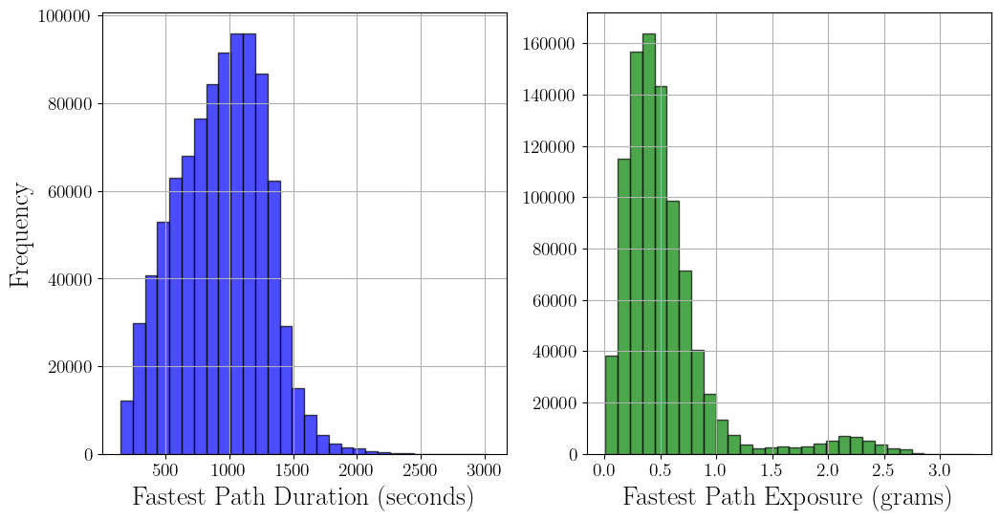

In [ ]:
# Fastest durations and exposures
fastest_durations = tradeoff_df['fastest_time']
fastest_exposures = tradeoff_df['fastest_exposure']

fontsize = 20

# Plot histograms
plt.figure(figsize=(12, 6))

# Histogram for fastest durations
plt.subplot(1, 2, 1)

plt.hist(fastest_durations, bins=30, color='blue', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Duration (seconds)', fontsize=fontsize)
plt.ylabel('Frequency', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)


# Histogram for fastest exposures
plt.subplot(1, 2, 2)

plt.hist(fastest_exposures, bins=30, color='green', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Exposure (grams)', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
plot_name = "plots/distributions.pdf"
plt.show()

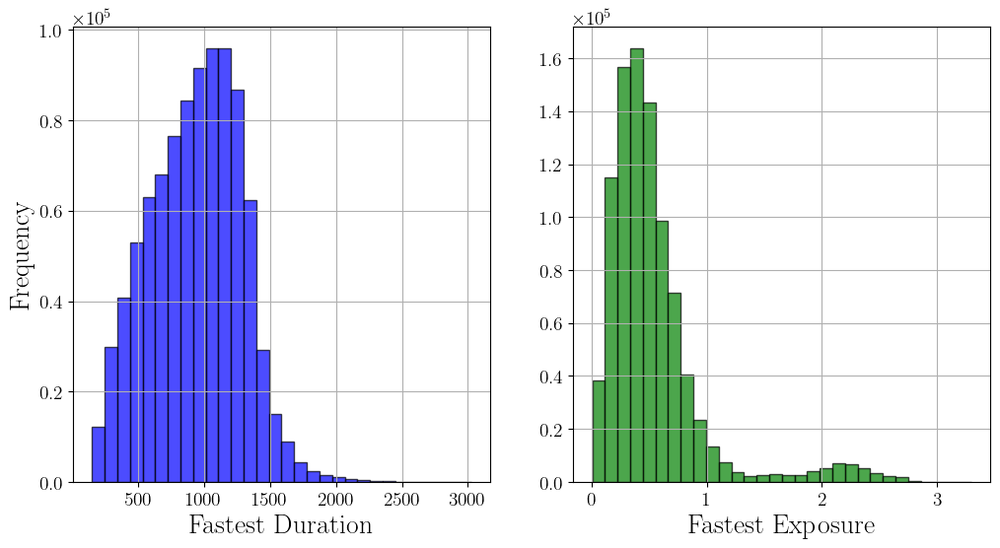

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Fastest durations and exposures
fastest_durations = tradeoff_df['fastest_time']
fastest_exposures = tradeoff_df['fastest_exposure']

fontsize = 20

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Histogram for fastest durations
axes[0].hist(fastest_durations, bins=30, color='blue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Fastest Duration', fontsize=fontsize)
axes[0].set_ylabel('Frequency', fontsize=fontsize)
axes[0].grid()

# Apply scientific notation to y-axis
axes[0].yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
axes[0].ticklabel_format(style='sci', axis='y', scilimits=(0,0))


# Histogram for fastest exposures
axes[1].hist(fastest_exposures, bins=30, color='green', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Fastest Exposure', fontsize=fontsize)
axes[1].grid()

# Apply scientific notation to y-axis
axes[1].yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
axes[1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))

# Increase the font size of exponent labels
for ax in axes:
    ax.yaxis.get_offset_text().set_fontsize(fontsize - 6)  # Adjust exponent text size
    ax.tick_params(axis='both', which='major', labelsize=fontsize - 6)  # Adjust major ticks
    # ax.tick_params(axis='both', which='minor', labelsize=fontsize - 6)  # Adjust minor ticks

    # Set custom tick locations (6 evenly spaced ticks)
    # ax.set_xticks(np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 5))
    # ax.set_yticks(np.linspace(0, max(ax.get_yticks()), 5))

# Save the plot as a PDF
plot_name = "plots/distributions_formatted.pdf"
plt.show()


## Spatial distributions


In [ ]:
print(list(graph.edges(data=True))[:5])  # Inspect assigned values


[(31770712, 8803236872, {'osmid': 303806090, 'highway': 'secondary', 'name': 'Via Giacomo Matteotti', 'oneway': False, 'reversed': False, 'length': 7.154473229019667, 'from': 8803236872, 'to': 31770712, 'geometry': <LINESTRING (10.411 43.71, 10.41 43.71)>, 'walking_time': 5.110338020728333, 'walking_time_norm': 0.025383769912968774, 'personal_exposure': 0.00345857571300633, 'personal_exposure_norm': 0.0032580129210976086}), (31770712, 3446498345, {'osmid': 1006192939, 'highway': 'secondary', 'junction': 'roundabout', 'name': 'Piazza Caduti di Cefalonia divisione Acqui', 'oneway': False, 'reversed': True, 'length': 0.8051859942461673, 'from': 3446498345, 'to': 31770712, 'geometry': <LINESTRING (10.41 43.71, 10.41 43.71)>, 'walking_time': 0.5751328530329767, 'walking_time_norm': 0.0024893810005761916, 'personal_exposure': 0.00039820509718936983, 'personal_exposure_norm': 0.00037511318517939336}), (31770712, 3446498346, {'osmid': 1006192940, 'highway': 'secondary', 'junction': 'roundabout

In [ ]:
import osmnx as ox
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize


# Define Custom Colormap
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'lightblue'),
    (0.01, 'blue'),
    (0.03, 'yellow'),
    (0.15, 'gold'),
    (0.20, 'orange'),
    (0.50, 'darkorange'),
    (0.65, 'orangered'),
    (0.85, 'red'),
    (0.90, 'darkred'),
    (1.00, 'darkred')
], N=256)

# Step 1: Extract Pre-Normalized Walking Time and Exposure from Graph Edges
edge_time_norm = {}
edge_exposure_norm = {}

for u, v, data in graph.edges(data=True):
    edge_time_norm[(u, v)] = data.get('walking_time', 1e-6)  # Avoid log(0) by setting a small value
    edge_exposure_norm[(u, v)] = data.get('personal_exposure', 1e-6)  # Avoid log(0)

# Step 2: Apply Logarithmic Transformation
log_time_norm = {edge: np.log1p(val) for edge, val in edge_time_norm.items()}  # log1p ensures log(0) is handled
log_exposure_norm = {edge: np.log1p(val) for edge, val in edge_exposure_norm.items()}

# Step 3: Normalize Log-Transformed Values
time_values = np.array(list(log_time_norm.values()))
exposure_values = np.array(list(log_exposure_norm.values()))

time_norm = Normalize(vmin=time_values.min(), vmax=time_values.max())
exposure_norm = Normalize(vmin=exposure_values.min(), vmax=exposure_values.max())


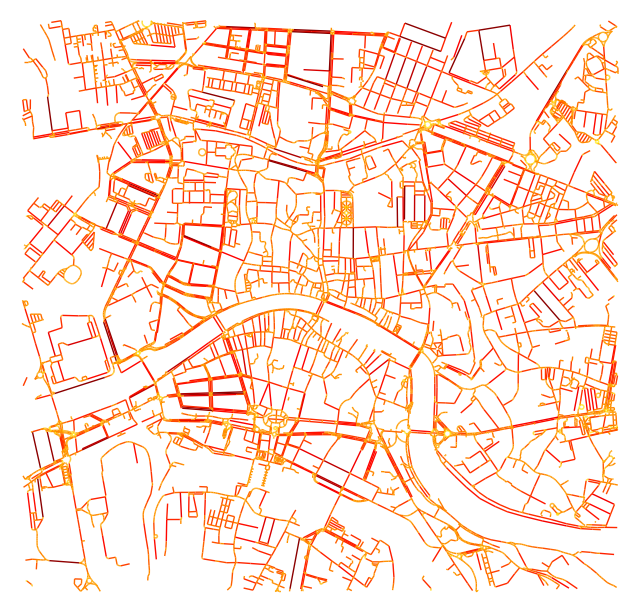

In [ ]:
# Step 4: Assign Colors & Width Based on Log-Scaled Walking Time
for (edge, time_val) in log_time_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color'] = cmap(time_norm(time_val))  # Use custom colormap
        graph[edge[0]][edge[1]][0]['width'] = 0.5 + 3 * time_norm(time_val)

# Step 5: Plot Road Network Colored by Log-Scaled Walking Time
fig, ax = plt.subplots(figsize=(8, 8))
edge_colors = [graph[u][v][0].get('color', 'grey') for u, v in graph.edges()]
# edge_widths = [graph[u][v][0].get('width', 1.5) for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=ax, node_size=0, edge_color=edge_colors,
    # edge_linewidth=edge_widths,
    show=False, close=False
)

# Add colorbar using the custom colormap
sm = ScalarMappable(norm=time_norm, cmap='coolwarm')
sm.set_array([])
# plt.colorbar(sm, label="Log10-Scaled Walking Time")


# Save the plot as a PDF
plot_name = "plots/walking_time_map.pdf"
plt.show()

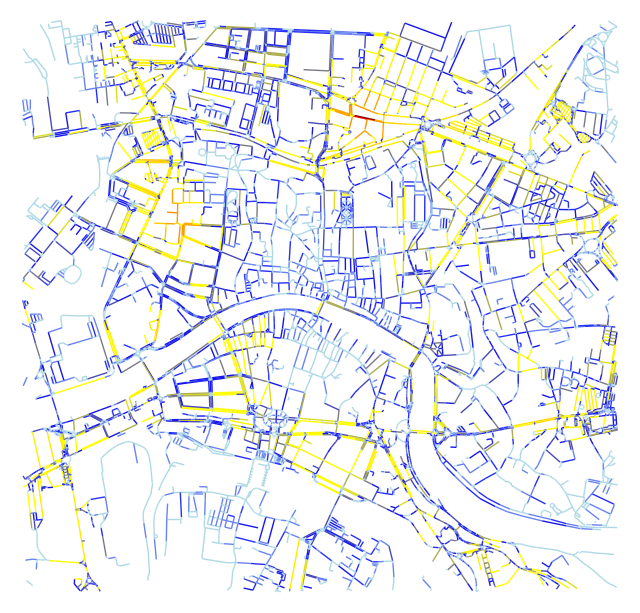

In [ ]:

# Step 6: Assign Colors & Width Based on Log-Scaled Personal Exposure
for (edge, exposure_val) in log_exposure_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color'] = cmap(exposure_norm(exposure_val))  # Use custom colormap
        graph[edge[0]][edge[1]][0]['width'] = 0.5 + 3 * exposure_norm(exposure_val)

# Step 7: Plot Road Network Colored by Log-Scaled Personal Exposure
fig, ax = plt.subplots(figsize=(8, 8))
edge_colors = [graph[u][v][0].get('color', 'grey') for u, v in graph.edges()]
edge_widths = [graph[u][v][0].get('width', 1.5) for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=ax, node_size=0, edge_color=edge_colors,
    # edge_linewidth=edge_widths,
    show=False, close=False
)

# Add colorbar for log-scaled exposure
sm = ScalarMappable(norm=exposure_norm, cmap=cmap)
sm.set_array([])
# plt.colorbar(sm, label="Log-Scaled Personal Exposure")


# Save the plot as a PDF
plot_name = "plots/road_exposure_map.pdf"
plt.show()

In [ ]:
import osmnx as ox
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Define Custom Colormap
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'lightblue'),
    (0.01, 'blue'),
    (0.03, 'yellow'),
    (0.15, 'gold'),
    (0.20, 'orange'),
    (0.50, 'darkorange'),
    (0.65, 'orangered'),
    (0.85, 'red'),
    (0.90, 'darkred'),
    (1.00, 'darkred')
], N=256)

# Step 1: Extract Pre-Normalized Walking Time and Exposure from Graph Edges
edge_time_norm = {}
edge_exposure_norm = {}

for u, v, data in graph.edges(data=True):
    edge_time_norm[(u, v)] = data.get('walking_time_norm', 1e-6)
    edge_exposure_norm[(u, v)] = data.get('personal_exposure_norm', 1e-6)

# Step 2: Apply Log Transformation
log_time_norm = {edge: np.log10(val + 1e-3) for edge, val in edge_time_norm.items()}
log_exposure_norm = {edge: np.log10(val + 1e-3) for edge, val in edge_exposure_norm.items()}

# Step 3: Normalize Transformed Values
time_values = np.array(list(log_time_norm.values()))
exposure_values = np.array(list(log_exposure_norm.values()))

time_norm = Normalize(vmin=np.percentile(time_values, 5), vmax=np.percentile(time_values, 95))
exposure_norm = Normalize(vmin=np.percentile(exposure_values, 5), vmax=np.percentile(exposure_values, 95))

# Step 4: Assign Colors & Width Based on Log-Scaled Walking Time
for (edge, time_val) in log_time_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color'] = cmap(time_norm(time_val))
        graph[edge[0]][edge[1]][0]['width'] = 0.5 + 3 * time_norm(time_val)

# Step 5: Assign Colors & Width Based on Log-Scaled Personal Exposure
for (edge, exposure_val) in log_exposure_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color_exposure'] = cmap(exposure_norm(exposure_val))
        graph[edge[0]][edge[1]][0]['width_exposure'] = 0.5 + 3 * exposure_norm(exposure_val)


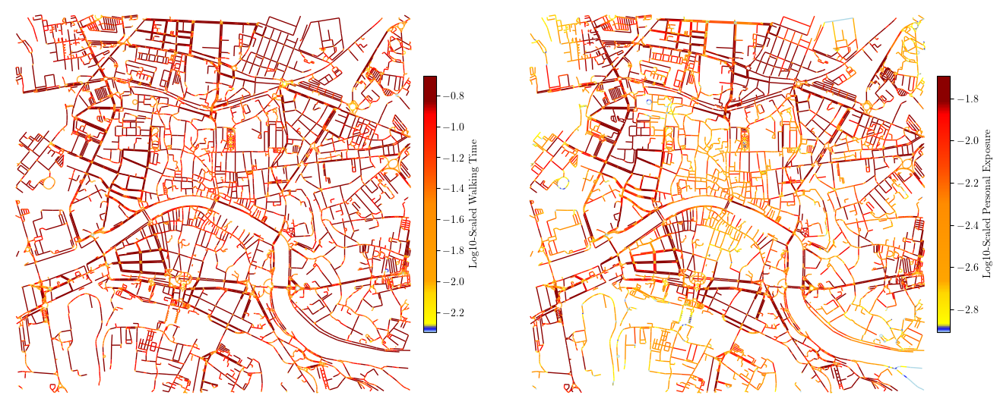

In [ ]:
# Step 6: Plot Both Maps in the Same Figure
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot Walking Time
edge_colors = [graph[u][v][0].get('color', 'grey') for u, v in graph.edges()]
edge_widths = [graph[u][v][0].get('width', 1.5) for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=axes[0], node_size=0, edge_color=edge_colors,
    # edge_linewidth=edge_widths,
    show=False, close=False
)

sm = ScalarMappable(norm=time_norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=axes[0], fraction=0.03, pad=0.01)
cbar.set_label("Log10-Scaled Walking Time")

# axes[0].set_title("Road Network with Log10-Scaled Walking Time", fontsize=fontsize)

# Plot Personal Exposure
edge_colors_exp = [graph[u][v][0].get('color_exposure', 'grey') for u, v in graph.edges()]
edge_widths_exp = [graph[u][v][0].get('width_exposure', 1.5) for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=axes[1], node_size=0, edge_color=edge_colors_exp,
    # edge_linewidth=edge_widths_exp,
    show=False, close=False
)

sm = ScalarMappable(norm=exposure_norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=axes[1], fraction=0.03, pad=0.01)
cbar.set_label("Log10-Scaled Personal Exposure")

# axes[1].set_title("Road Network with Log10-Scaled Personal Exposure", fontsize=fontsize)

# Save the plot as a PDF
plot_name = "plots/time_and_road_exposure_map.pdf"
plt.show()


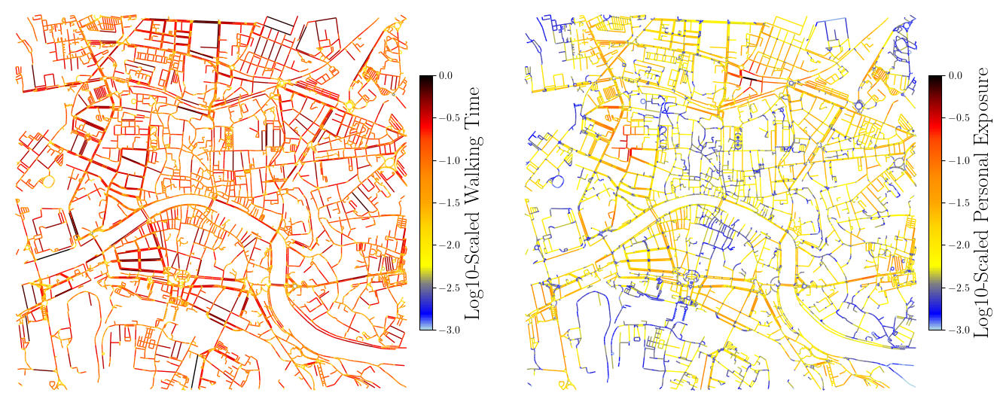

In [ ]:
import osmnx as ox
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Define Custom Colormap
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'lightblue'),
    (0.06, 'blue'),
    (0.18, 'gray'),
    (0.25, 'yellow'),
    (0.40, 'gold'),
    (0.50, 'orange'),
    (0.60, 'darkorange'),
    (0.75, 'orangered'),
    (0.80, 'red'),
    (0.9, 'darkred'),
    (1.0, 'black')
], N=256)

fontsize = 20

# Step 1: Extract Pre-Normalized Walking Time and Exposure from Graph Edges
edge_time_norm = {}
edge_exposure_norm = {}

for u, v, data in graph.edges(data=True):
    edge_time_norm[(u, v)] = data.get('walking_time_norm', 1e-6)
    edge_exposure_norm[(u, v)] = data.get('personal_exposure_norm', 1e-6)

# Step 2: Apply Log Transformation
log_time_norm = {edge: np.log10(val + 1e-3) for edge, val in edge_time_norm.items()}
log_exposure_norm = {edge: np.log10(val + 1e-3) for edge, val in edge_exposure_norm.items()}

# Step 3: Normalize Values **SEPARATELY** for Each Plot
time_values = np.array(list(log_time_norm.values()))
exposure_values = np.array(list(log_exposure_norm.values()))

time_norm = Normalize(vmin=time_values.min(), vmax=time_values.max())  # Normalize separately
exposure_norm = Normalize(vmin=exposure_values.min(), vmax=exposure_values.max())  # Normalize separately

# Step 4: Create Subplots for Independent Scaling
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot Walking Time (Left)
for (edge, time_val) in log_time_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color_time'] = cmap(time_norm(time_val))

edge_colors_time = [graph[u][v][0].get('color_time', 'grey') for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=axes[0], node_size=0, edge_color=edge_colors_time, edge_linewidth=1, show=False, close=False
)

sm_time = ScalarMappable(norm=time_norm, cmap=cmap)
sm_time.set_array([])
cbar = plt.colorbar(sm_time, ax=axes[0], fraction=0.03, pad=0.01)
cbar.set_label("Log10-Scaled Walking Time", fontsize=fontsize)

# axes[0].set_title("Road Network with Log10-Scaled Walking Time", fontsize=fontsize)

# Plot Personal Exposure (Right)
for (edge, exposure_val) in log_exposure_norm.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color_exposure'] = cmap(exposure_norm(exposure_val))

edge_colors_exposure = [graph[u][v][0].get('color_exposure', 'grey') for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=axes[1], node_size=0, edge_color=edge_colors_exposure,
    edge_linewidth=1, show=False, close=False
)

sm_exposure = ScalarMappable(norm=exposure_norm, cmap=cmap)
sm_exposure.set_array([])
cbar = plt.colorbar(sm_exposure, ax=axes[1], fraction=0.03, pad=0.01)
cbar.set_label("Log10-Scaled Personal Exposure", fontsize=fontsize)

# axes[1].set_title("Road Network with Log10-Scaled Personal Exposure", fontsize=fontsize)

# Save the plot as a PDF
plot_name = "plots/time_and_road_exposure_map_separate_normalization.pdf"
plt.show()


## Global weighting


In [ ]:
# Unique weights
weights = tradeoff_df['weight'].unique()

# Results container
pareto_results = []

# Iterate over each weight
for weight in weights:
    # Filter the DataFrame for the current weight
    filtered_df = tradeoff_df[tradeoff_df['weight'] == weight]

    # Calculate percentage differences
    time_diff = filtered_df['least_cost_time'] - filtered_df['fastest_time']
    exposure_diff = filtered_df['least_cost_exposure'] - filtered_df['fastest_exposure']

    time_diff_percentage = (time_diff / filtered_df['fastest_time']) * 100
    exposure_diff_percentage = (exposure_diff / filtered_df['fastest_exposure']) * 100

    # Replace infinities and NaNs with 0 for clean calculation
    time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    time_diff_percentage.fillna(0, inplace=True)
    exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    exposure_diff_percentage.fillna(0, inplace=True)

    # Store results for this weight
    pareto_results.append({
        'weight': weight,

        'avg_time_diff_percentage': time_diff_percentage.mean(),
        'avg_exposure_diff_percentage': exposure_diff_percentage.mean(),

        'median_time_diff_percentage': time_diff_percentage.median(),
        'median_exposure_diff_percentage': exposure_diff_percentage.median(),

        'time_45th': time_diff_percentage.quantile(0.45),
        'time_55th': time_diff_percentage.quantile(0.55),
        'exposure_45th': exposure_diff_percentage.quantile(0.45),
        'exposure_55th': exposure_diff_percentage.quantile(0.55),

        'time_25th': time_diff_percentage.quantile(0.25),
        'time_75th': time_diff_percentage.quantile(0.75),
        'exposure_25th': exposure_diff_percentage.quantile(0.25),
        'exposure_75th': exposure_diff_percentage.quantile(0.75),
    })

# Convert to DataFrame for plotting
pareto_df = pd.DataFrame(pareto_results)

# Sort Pareto DataFrame by weight
pareto_df = pareto_df.sort_values(by='weight', ascending=True)

# Reset the index.
pareto_df = pareto_df.reset_index(drop=True)

# Display Pareto DataFrame
pareto_df


,weight,avg_time_diff_percentage,avg_exposure_diff_percentage,median_time_diff_percentage,median_exposure_diff_percentage,time_45th,time_55th,exposure_45th,exposure_55th,time_25th,time_75th,exposure_25th,exposure_75th
0,0.014,16.055436,-20.138335,8.638485,-15.331473,6.534848,10.845730,-18.040890,-12.581610,0.951341,22.408052,-30.797530,-2.844746
1,0.018,14.510693,-19.913096,7.371541,-15.033029,5.456623,9.392154,-17.765019,-12.238516,0.711760,20.165863,-30.601574,-2.303462
2,0.023,13.458054,-19.711134,6.530133,-14.646677,4.783550,8.556459,-17.484714,-11.828571,0.528750,18.512217,-30.462713,-1.892571
3,0.028,12.373454,-19.450828,5.562309,-14.185062,3.987363,7.497624,-17.072828,-11.283834,0.392291,17.203009,-30.324475,-1.346956
4,0.035,11.051178,-19.062214,4.465917,-13.508092,3.173229,6.046651,-16.450560,-10.621509,0.270315,15.515043,-29.964180,-0.888750
5,0.044,9.865627,-18.582264,3.667129,-12.467303,2.596027,5.018206,-15.515573,-9.658093,0.152242,13.645677,-29.448095,-0.627740
6,0.055,8.756758,-18.067281,2.974923,-11.246638,2.038959,4.132015,-14.482967,-8.595190,0.086370,11.907564,-28.928998,-0.422642
7,0.069,7.316129,-17.178945,1.973284,-9.487011,1.269581,2.977175,-12.493901,-6.850253,0.011740,9.753757,-27.917560,-0.056870
8,0.086,5.845850,-16.118816,1.282104,-7.690316,0.774844,1.960119,-10.528334,-5.000397,0.000000,7.564429,-26.188841,0.000000
9,0.107,4.796993,-15.122597,0.792055,-6.013926,0.402811,1.294725,-8.788509,-3.357301,0.000000,5.780524,-24.471688,0.000000


## Average percentage differences


In [ ]:
pareto_df = pd.read_csv(exawaro_path + "/tables/pareto_df.csv")

In [ ]:
# NOTE: Worst-case reference point used by the hypervolume score below.
# Define the reference point as the worst-case scenario
reference_time = pareto_df['avg_time_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min())
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min())

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

Best Point on Pareto Front (Highest Hypervolume):
weight                               0.107000
avg_time_diff_percentage             4.796993
avg_exposure_diff_percentage       -15.122597
median_time_diff_percentage          0.792055
median_exposure_diff_percentage     -6.013926
time_45th                            0.402811
time_55th                            1.294725
exposure_45th                       -8.788509
exposure_55th                       -3.357301
time_25th                            0.000000
time_75th                            5.780524
exposure_25th                      -24.471688
exposure_75th                        0.000000
hypervolume                        140.010266
Name: 9, dtype: float64


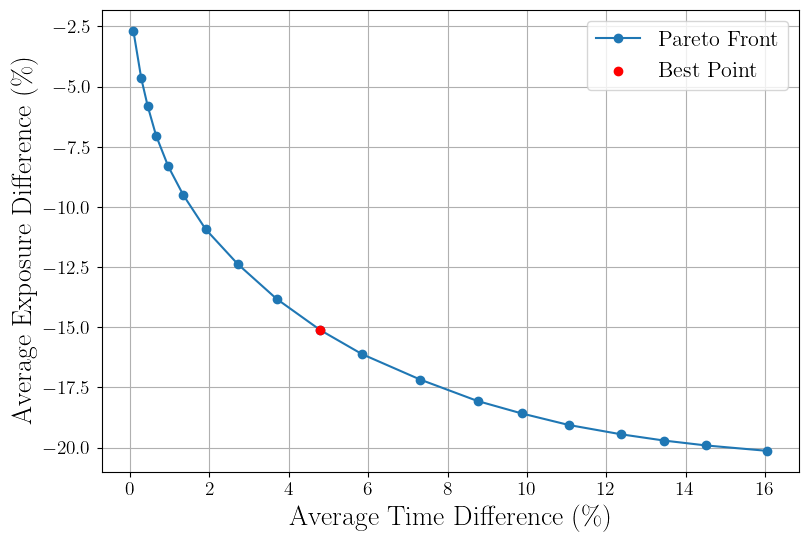

In [ ]:
# NOTE: The red/green points plotted later derive from best_point here and the local average below; this cell has no active save.
# Print the best point
print("Best Point on Pareto Front (Highest Hypervolume):")
print(best_point)

legend_fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point", zorder=5)

plt.xlabel("Average Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Average Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid()
plt.legend(fontsize=legend_fontsize-4)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)

# Save the plot as a PDF
plot_name = "plots/pareto_avg_differences.pdf"
plt.show()


In [ ]:
print("Pareto Front Data (averages):")
pareto_df[['weight', 'avg_time_diff_percentage', 'avg_exposure_diff_percentage']]

Pareto Front Data (averages):


,weight,avg_time_diff_percentage,avg_exposure_diff_percentage
0,0.01,17.900018,-20.543310
1,0.02,14.305449,-20.076523
2,0.03,12.372663,-19.618669
3,0.04,10.564253,-18.980413
4,0.05,9.504985,-18.470289
5,0.06,8.360789,-17.780961
6,0.07,7.407392,-17.120376
7,0.08,6.424217,-16.477334
8,0.09,5.815943,-15.954437
9,0.10,5.268790,-15.402354


## Pareto fronts for individual OD pairs


In [ ]:
# NOTE: Warning from chained assignment during exploratory inspection; final figures use the recomputed arrays below.
# Step 1: Select an OD Pair (Change these values to the desired OD)
origin_1 = 418743718
destination_1 = 303595400

# Step 2: Filter Data for the Selected OD Pair
od_data = tradeoff_df[(tradeoff_df['origin'] == selected_origin) &
                      (tradeoff_df['destination'] == selected_destination)]

# Step 3: Compute Percentage Differences
od_data['time_diff_percentage'] = ((od_data['least_cost_time'] - od_data['fastest_time']) / od_data['fastest_time']) * 100
od_data['exposure_diff_percentage'] = ((od_data['least_cost_exposure'] - od_data['fastest_exposure']) / od_data['fastest_exposure']) * 100

# Step 4: Compute the Pareto Front (Non-Dominated Points)
pareto_front = od_data.sort_values(by=['time_diff_percentage'])
pareto_front = pareto_front[pareto_front['exposure_diff_percentage'].cummin() == pareto_front['exposure_diff_percentage']]

<ipython-input-47-205a5ecfa7a0>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  od_data['time_diff_percentage'] = ((od_data['least_cost_time'] - od_data['fastest_time']) / od_data['fastest_time']) * 100
<ipython-input-47-205a5ecfa7a0>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  od_data['exposure_diff_percentage'] = ((od_data['least_cost_exposure'] - od_data['fastest_exposure']) / od_data['fastest_exposure']) * 100


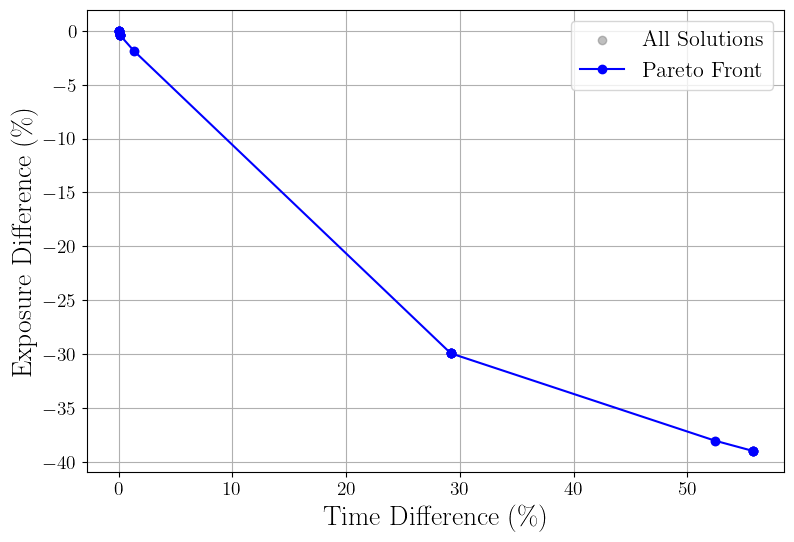

In [ ]:
fontsize=20

# Step 5: Plot the Pareto Front
plt.figure(figsize=(9, 6))

# Scatter plot for all data points
plt.scatter(od_data['time_diff_percentage'], od_data['exposure_diff_percentage'], color='gray', alpha=0.5, label="All Solutions")

# Highlight Pareto front
plt.plot(pareto_front['time_diff_percentage'], pareto_front['exposure_diff_percentage'], '-o', color='blue', label="Pareto Front")

# Labels and Title
plt.xlabel("Time Difference (\%)", fontsize=fontsize)
plt.ylabel("Exposure Difference (\%)", fontsize=fontsize)
plt.grid(True)
plt.legend(fontsize=legend_fontsize-4)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)

# Save the plot as a PDF
plot_name = f"plots/pareto_front_{selected_origin}_{selected_destination}.pdf"
plt.show()


In [ ]:
print("Pareto Front Data:")
od_data[['weight', 'time_diff_percentage', 'exposure_diff_percentage']]

Pareto Front Data:


,weight,time_diff_percentage,exposure_diff_percentage
0,0.134,0.083968,-0.354917
48663,0.107,0.083968,-0.354917
97326,0.086,1.339194,-1.853813
145989,0.069,29.197355,-29.938874
194652,0.055,29.197355,-29.938874
243315,0.044,29.197355,-29.938874
291978,0.035,29.197355,-29.938874
340641,0.028,52.410888,-38.044944
389304,0.023,55.746968,-38.997698
437967,0.018,55.746968,-38.997698


Several OD pairs


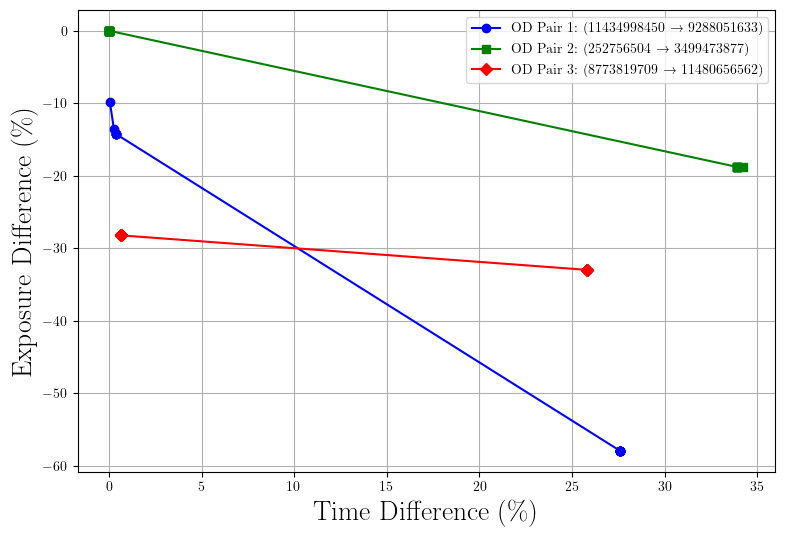

In [ ]:
# NOTE: Three OD pairs used for the paper's per-OD Pareto front (MDM Fig. 1); saves plots/pareto_front_three_pairs.pdf.
# Select Three OD Pairs (Manually or Randomly)
selected_od_pairs = [
    # (418743718, 303595400),
    (11434998450,	9288051633),
    (252756504,	3499473877),
    (8773819709,	11480656562),
    # (1596063928,	259967532)
]

plt.figure(figsize=(9, 6))

# Step 2: Loop Through Each OD Pair and Compute the Pareto Front
colors = ['blue', 'green', 'red', 'orange', 'yellow']
markers = ['o', 's', 'D', 'v', '8']
labels = []

for i, (origin, destination) in enumerate(selected_od_pairs):
    # Filter data for the selected OD pair
    od_data = tradeoff_df[(tradeoff_df['origin'] == origin) &
                          (tradeoff_df['destination'] == destination)].copy()

    # Compute Percentage Differences
    od_data['time_diff_percentage'] = ((od_data['least_cost_time'] - od_data['fastest_time']) / od_data['fastest_time']) * 100
    od_data['exposure_diff_percentage'] = ((od_data['least_cost_exposure'] - od_data['fastest_exposure']) / od_data['fastest_exposure']) * 100

    # Compute the Pareto Front
    pareto_front = od_data.sort_values(by=['time_diff_percentage'])
    pareto_front = pareto_front[pareto_front['exposure_diff_percentage'].cummin() == pareto_front['exposure_diff_percentage']]

    # Step 3: Plot Each Pareto Front
    plt.plot(pareto_front['time_diff_percentage'], pareto_front['exposure_diff_percentage'],
             linestyle='-', marker=markers[i], color=colors[i], label=f"OD Pair {i+1}: ({origin} → {destination})")

# Labels and Title
plt.xlabel("Time Difference (\%)", fontsize=fontsize)
plt.ylabel("Exposure Difference (\%)", fontsize=fontsize)

plt.legend()
plt.grid(True)

# Save the plot as a PDF
plot_name = f"plots/pareto_front_three_pairs.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()


## Pareto front of median percentage differences


In [ ]:
# Define the reference point as the worst-case scenario (max time and exposure differences)
reference_time = pareto_df['median_time_diff_percentage'].max()
reference_exposure = pareto_df['median_exposure_diff_percentage'].max()

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['median_time_diff_percentage']) *  # Width
    (reference_exposure - pareto_df['median_exposure_diff_percentage'])  # Height
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]


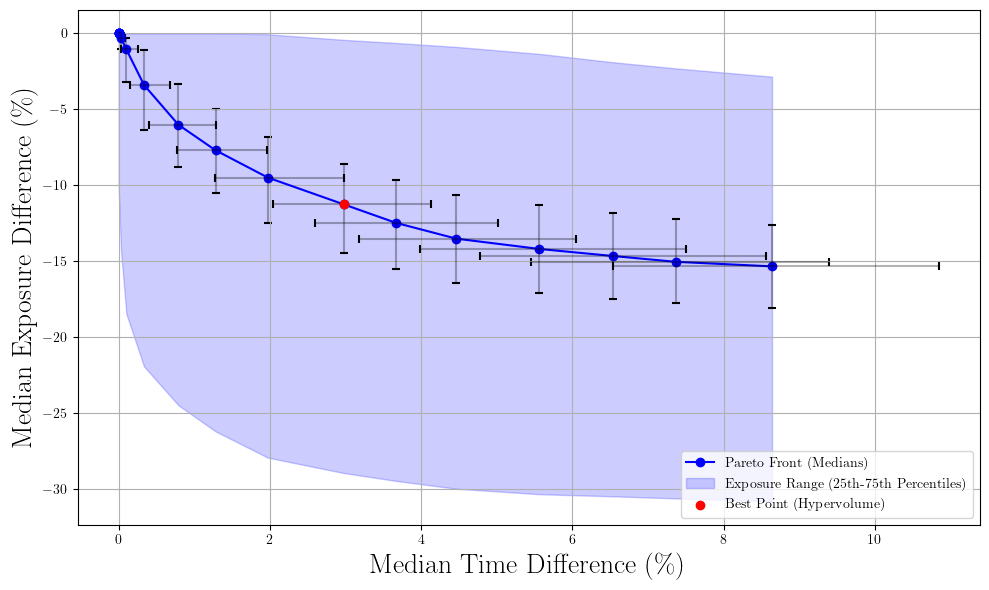

Plot saved as PDF: plots/pareto_med_differences.pdf
Best Point Based on Hypervolume:
weight                              0.055000
avg_time_diff_percentage            8.756758
avg_exposure_diff_percentage      -18.067281
median_time_diff_percentage         2.974923
median_exposure_diff_percentage   -11.246638
time_45th                           2.038959
time_55th                           4.132015
exposure_45th                     -14.482967
exposure_55th                      -8.595190
time_25th                           0.086370
time_75th                          11.907564
exposure_25th                     -28.928998
exposure_75th                      -0.422642
hypervolume                        63.696028
Name: 6, dtype: float64


In [ ]:
# Plot Pareto front with the best point highlighted
plt.figure(figsize=(10, 6))

# Plot the medians
plt.plot(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    '-o', label="Pareto Front (Medians)", color='blue'
)

# Add shaded areas for exposure (25th-75th percentiles)
plt.fill_between(
    pareto_df['median_time_diff_percentage'],  # X-axis is the time difference medians
    pareto_df['exposure_25th'],               # Lower bound of exposure (25th percentile)
    pareto_df['exposure_75th'],               # Upper bound of exposure (75th percentile)
    color='blue', alpha=0.2, label="Exposure Range (25th-75th Percentiles)"
)

# Add vertical boxplot ranges for exposure
for i, (x, y, y45, y55) in enumerate(zip(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    pareto_df['exposure_45th'],
    pareto_df['exposure_55th']
)):
    # Boxplot-style vertical line
    plt.plot([x, x], [y45, y55], color='black', alpha=0.3)  # Vertical line for the range
    plt.scatter([x], [y45], color='black', marker='_')  # Lower quartile
    plt.scatter([x], [y55], color='black', marker='_')  # Upper quartile

# Add horizontal boxplot ranges for time differences
for i, (x, y, x45, x55) in enumerate(zip(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    pareto_df['time_45th'],
    pareto_df['time_55th']
)):
    plt.plot([x45, x55], [y, y], color='black', alpha=0.3)  # Horizontal line for time
    plt.scatter([x45], [y], color='black', marker='|')  # Lower quartile for time
    plt.scatter([x55], [y], color='black', marker='|')  # Upper quartile for time


# Highlight the best point
plt.scatter(
    best_point['median_time_diff_percentage'],
    best_point['median_exposure_diff_percentage'],
    color='red', label="Best Point (Hypervolume)", zorder=5
)

# Add labels and legend
plt.xlabel("Median Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Median Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid()
plt.legend()

# Save the plot as a PDF
pareto_name = "plots/pareto_med_differences.pdf"
plt.tight_layout()  # Adjust layout to avoid clipping
plt.show()

print(f"Plot saved as PDF: {pareto_name}")
# Print details of the best point
print("Best Point Based on Hypervolume:")
print(best_point)


In [ ]:
print("Pareto Front Data (medians):")
pareto_df[['weight', 'median_time_diff_percentage', 'median_exposure_diff_percentage',
                 'exposure_45th', 'exposure_55th']]

Pareto Front Data (medians):


,weight,median_time_diff_percentage,median_exposure_diff_percentage,exposure_45th,exposure_55th
0,1.000,0.000000,0.000000,0.000000,0.000000
1,0.800,0.000000,0.000000,0.000000,0.000000
2,0.640,0.000000,0.000000,0.000000,0.000000
3,0.512,0.000000,0.000000,0.000000,0.000000
4,0.410,0.000000,0.000000,0.000000,0.000000
5,0.328,0.000000,0.000000,0.000000,0.000000
6,0.262,0.000000,0.000000,-0.010817,0.000000
7,0.210,0.016407,-0.262969,-1.011580,0.000000
8,0.168,0.119731,-1.133204,-3.747432,-0.329972
9,0.134,0.472958,-4.886206,-7.736903,-1.542084


## Exposure and time distributions by weight


In [ ]:
# Select weights to compare
weights_to_plot = [0.014, 0.21, 0.8]
exposure_weights_to_plot = [0.8, 0.21, 0.014]

# Filter the DataFrame for the selected weights
filtered_data = tradeoff_df[tradeoff_df['weight'].isin(weights_to_plot)]

# Prepare the data for plotting
time_data = {weight: filtered_data[filtered_data['weight'] == weight]['least_cost_time'] for weight in weights_to_plot}
exposure_data = {weight: filtered_data[filtered_data['weight'] == weight]['least_cost_exposure'] for weight in weights_to_plot}

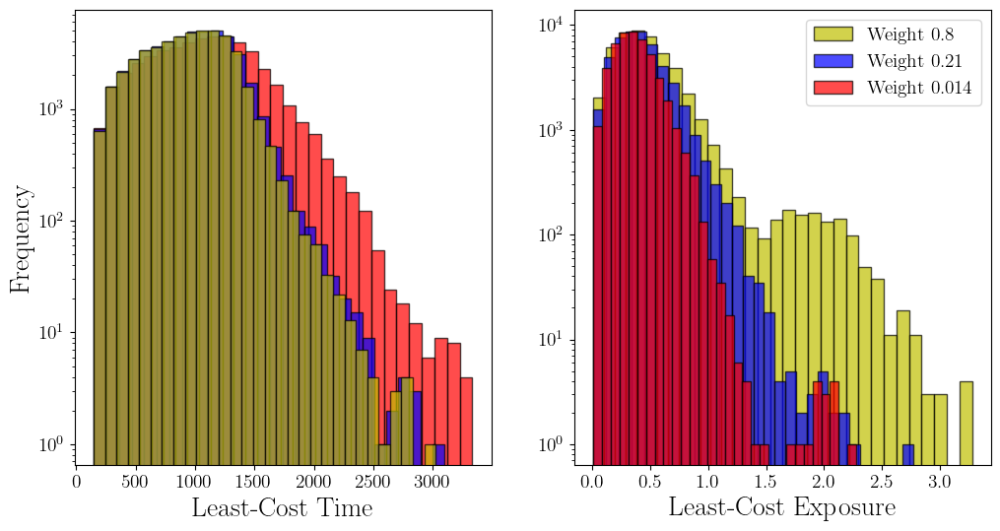

In [ ]:
colors = ['r', 'b', 'y'] # define colors for weights
exposure_colors = ['y', 'b', 'r'] # define colors for weights

legend_fontsize = 20          # fontsize

# Plot the histograms
plt.figure(figsize=(12, 6))

# Plot for least-cost time
plt.subplot(1, 2, 1)
plt.yscale('log')

for weight, color in zip(weights_to_plot, colors):
    plt.hist(time_data[weight], bins=30, alpha=0.7, label=f"Weight {weight}", color=color, edgecolor='black')

plt.xlabel('Least-Cost Time', fontsize=legend_fontsize)
plt.ylabel('Frequency', fontsize=legend_fontsize)

# plt.legend(fontsize=legend_fontsize-6)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)


# Plot for least-cost exposure
plt.subplot(1, 2, 2)
plt.yscale('log')

for weight, color in zip(exposure_weights_to_plot, exposure_colors):
    plt.hist(exposure_data[weight], bins=30, alpha=0.7, label=f"Weight {weight}", color=color, edgecolor='black')

plt.xlabel('Least-Cost Exposure', fontsize=legend_fontsize)

plt.legend(fontsize=legend_fontsize-6)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)


# Save the plot as a PDF
plot_name = "plots/histograms-v2.pdf"
plt.show()


## Spatial distributions by weight


In [ ]:
# NOTE: Early concentration-map attempt with no stored output; cell 137 is the canonical producer.
# Step 1: Compute Log-Transformed Concentration Values
logged_concentration_map = np.log1p(concentration_map)  # log1p to avoid log(0) issues

# Step 2: Normalize Values for Better Visualization
log_norm = Normalize(vmin=np.percentile(logged_concentration_map, 5), vmax=np.percentile(logged_concentration_map, 95))  # Clip outliers

# Step 3: Define the Custom Colormap (same as before)
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'white'),
    (0.03, 'darkblue'),
    (0.07, 'blue'),
    (0.12, 'lightblue'),
    # (0.15, 'lemonchiffon'),
    (0.20, 'lightyellow'),
    (0.30, 'yellow'),
    (0.40, 'gold'),
    (0.55, 'orange'),
    (0.70, 'darkorange'),
    (0.75, 'orangered'),
    (0.90, 'red'),
    (1.00, 'darkred'),
    # (1.00, 'black')
], N=256)

# Step 4: Plot the Log-Transformed Concentration Map
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(logged_concentration_map, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap=cmap, norm=log_norm, alpha=0.7)

ox.plot_graph(
    graph, ax=ax, node_size=0, edge_color='gray', edge_linewidth=1, show=False, close=False
)

# Add a colorbar linked to the image.
cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.01)  # Ensure colorbar is linked to the correct axis
cbar.set_label("Log-Scaled Concentration")


# Save the plot as a PDF
plot_name = "plots/concentration_map_new.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()


## Weighted Jaccard similarity


In [ ]:
# Filter unexpected weights
valid_weights = tradeoff_df['weight'].between(0.0, 1.0)

filtered_df = tradeoff_df[valid_weights]

# Sort the weights
weights = np.sort(filtered_df['weight'].unique())  # Sort weights in ascending order
# print(weights)

# Prepare data for boxplots
jaccard_data = [filtered_df[filtered_df['weight'] == weight]['similarity'] for weight in weights]
# jaccard_data.set_index('weight')

In [ ]:
print(jaccard_data[12].describe())

count    48648.000000
mean         0.696254
std          0.347677
min          0.000000
25%          0.383014
50%          0.863804
75%          1.000000
max          1.000000
Name: similarity, dtype: float64


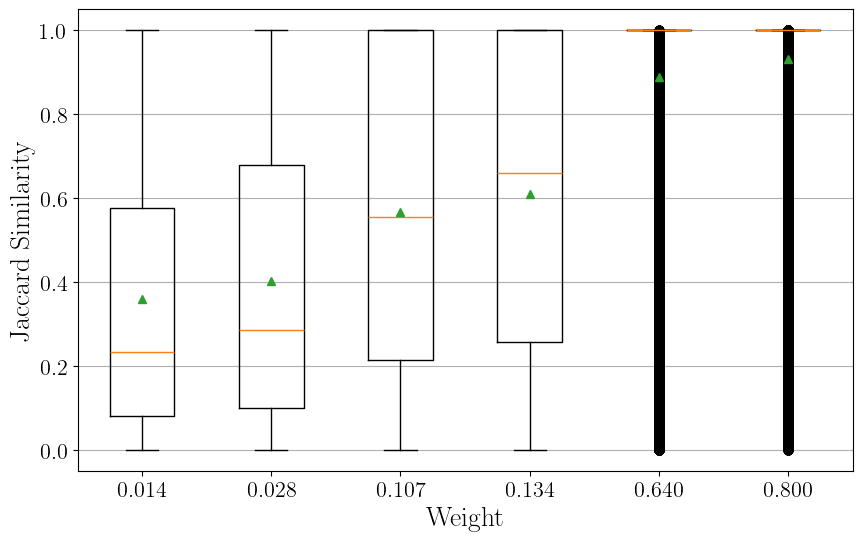

In [ ]:
selected_weights = [0.014, 0.028, 0.107, 0.134, 0.64, 0.8]
legend_fontsize = 20

# Find the indices of these weights in the original list
selected_indices = [np.where(weights == w)[0][0] for w in selected_weights if w in weights]

# Filter the Jaccard data for the selected weights
selected_jaccard_data = [jaccard_data[i] for i in selected_indices]


# Plot boxplots
plt.figure(figsize=(10, 6))

plt.boxplot(selected_jaccard_data, tick_labels=[f"{w:.3f}" for w in selected_weights], showmeans=True)

plt.xlabel("Weight", fontsize=legend_fontsize)
plt.ylabel("Jaccard Similarity", fontsize=legend_fontsize)

plt.grid(axis='y')
plt.xticks(fontsize=legend_fontsize-4)
plt.yticks(fontsize=legend_fontsize-4)

# Save the plot as a PDF
plot_name = "plots/jaccard-boxplots.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()

In [ ]:
global_ideal_time_diff = tradeoff_df[['time_difference_percentage']].quantile(0.9).values[0]
global_ideal_exposure_diff = tradeoff_df[['exposure_difference_percentage']].quantile(0.9).values[0]

print(global_ideal_time_diff)
print(global_ideal_exposure_diff)

In [ ]:
# Results container for hypervolume calculations
hypervolume_results = []

# Group by OD pair to compute hypervolume
od_groups = tradeoff_df.groupby(['origin', 'destination'])

for (origin, destination), group in od_groups:
    # Compute percentage-based differences for each route
    group['time_diff_percentage'] = ((group['least_cost_time'] - group['fastest_time']) / group['fastest_time']) * 100
    group['exposure_diff_percentage'] = ((group['least_cost_exposure'] - group['fastest_exposure']) / group['fastest_exposure']) * 100
    group['no_alternatives'] = group.nunique()['least_cost_path']
    # group['no_alternatives'] = group.nunique()['least_cost_path']

    # Compute local ideal points (worst-case percentages per OD pair)
    local_ideal_time_diff = max(group['time_diff_percentage'].max(), global_ideal_time_diff) # + 0.1 * (group['time_diff_percentage'].max() - group['time_diff_percentage'].min())
    local_ideal_exposure_diff = max(group['exposure_diff_percentage'].max(), global_ideal_exposure_diff)# + 0.1 * (group['exposure_diff_percentage'].max() - group['exposure_diff_percentage'].min())

    for _, row in group.iterrows():
        # Compute hypervolume using percentage differences
        hypervolume = (local_ideal_time_diff - row['time_diff_percentage']) * (local_ideal_exposure_diff - row['exposure_diff_percentage'])

        # Store results
        hypervolume_results.append({
            'origin': origin,
            'destination': destination,
            'weight': row['weight'],
            'hypervolume': hypervolume,
            'time_diff_percentage': row['time_diff_percentage'],
            'exposure_diff_percentage': row['exposure_diff_percentage'],
            'fastest_time': row['fastest_time'],
            'fastest_exposure': row['fastest_exposure'],
            'no_alternatives': row['no_alternatives']
        })

# Convert to DataFrame
hypervolume_df = pd.DataFrame(hypervolume_results)

# Save Pareto DataFrame
# hypervolume_df.to_csv(exawaro_path + "/tables/local_hypervolume_df.csv", index=False)

## Local weighting


In [ ]:
pareto_df = pd.read_csv(exawaro_path + "/tables/pareto_df.csv")

# Define the reference point as the worst-case scenario
reference_time = pareto_df['avg_time_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min())
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min())

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

hypervolume_df = pd.read_csv(exawaro_path + "/tables/local_hypervolume_df.csv")
hypervolume_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
1,31770712,3170958032,0.107,14.283439,0.336544,-0.747498,824.496196,0.609666,2
2,31770712,3170958032,0.086,14.283439,0.336544,-0.747498,824.496196,0.609666,2
3,31770712,3170958032,0.069,14.283439,0.336544,-0.747498,824.496196,0.609666,2
4,31770712,3170958032,0.055,14.283439,0.336544,-0.747498,824.496196,0.609666,2


In [ ]:
# Select the best route (highest hypervolume) for each OD pair
best_routes_df = hypervolume_df.loc[hypervolume_df.groupby(['origin', 'destination'])['hypervolume'].idxmax()]

best_routes_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
21,31770712,10072741345,0.086,105.072880,2.723170,-3.290149,1201.536608,0.605400,4
41,31770713,1375182252,0.069,10.282953,47.754934,-30.373887,816.180680,0.573832,3
73,31770713,1419172536,0.262,211.638325,13.592136,-36.160555,741.583795,0.571297,5
77,31770713,5579145657,0.107,148.649116,7.047676,-11.990539,1116.205298,0.458296,3


In [ ]:
# NOTE: Local-routing summary, distinct from MONET Table 1's simulation-step values.
# Summarise the selected local routes.

# Calculate the average time difference percentage
avg_time_diff = best_routes_df['time_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_exposure_diff = best_routes_df['exposure_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_weight = best_routes_df['weight'].mean()

# Print the results
print(f"Average Time Difference Percentage: {avg_time_diff:.2f}%")
print(f"Average Exposure Difference Percentage: {avg_exposure_diff:.2f}%")
print(f"Average Weight: {avg_weight:.3f}")


Average Time Difference Percentage: 5.78%
Average Exposure Difference Percentage: -15.42%
Average Weight: 0.137


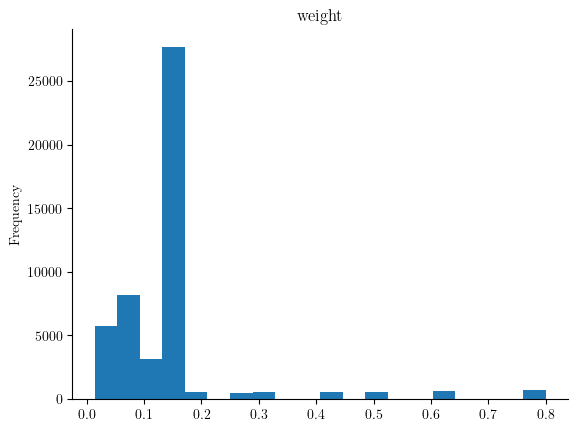

In [ ]:
from matplotlib import pyplot as plt
best_routes_df['weight'].plot(kind='hist', bins=20, title='weight')
# plt.yscale('log')
plt.gca().spines[['top', 'right',]].set_visible(False)

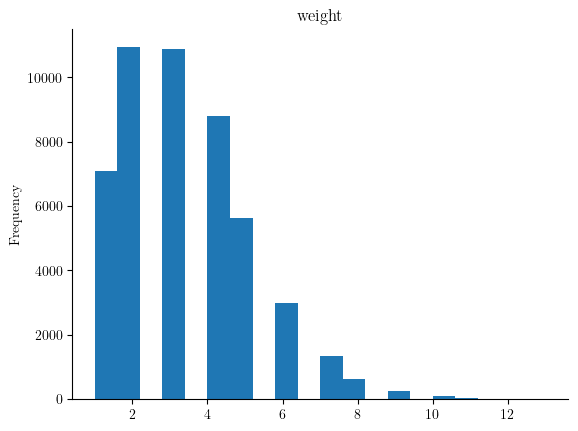

In [ ]:
from matplotlib import pyplot as plt
best_routes_df['fastest_exposure'].plot(kind='hist', bins=20, title='weight')
# plt.yscale('log')
plt.gca().spines[['top', 'right',]].set_visible(False)

## Global and local weighting: Pareto front


Compare the mean-difference Pareto fronts using both ideal points.


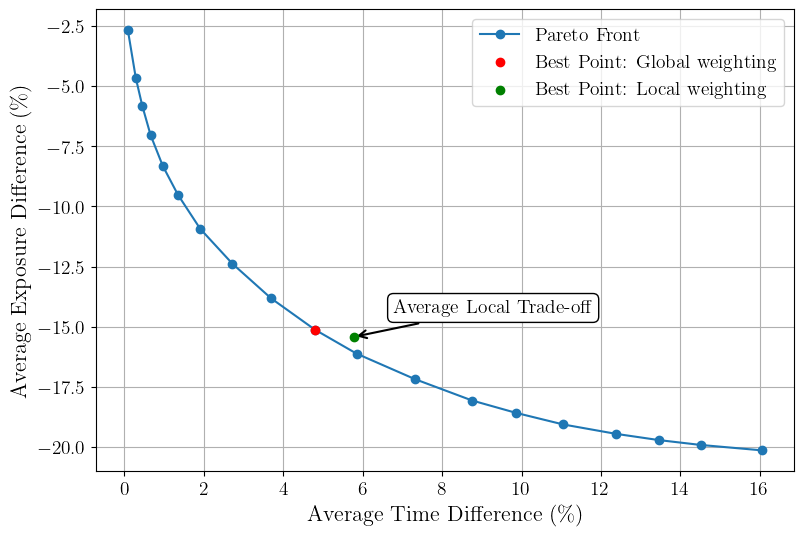

In [ ]:
# NOTE: Canonical average Pareto front: red is global weighting, green is per-OD local weighting. Used as MDM Fig. 9 and MONET Fig. 4.

fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point: Global weighting", zorder=5)
plt.scatter(avg_time_diff, avg_exposure_diff,
            color='green', label="Best Point: Local weighting", zorder=5)

# Add an arrow pointing to the green point
plt.annotate(
    "Average Local Trade-off",
    xy=(avg_time_diff, avg_exposure_diff),  # Point to annotate
    xytext=(avg_time_diff + 1, avg_exposure_diff + 1),
    arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),  # Arrow style
    fontsize=fontsize-6,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white")
)

plt.xlabel("Average Time Difference (\%)", fontsize=fontsize-4)
plt.ylabel("Average Exposure Difference (\%)", fontsize=fontsize-4)
plt.grid()
plt.legend()
plt.legend(fontsize=fontsize-6)
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
plot_name = "plots/pareto_avg_differences_v2.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()

Compare the median-difference Pareto fronts using both ideal points.


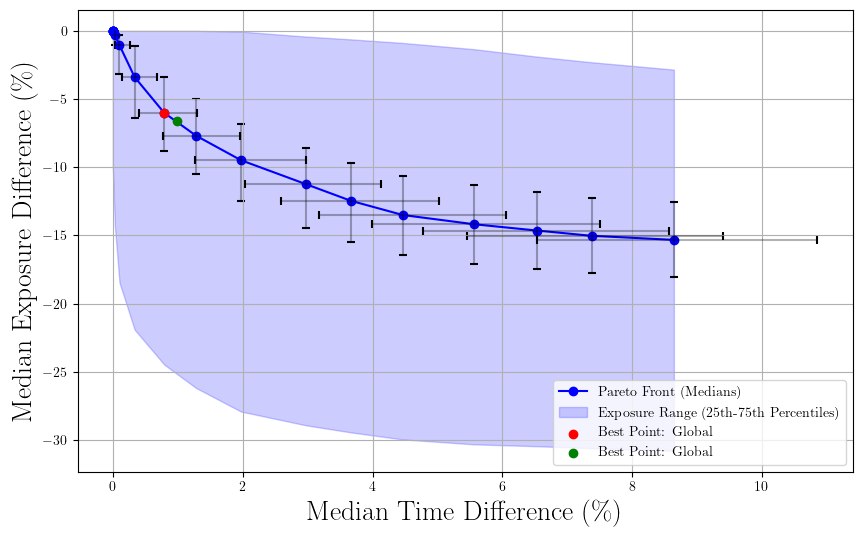

Plot saved as PDF: plots/pareto_avg_differences_v2.pdf


In [ ]:
# Plot Pareto front with the best point highlighted
plt.figure(figsize=(10, 6))

# Plot the medians
plt.plot(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    '-o', label="Pareto Front (Medians)", color='blue'
)

# Add shaded areas for exposure (25th-75th percentiles)
plt.fill_between(
    pareto_df['median_time_diff_percentage'],  # X-axis is the time difference medians
    pareto_df['exposure_25th'],               # Lower bound of exposure (25th percentile)
    pareto_df['exposure_75th'],               # Upper bound of exposure (75th percentile)
    color='blue', alpha=0.2, label="Exposure Range (25th-75th Percentiles)"
)

# Add vertical boxplot ranges for exposure
for i, (x, y, y45, y55) in enumerate(zip(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    pareto_df['exposure_45th'],
    pareto_df['exposure_55th']
)):
    # Boxplot-style vertical line
    plt.plot([x, x], [y45, y55], color='black', alpha=0.3)  # Vertical line for the range
    plt.scatter([x], [y45], color='black', marker='_')  # Lower quartile
    plt.scatter([x], [y55], color='black', marker='_')  # Upper quartile

# Add horizontal boxplot ranges for time differences
for i, (x, y, x45, x55) in enumerate(zip(
    pareto_df['median_time_diff_percentage'],
    pareto_df['median_exposure_diff_percentage'],
    pareto_df['time_45th'],
    pareto_df['time_55th']
)):
    plt.plot([x45, x55], [y, y], color='black', alpha=0.3)  # Horizontal line for time
    plt.scatter([x45], [y], color='black', marker='|')  # Lower quartile for time
    plt.scatter([x55], [y], color='black', marker='|')  # Upper quartile for time


# Highlight the best point - global
plt.scatter(
    best_point['median_time_diff_percentage'],
    best_point['median_exposure_diff_percentage'],
    color='red', label="Best Point: Global", zorder=5
)

# Highlight the best point - local
plt.scatter(best_med_time_diff, best_med_exp_diff,
    color='green', label="Best Point: Local", zorder=5
)

# Add labels and legend
plt.xlabel("Median Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Median Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid()
plt.legend()

plt.show()

# Print details of the best point
print("Best Point Based on Hypervolume:")
print(best_point)


## Global and local weighting: scatter plots


Compare changes in walking time and exposure separately.


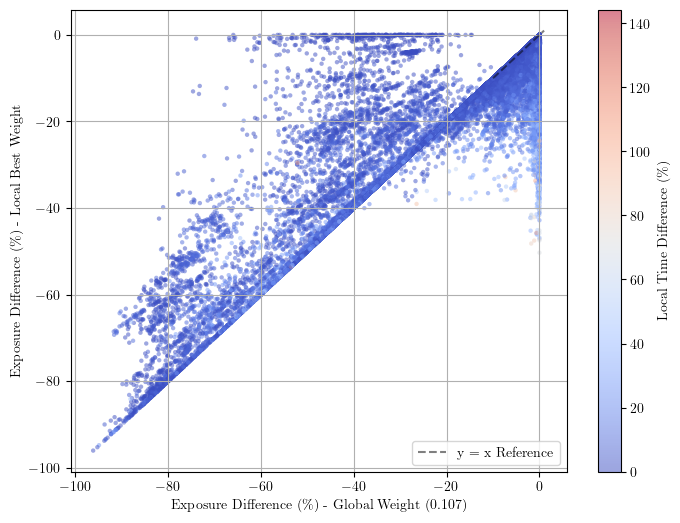

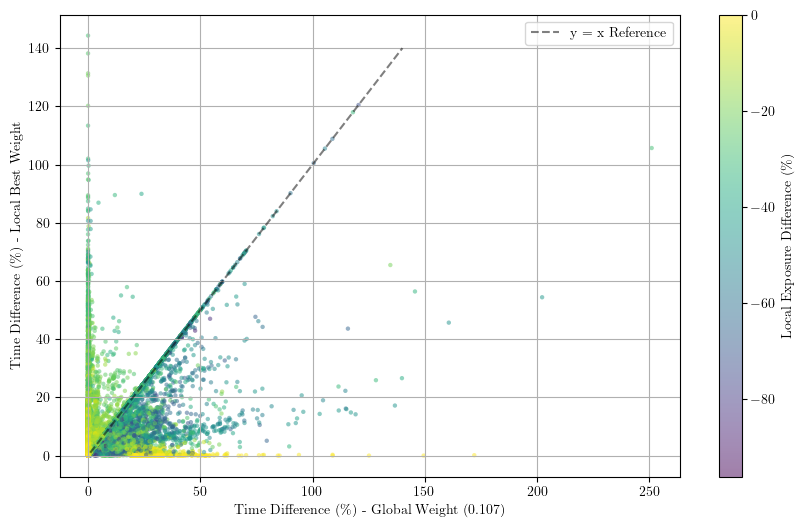

In [ ]:
# Step 1: Extract Global Ideal Weight (0.107) for Each OD Pair
global_df = tradeoff_df[tradeoff_df['weight'] == 0.107].copy()

# Step 2: Merge with Local Best Weight Results
comparison_df = best_routes_df.merge(
    global_df[['origin', 'destination', 'time_diff_percentage', 'exposure_diff_percentage']],
    on=['origin', 'destination'],
    suffixes=('_local', '_global')
)

# Step 3: Plot Exposure Differences (Global vs. Local Best Weight)
plt.figure(figsize=(8, 6))
sc1 = plt.scatter(
    comparison_df['exposure_diff_percentage_global'],
    comparison_df['exposure_diff_percentage_local'],
    c=comparison_df['time_diff_percentage_local'],  # Color by time difference
    cmap='coolwarm', alpha=0.5, edgecolors='none', s=10  # Small points to reduce clutter
)

# Add color bar for time difference
cbar = plt.colorbar(sc1)
cbar.set_label("Local Time Difference (\%)")

# Add diagonal reference line (y = x) for perfect alignment
plt.plot([-10, 1], [-10, 1], linestyle="--", color="black", alpha=0.5, label="y = x Reference")

# Labels and Title
plt.xlabel("Exposure Difference (\%) - Global Weight (0.107)")
plt.ylabel("Exposure Difference (\%) - Local Best Weight")
plt.legend()
plt.grid(True)


plt.show()

In [ ]:
# Step 4: Plot Time Differences (Global vs. Local Best Weight)
plt.figure(figsize=(10, 6))
sc2 = plt.scatter(
    comparison_df['time_diff_percentage_global'],
    comparison_df['time_diff_percentage_local'],
    c=comparison_df['exposure_diff_percentage_local'],  # Color by exposure difference
    cmap='viridis', alpha=0.5, edgecolors='none', s=10
)

# Add color bar for exposure difference
cbar = plt.colorbar(sc2)
cbar.set_label("Local Exposure Difference (\%)")

# Add diagonal reference line (y = x) for perfect alignment
plt.plot([1, 140], [1, 140], linestyle="--", color="black", alpha=0.5, label="y = x Reference")

# Labels and Title
plt.xlabel("Time Difference (\%) - Global Weight (0.107)")
plt.ylabel("Time Difference (\%) - Local Best Weight")
plt.legend()
plt.grid(True)


plt.show()


Compare changes in walking time and exposure together.


In [ ]:
# Step 1: Extract Global Weight Results (`w = 0.107`) for Each OD Pair
global_df = tradeoff_df[tradeoff_df['weight'] == 0.107][['origin', 'destination', 'least_cost_time', 'least_cost_exposure']].copy()
global_df = global_df.rename(columns={'least_cost_time': 'least_cost_time_global', 'least_cost_exposure': 'least_cost_exposure_global'})

# Step 2: Extract Local Best Weight Values (from `tradeoff_df` using `best_routes_df`)
best_routes_df = best_routes_df[['origin', 'destination', 'weight']]  # Keep only relevant columns
merged_df = best_routes_df.merge(tradeoff_df, on=['origin', 'destination', 'weight'], how='left')

# Rename columns for clarity
merged_df = merged_df.rename(columns={'least_cost_time': 'least_cost_time_local', 'least_cost_exposure': 'least_cost_exposure_local'})

# Step 3: Merge Global Weight Values (`w=0.107`) with Local Best Weight Values
comparison_df = merged_df.merge(global_df, on=['origin', 'destination'], how='left')

# Step 4: Compute Percentage Differences (w_local vs. w=0.107)
comparison_df['time_diff_percentage'] = ((comparison_df['least_cost_time_local'] - comparison_df['least_cost_time_global']) / comparison_df['least_cost_time_global']) * 100
comparison_df['exposure_diff_percentage'] = ((comparison_df['least_cost_exposure_local'] - comparison_df['least_cost_exposure_global']) / comparison_df['least_cost_exposure_global']) * 100

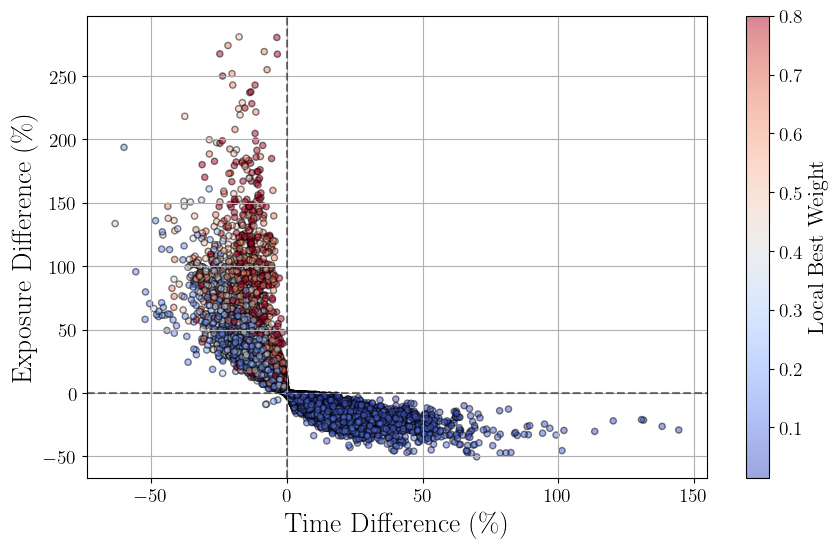

In [ ]:
# Step 5: Scatter Plot of Time vs. Exposure Differences (Local Best vs. w=0.107)
plt.figure(figsize=(10, 6))

legend_fontsize = 20

sc = plt.scatter(
    comparison_df['time_diff_percentage'],
    comparison_df['exposure_diff_percentage'],
    c=comparison_df['weight'],  # Color by local best weight
    cmap='coolwarm', alpha=0.5, edgecolors='k',
    s=20  # Scale size by exposure difference
)         #  + abs(comparison_df['exposure_diff_percentage'])

# Add color bar for local best weight
cbar = plt.colorbar(sc)
cbar.set_label("Local Best Weight", fontsize=legend_fontsize-4)
cbar.ax.tick_params(labelsize=legend_fontsize-6)

# Add vertical and horizontal reference lines
plt.axvline(0, color='black', linestyle="--", alpha=0.5)
plt.axhline(0, color='black', linestyle="--", alpha=0.5)

# Ticks
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)

# Labels and Title
plt.xlabel("Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid(True)

# Save the plot as a PDF
plot_name = "plots/global_vs_local_scatter.pdf"
plt.show()


## Global and local weighting: spatial differences


In [ ]:
# NOTE: Broad exception handling skips malformed route lists; retained from the original exploratory code.
from collections import Counter
import ast  # Converts string representation of lists back into actual lists

# Convert route paths from string format to actual lists
def parse_route(route):
    if isinstance(route, str):  # If it's stored as a string, convert it to a list
        try:
            return ast.literal_eval(route)  # Safely parse the list
        except:
            return []  # Return an empty list for corrupt data
    return route  # If already a list, return as is

# Apply the function to convert stored routes
tradeoff_df['fastest_path'] = tradeoff_df['fastest_path'].apply(parse_route)
tradeoff_df['least_cost_path'] = tradeoff_df['least_cost_path'].apply(parse_route)

In [ ]:
# Step 1: Merge tradeoff_df (contains fastest_path and least_cost_path) with best_routes_df
merged_df = best_routes_df.merge(
    tradeoff_df[['origin', 'destination', 'fastest_path', 'weight', 'least_cost_path']],
    on=['origin', 'destination', 'weight'],  # Ensure we match the correct least_cost_path for the weight
    how='left'
)

# Step 2: Extract Routes for w=1 (fastest) and w_optimal (global best weight)
routes_fastest = merged_df['fastest_path']
routes_optimal = merged_df['least_cost_path']

# Flatten paths to count occurrences of each edge
edges_fastest = [tuple(pair) for route in routes_fastest for pair in zip(route[:-1], route[1:])]
edges_optimal = [tuple(pair) for route in routes_optimal for pair in zip(route[:-1], route[1:])]

# Count occurrences of each road segment in both routing strategies
frequency_fastest = Counter(edges_fastest)
frequency_optimal = Counter(edges_optimal)

# Step 3: Compute the Difference in Usage
edge_diff = {}
for edge in set(frequency_fastest.keys()).union(set(frequency_optimal.keys())):
    edge_diff[edge] = frequency_optimal.get(edge, 0) - frequency_fastest.get(edge, 0)

# Normalize the differences for color mapping
max_abs_diff = max(abs(v) for v in edge_diff.values())  # Normalize by max absolute difference

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Print a few graph node IDs.
print("Example nodes from graph:", list(graph.nodes)[:10])

# Filter out invalid edges before processing
cleaned_edges = []
for edge in edge_diff.keys():
    try:
        u, v = edge
        # u, v = u.strip(), v.strip()  # Remove any extra spaces or unwanted characters

        # Convert to integer if needed
        if isinstance(list(graph.nodes)[0], int):
            u, v = int(u), int(v)

        # Ensure nodes exist before adding to cleaned list
        if u in graph.nodes and v in graph.nodes:
            cleaned_edges.append((u, v))
        else:
            print(f"Skipping edge {edge} - Node(s) not found in graph")

    except ValueError:
        print(f"Skipping edge {edge} - Corrupt data found")

# Normalize the differences for color mapping
max_abs_diff = max(abs(edge_diff[edge]) for edge in cleaned_edges) if cleaned_edges else 1

Example nodes from graph: [31770712, 31770713, 31770715, 31770716, 31770719, 31770722, 31770726, 31770727, 31770728, 31770729]
Skipping edge (7603565670, 7603565672) - Node(s) not found in graph
Skipping edge (7603565671, 7603565672) - Node(s) not found in graph
Skipping edge (11480659061, 11480659056) - Node(s) not found in graph
Skipping edge (7603565665, 2483822741) - Node(s) not found in graph
Skipping edge (2483822742, 7603565665) - Node(s) not found in graph
Skipping edge (11480659057, 11480659056) - Node(s) not found in graph
Skipping edge (11480659063, 11480659062) - Node(s) not found in graph
Skipping edge (11523670732, 11523670734) - Node(s) not found in graph
Skipping edge (7603565672, 7603565673) - Node(s) not found in graph
Skipping edge (11480659062, 11480659063) - Node(s) not found in graph
Skipping edge (7603565665, 2483822742) - Node(s) not found in graph
Skipping edge (11523670734, 11523670732) - Node(s) not found in graph
Skipping edge (2483822741, 7603565665) - Node

In [ ]:
max_abs_diff = max(abs(v) for v in edge_diff.values()) if edge_diff else 1  # Normalize values

for edge, diff in edge_diff.items():
    if graph.has_edge(*edge):
        graph[edge[0]][edge[1]][0]['color'] = 'grey' if diff is None or diff == 0 else ('green' if diff > 0 else 'red')
        graph[edge[0]][edge[1]][0]['width'] = 1 + (abs(diff) / max_abs_diff) * 3  # Scale width

In [ ]:
edge_colors = [
    graph[u][v][0].get('color', 'grey') if isinstance(graph[u][v][0].get('color', 'grey'), str) else 'grey'
    for u, v in graph.edges()
]


In [ ]:
print(set(type(c) for c in edge_colors))  # Should only contain <class 'str'>


{<class 'str'>}


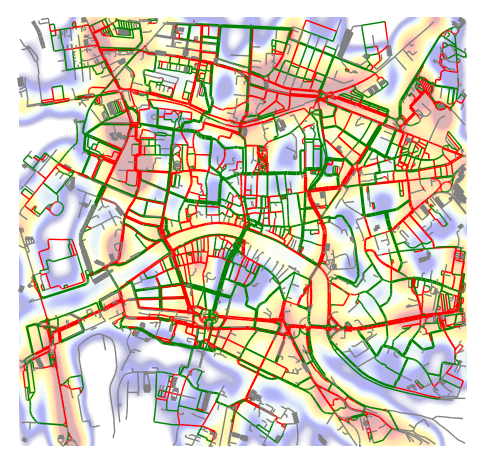

In [ ]:
import osmnx as ox
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Step 1: Define Custom Colormap
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'white'),
    (0.03, 'darkblue'),
    (0.07, 'blue'),
    (0.12, 'lightblue'),
    (0.20, 'lightyellow'),
    (0.30, 'yellow'),
    (0.40, 'gold'),
    (0.55, 'orange'),
    (0.70, 'darkorange'),
    (0.75, 'orangered'),
    (0.90, 'red'),
    (1.00, 'darkred'),
], N=256)

# Step 2: Compute Log-Transformed Concentration Values
logged_concentration_map = np.log1p(concentration_map)  # log1p to avoid log(0) issues

# Step 3: Normalize Values for Better Visualization
log_norm = Normalize(vmin=np.percentile(logged_concentration_map, 5), vmax=np.percentile(logged_concentration_map, 95))  # Clip outliers

# Step 4: Create figure and axis
fig, ax = plt.subplots(figsize=(6, 6))

im = ax.imshow(logged_concentration_map, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap=cmap, norm=log_norm, alpha=0.3)

# Add a colorbar linked to the image.
# cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
# cbar.set_label("Log-Scaled Concentration")

# Step 6: Fix Edge Colors and Plot the Road Network
edge_colors = [
    graph[u][v][0].get('color', 'grey') if isinstance(graph[u][v][0].get('color', 'grey'), str) else 'grey'
    for u, v in graph.edges()
]

edge_widths = [float(graph[u][v][0].get('width', 0.5)) for u, v in graph.edges()]

ox.plot_graph(
    graph, ax=ax, node_size=0, edge_color=edge_colors, edge_linewidth=edge_widths, show=False, close=False
)

# Step 7: Show the Plot

# Save the plot as a PDF
plot_name = "plots/road_usage_difference.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()


## Concentration map


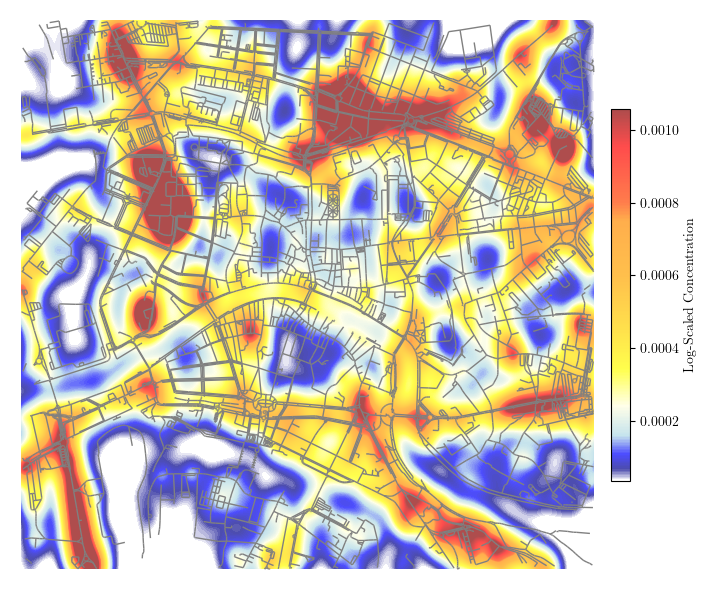

In [ ]:
# NOTE: Canonical concentration_map_new.pdf producer; cell 103 is the earlier duplicate.
# Step 1: Compute Log-Transformed Concentration Values
logged_concentration_map = np.log1p(concentration_map)  # log1p to avoid log(0) issues

# Step 2: Normalize Values for Better Visualization
log_norm = Normalize(vmin=np.percentile(logged_concentration_map, 5), vmax=np.percentile(logged_concentration_map, 95))  # Clip outliers

# Step 3: Define the Custom Colormap (same as before)
cmap = LinearSegmentedColormap.from_list('custom_colormap', [
    (0.00, 'white'),
    (0.03, 'darkblue'),
    (0.07, 'blue'),
    (0.12, 'lightblue'),
    # (0.15, 'lemonchiffon'),
    (0.20, 'lightyellow'),
    (0.30, 'yellow'),
    (0.40, 'gold'),
    (0.55, 'orange'),
    (0.70, 'darkorange'),
    (0.75, 'orangered'),
    (0.90, 'red'),
    (1.00, 'darkred'),
    # (1.00, 'black')
], N=256)

# Step 4: Plot the Log-Transformed Concentration Map
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(logged_concentration_map, extent=[xmin, xmax, ymin, ymax], origin='lower', cmap=cmap, norm=log_norm, alpha=0.7)

ox.plot_graph(
    graph, ax=ax, node_size=0, edge_color='gray', edge_linewidth=1, show=False, close=False
)

# Add a colorbar linked to the image.
cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.01)  # Ensure colorbar is linked to the correct axis
cbar.set_label("Log-Scaled Concentration")


# Save the plot as a PDF
plot_name = "plots/concentration_map_new.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()


# Demand simulation

Origin-destination matrices are generated for residents, commuters and tourists.


In [150]:
# NOTE: Building data preparation for building-volume OD generation; supports MONET inputs.
# Define the area of interest
place_name = "Pisa, Pisa, Italy"

# Define residential building types
residential_tags = ["residential", "apartments", "house", "detached", "semidetached_house", "terrace", "dormitory"]


In [151]:
buildings = ox.features_from_bbox(
    (xmin, ymin, xmax, ymax),
     {"building": True}).to_crs("EPSG:32632")

print(f"the number of all buildings: {len(buildings)}")



the number of all buildings: 5999


## Data preparation


Remove buildings without a valid footprint and compute their area.


In [141]:
import shapely.geometry

# Filter: Keep only rows where geometry is a Polygon or MultiPolygon
buildings = buildings[buildings.geometry.apply(lambda g: g.geom_type in ["Polygon", "MultiPolygon"])].reset_index(drop=True)

print(f"Number of polygon buildings: {len(buildings)}")

Number of polygon buildings: 5997


In [142]:
# Compute building footprint area in square meters
buildings["area_sqm"] = buildings.geometry.area

In [143]:
# Display those destinations
invalid_buildings = buildings[buildings["area_sqm"].isna() | (buildings["area_sqm"] <= 0)]
print(f"Number of destinations with NaN or zero surface area: {len(invalid_buildings)}")

Number of destinations with NaN or zero surface area: 0


Retrieve floor counts, replace missing values with the average, and compute building volume.


In [144]:
# Step 1: Check unique values in 'building:levels'
print(buildings["building:levels"].unique())

# Step 2: Convert to float safely, setting errors='coerce' to replace text with NaN
if "building:levels" in buildings.columns:
    buildings["num_floors"] = pd.to_numeric(buildings["building:levels"], errors="coerce")
else:
    buildings["num_floors"] = None  # Assign None if the column is missing

# Step 3: Verify the cleaned output
buildings[["building:levels", "num_floors"]].dropna().head()

['3' nan '7' '2' '4' '1' '5' '6' '8' '10' '9']


,building:levels,num_floors
0,3,3.0
12,7,7.0
13,2,2.0
14,3,3.0
15,2,2.0


In [145]:
# Count buildings with NaN floors
nan_floors = buildings["num_floors"].isna().sum()
print(f"Number of buildings with NaN: {nan_floors} ({nan_floors/len(buildings)*100:.2f}%)")

Number of buildings with NaN: 4590 (76.54%)


In [146]:
# Step 1: Compute the average number of floors (ignoring NaN values)
avg_floors = buildings["num_floors"].mean()
print(f"Each building has an average of {avg_floors:.1f} floors.")

Each building has an average of 3.1 floors.


In [147]:
# NOTE: Warning from fill-on-copy in exploratory building preprocessing; paper inputs are saved in later cells.
# Step 2: Fill NaN values in num_floors with the average value
buildings["num_floors"].fillna(3, inplace=True)

# Step 3: Drop buildings with zero floors
buildings = buildings[buildings["num_floors"] > 0]
buildings = buildings.reset_index(drop=True) # Reset index
print(f"Number of buildings after replacing NaNs and dropping zero-floor buildings: {len(buildings)}")

Number of buildings after replacing NaNs and dropping zero-floor buildings: 5997


<ipython-input-147-03251bd008de>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  buildings["num_floors"].fillna(3, inplace=True)


In [148]:
# Compute estimated total building volume
buildings["volume"] = buildings["area_sqm"] * buildings["num_floors"]
buildings[['geometry', 'building', "name", 'amenity', "area_sqm", "num_floors", "volume"]].head()

,geometry,building,name,amenity,area_sqm,num_floors,volume
0,"POLYGON ((612289.92 4842191.795, 612321.324 48...",yes,Camposanto Monumentale,grave_yard,3727.389618,3.0,11182.168854
1,"POLYGON ((612833.188 4841675.352, 612834.08 48...",university,Palazzo della Carovana,NaN,2049.361670,3.0,6148.085011
2,"POLYGON ((612702.896 4841941.847, 612662.011 4...",yes,Palazzo dell'Arcivescovado,religion,2521.991054,3.0,7565.973163
3,"POLYGON ((612865.67 4840497.644, 612866.482 48...",yes,NaN,NaN,4219.217157,3.0,12657.651471
4,"POLYGON ((612595.176 4840269.877, 612591.376 4...",residential,Convento dei Cappuccini,monastery,2215.883993,3.0,6647.651978


## Resident trips

Origins are residential buildings and destinations are all buildings in the city. Trips are generated with a gravity model.


## Extract buildings


In [152]:
# NOTE: Failed bbox projection attempt; retained for provenance and not used for paper figures.
from shapely.geometry import box

# Step 3: Create bbox polygon in lat/lon and convert to UTM
bbox_poly = gpd.GeoSeries([box(xmin, ymin, xmax, ymax)], crs="EPSG:4326").to_crs(gdf_proj.crs)
xmin_proj, ymin_proj, xmax_proj, ymax_proj = bbox_poly.total_bounds


NameError: name 'gdf_proj' is not defined

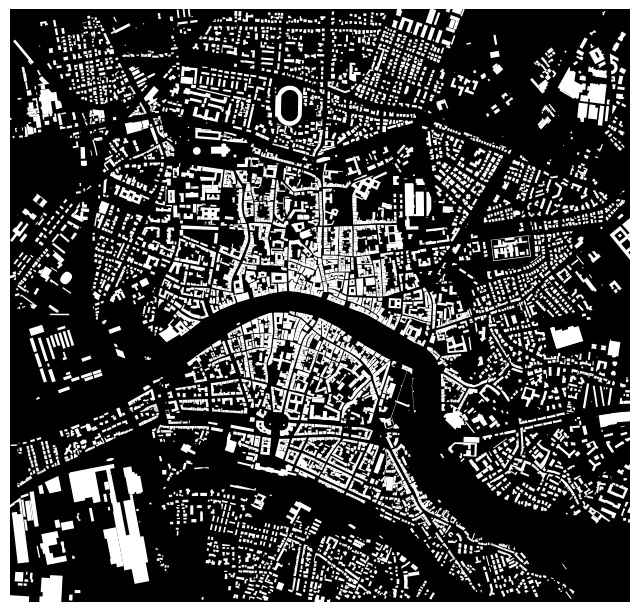

In [ ]:
# Project the GeoDataFrame
gdf_proj = ox.projection.project_gdf(buildings)

# Plot the buildings within the bounding box
fig, ax = ox.plot_footprints(
    gdf_proj,
    bbox=bbox_poly.total_bounds,  # must match projected CRS
    color="white",
    bgcolor="black",  # Black background
    dpi=100,
    save=False,
    show=True,
    close=True
)


Residential buildings


the number of residential buildings: 1513


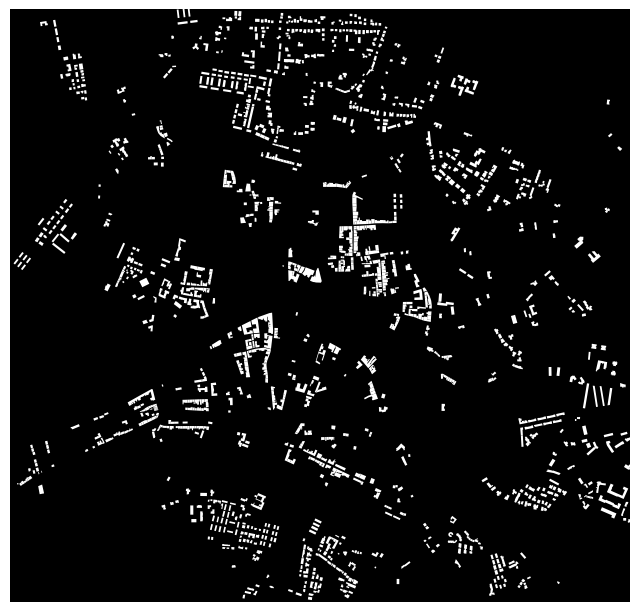

In [ ]:
# Filter buildings with any of the residential tags
residential_buildings = buildings[buildings["building"].isin(residential_tags)].copy()

print(f"the number of residential buildings: {len(residential_buildings)}")

# Project the GeoDataFrame
gdf_proj = ox.projection.project_gdf(residential_buildings)

# Plot the buildings within the bounding box
fig, ax = ox.plot_footprints(
    gdf_proj,
    bbox=bbox_poly.total_bounds,  # must match projected CRS
    color="white",
    bgcolor="black",  # Black background
    dpi=100,
    save=False,
    show=True,
    close=True
)


## Define attractiveness values


Distribute trips between origins and destinations.


The gravity model estimates trips from destination attractiveness and distance decay:

`T_ij = (k * O_i * D_j) / d**beta`


In [ ]:
# Convert to coordinate lists
origins = [(p.centroid.x, p.centroid.y) for p in residential_buildings.geometry if p.is_valid]
destinations = [(p.centroid.x, p.centroid.y) for p in buildings.geometry if p.is_valid]

In [ ]:
# NOTE: Gravity-model setup: O_i and D_j are origins and destination attractiveness, d_ij is distance, and beta controls distance decay.
from scipy.spatial.distance import cdist

# Step 1: Compute distances between all origin-destination pairs
distances = cdist(origins, destinations,
)  # Use great-circle if in lat/lon

# Corresponding volumes
O_i = residential_buildings["volume"].to_numpy()
D_j = buildings["volume"].to_numpy()

# Step 4: Apply Gravity Model
beta = 1.5  # Distance decay parameter (adjustable)

In [ ]:
# NOTE: Divide-by-zero warning comes from zero-distance pairs; retained from the original code.
# Gravity formula: T_ij = (O_i * D_j) / d_ij^beta
T_ij = (O_i[:, np.newaxis] * D_j[np.newaxis, :]) / (distances ** beta)

# Remove invalid entries
T_ij = np.nan_to_num(T_ij, nan=0, posinf=0, neginf=0)

# Apply Distance Filtering (Keep Only 20m ≤ d ≤ 1500m)
valid_mask = (distances >= 20) & (distances <= 1500)  # Boolean mask
T_ij = np.where(valid_mask, T_ij, 0)  # Set invalid distances to zero

# Step 6: Normalize Probability Matrix (Avoid Zero Sum Error)
if T_ij.sum() > 0:
    T_ij = T_ij / T_ij.sum()

# Step 7: Print Filtered Statistics
print(f"Total valid OD pairs (20m ≤ d ≤ 1500m): {np.count_nonzero(valid_mask)}")


<ipython-input-85-6898083ec21f>:2: RuntimeWarning: divide by zero encountered in divide
  T_ij = (O_i[:, np.newaxis] * D_j[np.newaxis, :]) / (distances ** beta)


Total valid OD pairs (20m ≤ d ≤ 1500m): 5119256


In [ ]:
# Flatten for sampling
flat_T = T_ij.flatten()
flat_od_pairs = [(o, d) for o in origins for d in destinations]

# Sample trips
num_trips = 10000  # Sampled resident trips
sampled_noise_od = random.choices(flat_od_pairs, weights=flat_T, k=num_trips)

# Save to DataFrame
noise_df = pd.DataFrame(sampled_noise_od, columns=["origin", "destination"])
noise_df.head()

,origin,destination
0,"(613003.6301843649, 4840562.621715667)","(612759.7147209013, 4840572.464144633)"
1,"(613730.3945988681, 4842424.002356773)","(612784.749957266, 4842187.403278197)"
2,"(612490.2502233483, 4841921.59174139)","(612914.0158261207, 4840632.775132803)"
3,"(612580.3946728343, 4840102.152897182)","(612644.4568693641, 4840058.938360877)"
4,"(612537.9478287915, 4840608.399665445)","(612954.4248895287, 4840725.646586558)"


In [ ]:
import pyproj

# Build transformer
project = pyproj.Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True)

# Apply transformation to origin and destination columns
noise_df[["origin_lon", "origin_lat"]] = noise_df["origin"].apply(lambda p: pd.Series(project.transform(*p)))
noise_df[["dest_lon", "dest_lat"]] = noise_df["destination"].apply(lambda p: pd.Series(project.transform(*p)))


In [ ]:
# NOTE: Map generated OD points to OSM graph nodes consumed by exawaro/main.py.
# Get nearest node IDs
noise_df["origin_node"] = ox.distance.nearest_nodes(graph, X=noise_df["origin_lon"], Y=noise_df["origin_lat"])
noise_df["destination_node"] = ox.distance.nearest_nodes(graph, X=noise_df["dest_lon"], Y=noise_df["dest_lat"])
noise_df.head()

,origin,destination,origin_lon,origin_lat,dest_lon,dest_lat,origin_node,destination_node
0,"(613003.6301843649, 4840562.621715667)","(612759.7147209013, 4840572.464144633)",10.402645,43.709484,10.399621,43.709610,5022182078,253556308
1,"(613730.3945988681, 4842424.002356773)","(612784.749957266, 4842187.403278197)",10.412057,43.726128,10.400270,43.724143,9705969261,6291016100
2,"(612490.2502233483, 4841921.59174139)","(612914.0158261207, 4840632.775132803)",10.396559,43.721795,10.401548,43.710129,3461598156,10719520529
3,"(612580.3946728343, 4840102.152897182)","(612644.4568693641, 4840058.938360877)",10.397297,43.705404,10.398083,43.705005,279535284,1596063928
4,"(612537.9478287915, 4840608.399665445)","(612954.4248895287, 4840725.646586558)",10.396876,43.709967,10.402069,43.710959,10917714279,11479403452


In [ ]:
# NOTE: Saved CSV is an input to exawaro/main.py; the restricted data itself is not redistributed.
noise_df.to_csv(exawaro_path + "tables/noise_od_pairs_pisa.csv", index=False)
# The index=False argument prevents the dataframe index from being written to the file.

## Compute route trade-offs


In [ ]:
noise_df = noise_df[["origin_node", "destination_node"]]

In [ ]:
# Remove null or self trips.
valid_df = noise_df.dropna(subset=["origin_node", "destination_node"])
valid_df = valid_df[valid_df["origin_node"] != valid_df["destination_node"]]


In [ ]:
od_pairs = list(zip(valid_df["origin_node"], valid_df["destination_node"]))


In [ ]:
print(f"Total valid OD pairs: {len(od_pairs)}")
od_pairs[:5]


Total valid OD pairs: 9833


[(5022182078, 253556308),
 (9705969261, 6291016100),
 (3461598156, 10719520529),
 (279535284, 1596063928),
 (10917714279, 11479403452)]

In [ ]:
od_pairs_list = [list(pair) for pair in od_pairs]


In [ ]:
# Generate the first table with detailed routing results

for weight in weights:
    detailed_results = []
    print(f"Routing with weight: {weight}")
    routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs_list, least_cost_weight=weight)
    results_df = pd.DataFrame(routing_results)

    for _, row in results_df.iterrows():
        # Extract route details
        detailed_results.append({
            'origin': row['origin'],
            'destination': row['destination'],
            'weight': weight,

            'fastest_path' : row['fastest_path'],
            'least_cost_path': row['least_cost_path'],

            'least_cost_time': row['least_cost_time'],
            'fastest_time': row['fastest_time'],

            'least_cost_exposure': row['least_cost_exposure'],
            'fastest_exposure': row['fastest_exposure'],

            'similarity': row['similarity']
        })

    # Convert to DataFrame
    detailed_df = pd.DataFrame(detailed_results)
    detailed_df.to_csv(exawaro_path+f"tables/routing_results_{weight}_{num_trips}_noise_pairs.csv", index=False)


Routing with weight: 0.8


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:36<00:00, 62.88it/s]


Routing with weight: 0.64


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:35<00:00, 63.28it/s]


Routing with weight: 0.512


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:37<00:00, 62.52it/s]


... (26 outputs left out)

Routing with weight: 0.023


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:35<00:00, 63.16it/s]


Routing with weight: 0.018


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:35<00:00, 63.12it/s]


In [ ]:
import os

# Specify the directory where the files are located
directory = exawaro_path + "tables/"
print(os.listdir(directory))

# Gather all files matching the pattern
files = [f for f in os.listdir(directory)
if f.startswith("routing_results_") and
         f.endswith("10000_noise_pairs.csv")]
print(files)

# Initialize an empty list to store DataFrames
dataframes = []

# Loop through the files and read them into DataFrames
for file in files:
    file_path = os.path.join(directory, file)
    df = pd.read_csv(file_path)  # Adjust the function if your file isn't CSV (e.g., pd.read_excel for Excel files)
    dataframes.append(df)

# Concatenate all DataFrames
tradeoff_df = pd.concat(dataframes, ignore_index=True)
tradeoff_df.head()

['.ipynb_checkpoints', 'routing_results_0.134_50000_pairs.csv', 'routing_results_0.107_50000_pairs.csv', 'routing_results_0.086_50000_pairs.csv', 'routing_results_0.069_50000_pairs.csv', 'routing_results_0.055_50000_pairs.csv', 'routing_results_0.044_50000_pairs.csv', 'routing_results_0.035_50000_pairs.csv', 'routing_results_0.028_50000_pairs.csv', 'routing_results_0.023_50000_pairs.csv', 'routing_results_0.018_50000_pairs.csv', 'routing_results_0.014_50000_pairs.csv', 'routing_results_0.8_50000_pairs.csv', 'routing_results_0.64_50000_pairs.csv', 'routing_results_0.512_50000_pairs.csv', 'routing_results_0.41_50000_pairs.csv', 'routing_results_0.328_50000_pairs.csv', 'routing_results_0.262_50000_pairs.csv', 'routing_results_0.21_50000_pairs.csv', 'routing_results_0.168_50000_pairs.csv', 'routing_results_pisa_50000_pairs.csv', 'pareto_df.csv', 'local_hypervolume_df.csv', 'noise_df.csv', 'workers_students_od_pairs_df.csv', 'pisa_places_with_ratings.csv', 'pisa_accomodations_with_ratings.c

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity
0,5022182078,253556308,0.8,"[5022182078, 253555981, 10880438174, 253555982...","[5022182078, 253555981, 10880438174, 253555982...",208.069954,208.069954,0.103116,0.103116,1.000000
1,9705969261,6291016100,0.8,"[9705969261, 9705969253, 9705969255, 970596925...","[9705969261, 9705969253, 9705969255, 970596925...",997.700701,948.077036,0.962541,2.348502,0.198595
2,3461598156,10719520529,0.8,"[3461598156, 3461598157, 3461598158, 334655532...","[3461598156, 3461598157, 3461598158, 334655532...",1303.182465,1303.182465,0.600125,0.600125,1.000000
3,279535284,1596063928,0.8,"[279535284, 9288179885, 245925396, 245925395, ...","[279535284, 9288179885, 245925396, 245925395, ...",228.082111,228.082111,0.025577,0.025577,1.000000
4,10917714279,11479403452,0.8,"[10917714279, 9882762262, 11523685581, 1088043...","[10917714279, 9882762262, 11523685581, 1088043...",334.454696,334.454696,0.188123,0.188123,1.000000


In [ ]:
# Save the concatenated result into a single file
output_file = os.path.join(directory, "routing_results_pisa_10000_noise.csv")
tradeoff_df.to_csv(output_file, index=False)

print(f"Files concatenated and saved to {output_file}")

Files concatenated and saved to /content/drive/MyDrive/Colab Notebooks/exawaro/pedestrian/tables/routing_results_pisa_10000_noise.csv


In [ ]:
tradeoff_df[['similarity', 'least_cost_time', 'fastest_time', 'least_cost_exposure', 'fastest_exposure']].describe()

,similarity,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure
count,170262.000000,170262.000000,170262.000000,170262.000000,170262.000000
mean,0.787398,536.352770,513.033577,0.211139,0.266028
std,0.337443,446.360102,417.525382,0.221115,0.356636
min,0.000000,0.915218,0.915218,0.000238,0.000238
25%,0.587477,168.806850,168.292698,0.049997,0.050489
50%,1.000000,412.668314,403.625623,0.144047,0.152395
75%,1.000000,815.866578,785.211948,0.297587,0.335690
max,1.000000,2749.637152,2732.906697,3.093343,3.093343


## Analysis


In [ ]:
# load calculated routes before the analysis of trade-offs

tradeoff_df = pd.read_csv(exawaro_path + "tables/routing_results_pisa_10000_noise.csv")
tradeoff_df['time_diff_percentage'] = ((tradeoff_df['least_cost_time'] - tradeoff_df['fastest_time']) / tradeoff_df['fastest_time']) * 100
tradeoff_df['exposure_diff_percentage'] = ((tradeoff_df['least_cost_exposure'] - tradeoff_df['fastest_exposure']) / tradeoff_df['fastest_exposure']) * 100

tradeoff_df.head()

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,5022182078,253556308,0.8,"[5022182078, 253555981, 10880438174, 253555982...","[5022182078, 253555981, 10880438174, 253555982...",208.069954,208.069954,0.103116,0.103116,1.000000,0.000000,0.000000
1,9705969261,6291016100,0.8,"[9705969261, 9705969253, 9705969255, 970596925...","[9705969261, 9705969253, 9705969255, 970596925...",997.700701,948.077036,0.962541,2.348502,0.198595,5.234138,-59.014693
2,3461598156,10719520529,0.8,"[3461598156, 3461598157, 3461598158, 334655532...","[3461598156, 3461598157, 3461598158, 334655532...",1303.182465,1303.182465,0.600125,0.600125,1.000000,0.000000,0.000000
3,279535284,1596063928,0.8,"[279535284, 9288179885, 245925396, 245925395, ...","[279535284, 9288179885, 245925396, 245925395, ...",228.082111,228.082111,0.025577,0.025577,1.000000,0.000000,0.000000
4,10917714279,11479403452,0.8,"[10917714279, 9882762262, 11523685581, 1088043...","[10917714279, 9882762262, 11523685581, 1088043...",334.454696,334.454696,0.188123,0.188123,1.000000,0.000000,0.000000


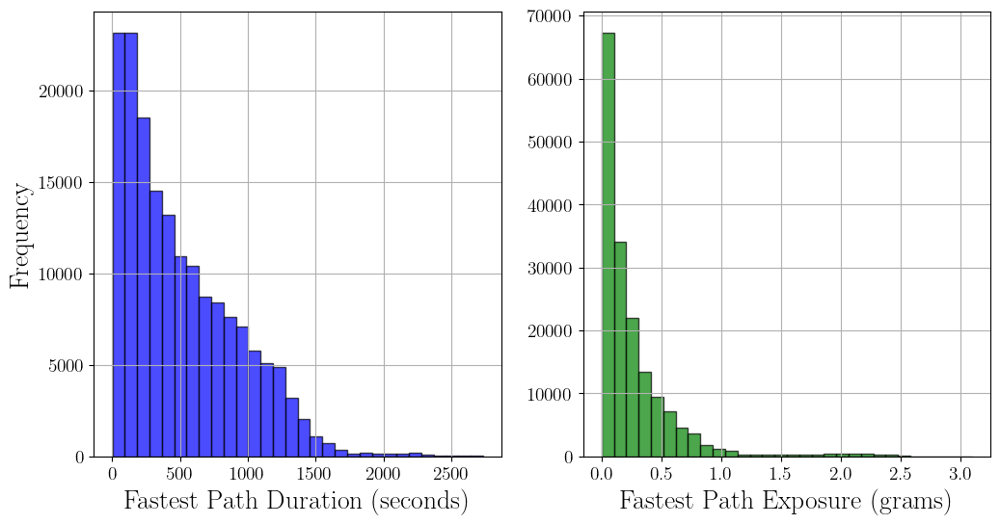

In [ ]:
# Fastest durations and exposures
fastest_durations = tradeoff_df['fastest_time']
fastest_exposures = tradeoff_df['fastest_exposure']

fontsize = 20

# Plot histograms
plt.figure(figsize=(12, 6))

# Histogram for fastest durations
plt.subplot(1, 2, 1)

plt.hist(fastest_durations, bins=30, color='blue', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Duration (seconds)', fontsize=fontsize)
plt.ylabel('Frequency', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)


# Histogram for fastest exposures
plt.subplot(1, 2, 2)

plt.hist(fastest_exposures, bins=30, color='green', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Exposure (grams)', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
# plot_name = "plots/distributions_noise.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()

In [ ]:
# Unique weights
weights = tradeoff_df['weight'].unique()

# Results container
pareto_results = []

# Iterate over each weight
for weight in weights:
    # Filter the DataFrame for the current weight
    filtered_df = tradeoff_df[tradeoff_df['weight'] == weight]

    # Calculate percentage differences
    time_diff = filtered_df['least_cost_time'] - filtered_df['fastest_time']
    exposure_diff = filtered_df['least_cost_exposure'] - filtered_df['fastest_exposure']

    time_diff_percentage = (time_diff / filtered_df['fastest_time']) * 100
    exposure_diff_percentage = (exposure_diff / filtered_df['fastest_exposure']) * 100

    # Replace infinities and NaNs with 0 for clean calculation
    time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    time_diff_percentage.fillna(0, inplace=True)
    exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    exposure_diff_percentage.fillna(0, inplace=True)

    # Store results for this weight
    pareto_results.append({
        'weight': weight,

        'avg_time_diff_percentage': time_diff_percentage.mean(),
        'avg_exposure_diff_percentage': exposure_diff_percentage.mean(),

        'median_time_diff_percentage': time_diff_percentage.median(),
        'median_exposure_diff_percentage': exposure_diff_percentage.median(),

        'time_45th': time_diff_percentage.quantile(0.45),
        'time_55th': time_diff_percentage.quantile(0.55),
        'exposure_45th': exposure_diff_percentage.quantile(0.45),
        'exposure_55th': exposure_diff_percentage.quantile(0.55),

        'time_25th': time_diff_percentage.quantile(0.25),
        'time_75th': time_diff_percentage.quantile(0.75),
        'exposure_25th': exposure_diff_percentage.quantile(0.25),
        'exposure_75th': exposure_diff_percentage.quantile(0.75),
    })

# Convert to DataFrame for plotting
pareto_df = pd.DataFrame(pareto_results)

# Sort Pareto DataFrame by weight
pareto_df = pareto_df.sort_values(by='weight', ascending=True)

# Reset the index.
pareto_df = pareto_df.reset_index(drop=True)

# Display Pareto DataFrame
pareto_df


,weight,avg_time_diff_percentage,avg_exposure_diff_percentage,median_time_diff_percentage,median_exposure_diff_percentage,time_45th,time_55th,exposure_45th,exposure_55th,time_25th,time_75th,exposure_25th,exposure_75th
0,0.018,8.138680,-10.310825,0.005704,-0.013263,0.0,0.276850,-0.854680,0.0,0.0,7.535249,-14.954497,0.0
1,0.023,7.537552,-10.171173,0.000000,0.000000,0.0,0.177523,-0.670357,0.0,0.0,6.644101,-14.312511,0.0
2,0.028,6.697547,-9.946180,0.000000,0.000000,0.0,0.111897,-0.418164,0.0,0.0,5.506042,-13.590826,0.0
3,0.035,5.916492,-9.708363,0.000000,0.000000,0.0,0.052733,-0.220607,0.0,0.0,4.555945,-12.735061,0.0
4,0.044,5.260567,-9.440586,0.000000,0.000000,0.0,0.020071,-0.076957,0.0,0.0,3.907273,-11.946505,0.0
5,0.055,4.600986,-9.101483,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,3.278192,-10.758245,0.0
6,0.069,3.848090,-8.581270,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,2.108886,-9.300852,0.0
7,0.086,2.989367,-7.878377,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,1.135835,-7.023635,0.0
8,0.107,2.498219,-7.361292,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.713218,-5.657661,0.0
9,0.134,2.024113,-6.767575,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.421634,-3.887074,0.0


In [ ]:
pareto_df = pd.read_csv(exawaro_path + "/tables/pareto_noise_trips.csv")

In [ ]:
# Define the reference point as the worst-case scenario
reference_time = pareto_df['avg_time_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min())
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min())

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

Best Point on Pareto Front (Highest Hypervolume):
weight                              0.107000
avg_time_diff_percentage            2.498219
avg_exposure_diff_percentage       -7.361292
median_time_diff_percentage         0.000000
median_exposure_diff_percentage     0.000000
time_45th                           0.000000
time_55th                           0.000000
exposure_45th                       0.000000
exposure_55th                       0.000000
time_25th                           0.000000
time_75th                           0.713218
exposure_25th                      -5.657661
exposure_75th                       0.000000
hypervolume                        35.481415
Name: 8, dtype: float64


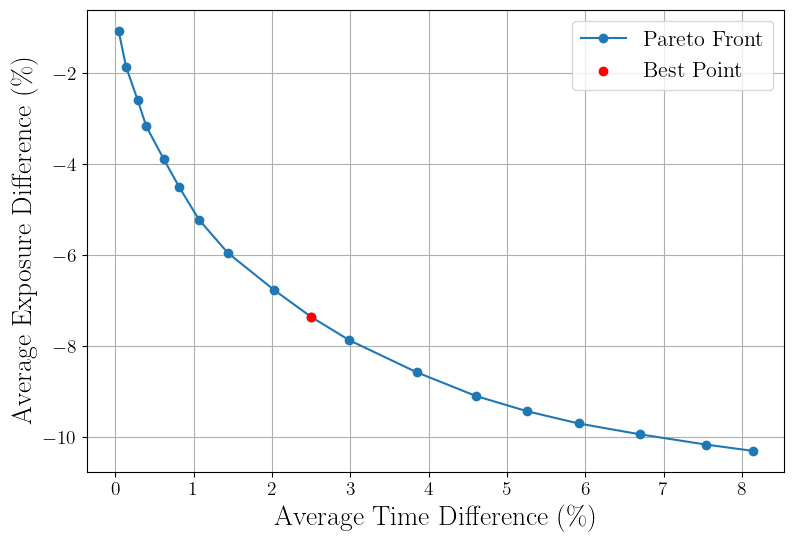

In [ ]:
# Print the best point
print("Best Point on Pareto Front (Highest Hypervolume):")
print(best_point)

legend_fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point", zorder=5)

plt.xlabel("Average Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Average Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid()
plt.legend(fontsize=legend_fontsize-4)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)

# Save the plot as a PDF
# plot_name = "plots/pareto_avg_differences_noise.pdf"
plt.show()


In [ ]:
# pareto_df = pd.read_csv(exawaro_path + "/tables/pareto_df.csv")

# Define the reference point as the worst-case scenario
reference_time = pareto_df['avg_time_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min())
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min())

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

# hypervolume_df = pd.read_csv(exawaro_path + "/tables/local_hypervolume_df.csv")
hypervolume_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
1,31770712,3170958032,0.107,14.283439,0.336544,-0.747498,824.496196,0.609666,2
2,31770712,3170958032,0.086,14.283439,0.336544,-0.747498,824.496196,0.609666,2
3,31770712,3170958032,0.069,14.283439,0.336544,-0.747498,824.496196,0.609666,2
4,31770712,3170958032,0.055,14.283439,0.336544,-0.747498,824.496196,0.609666,2


In [ ]:
# Select the best route (highest hypervolume) for each OD pair
best_routes_df = hypervolume_df.loc[hypervolume_df.groupby(['origin', 'destination'])['hypervolume'].idxmax()]

best_routes_df.head()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,31770712,3170958032,0.134,14.283439,0.336544,-0.747498,824.496196,0.609666,2
21,31770712,10072741345,0.086,105.072880,2.723170,-3.290149,1201.536608,0.605400,4
41,31770713,1375182252,0.069,10.282953,47.754934,-30.373887,816.180680,0.573832,3
73,31770713,1419172536,0.262,211.638325,13.592136,-36.160555,741.583795,0.571297,5
77,31770713,5579145657,0.107,148.649116,7.047676,-11.990539,1116.205298,0.458296,3


In [ ]:
# Summarise the selected local routes.

# Calculate the average time difference percentage
avg_time_diff = best_routes_df['time_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_exposure_diff = best_routes_df['exposure_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_weight = best_routes_df['weight'].mean()

# Print the results
print(f"Average Time Difference Percentage: {avg_time_diff:.2f}%")
print(f"Average Exposure Difference Percentage: {avg_exposure_diff:.2f}%")
print(f"Average Weight: {avg_weight:.3f}")


Average Time Difference Percentage: 5.78%
Average Exposure Difference Percentage: -15.42%
Average Weight: 0.137


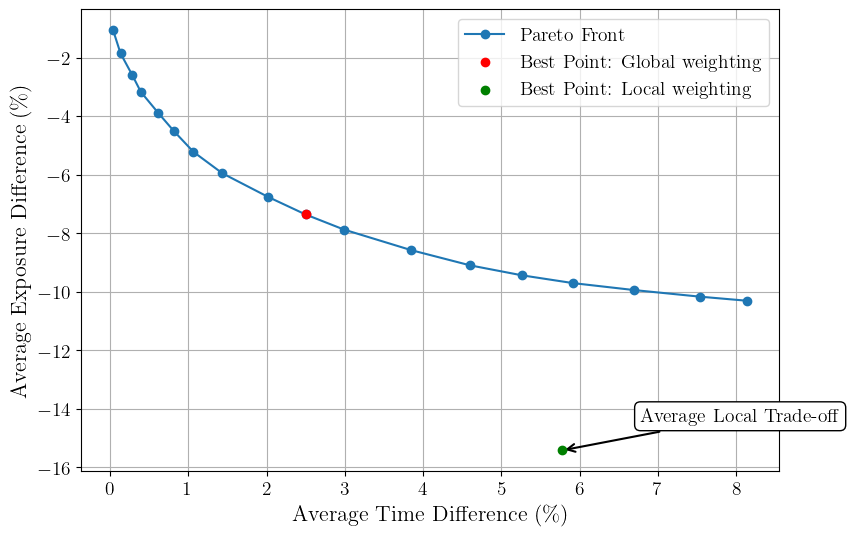

In [ ]:
# NOTE: Noise-scenario duplicate of the average Pareto plot; plot_name is inherited from cell 137 (plots/concentration_map_new.pdf), so this does not produce MDM Fig. 9.

fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point: Global weighting", zorder=5)
plt.scatter(avg_time_diff, avg_exposure_diff,
            color='green', label="Best Point: Local weighting", zorder=5)

# Add an arrow pointing to the green point
plt.annotate(
    "Average Local Trade-off",
    xy=(avg_time_diff, avg_exposure_diff),  # Point to annotate
    xytext=(avg_time_diff + 1, avg_exposure_diff + 1),
    arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),  # Arrow style
    fontsize=fontsize-6,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white")
)

plt.xlabel("Average Time Difference (\%)", fontsize=fontsize-4)
plt.ylabel("Average Exposure Difference (\%)", fontsize=fontsize-4)
plt.grid()
plt.legend()
plt.legend(fontsize=fontsize-6)
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
# plot_name = "plots/pareto_avg_differences_v2.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()

## Enrich building data from OpenStreetMap


Inspect the available building tags and amenities.


In [ ]:
list(buildings.columns) # display available tags/columns
# geometry, amenity, building, building:levels

['geometry',
 'building',
 'denomination',
 'historic',
 'name',
 'religion',
 'fixme',
 'ruins',
 'leisure',
 'shelter',
 'bunker_type',
 'landuse',
 'military',
 'abandoned:building',
 'addr:city',
 'addr:housenumber',
 'addr:postcode',
 'addr:street',
 'amenity',
 'cuisine',
 'website',
 'cafe',
 'contact:email',
 'contact:facebook',
 'contact:tripadvisor',
 'opening_hours',
 'payment:cash',
 'payment:debit_cards',
 'shop',
 'building:part',
 'fee',
 'height',
 'name:de',
 'name:en',
 'name:fr',
 'name:it',
 'name:ko',
 'toilets:wheelchair',
 'wheelchair',
 'wikidata',
 'wikimedia_commons',
 'wikipedia',
 'description',
 'loc_name',
 'name:es',
 'name:hi',
 'name:zh',
 'service_times',
 'start_date',
 'tourism',
 'aeroway',
 'air_conditioning',
 'operator',
 'smoking',
 'capacity',
 'sport',
 'check_date',
 'email',
 'internet_access',
 'phone',
 'source',
 'building:levels',
 'importance',
 'addr:country',
 'brand',
 'brand:wikidata',
 'public_transport',
 'roof:shape',
 'man_made'

In [ ]:
buildings['building'].unique()

array(['manufacture', 'cabin', 'yes', 'furnace', 'hut', 'bunker',
       'university', 'residential', 'school', 'church', 'public',
       'stable', 'grandstand', 'apartments', 'office', 'hospital',
       'sports_centre', 'industrial', 'commercial', 'roof', 'chapel',
       'cathedral', 'train_station', 'dormitory', 'hotel', 'house',
       'detached', 'retail', 'civic', 'transformer_tower', 'parking',
       'service', 'storage_tank', 'construction', 'warehouse', 'garage',
       'platform', 'greenhouse', 'shed', 'garages', 'kiosk',
       'semidetached_house', 'farm_auxiliary', 'kindergarten',
       'restaurant', 'government', 'pavilion', 'tower', 'ruins',
       'fire_station', 'gazebo', 'veranda', 'boathouse', 'terrace',
       'hall_of_residence', 'bridge', 'tent', 'no', 'barn', 'toilets',
       'hangar'], dtype=object)

In [ ]:
buildings['amenity'].unique()

array([nan, 'restaurant', 'grave_yard', 'religion', 'monastery',
       'university', 'police', 'research_institute', 'courthouse',
       'townhall', 'bank', 'conference_centre', 'parking',
       'community_centre', 'place_of_worship', 'bicycle_parking',
       'school', 'car_wash', 'theatre', 'post_office', 'canteen',
       'toilets', 'veterinary', 'clinic', 'pharmacy', 'arts_centre',
       'kindergarten', 'cinema', 'public_building', 'social_facility',
       'cafe', 'bar', 'conference_room', 'childcare', 'music_venue',
       'library', 'student_accommodation', 'fire_station', 'nightclub',
       'dentist', 'car_rental', 'shelter', 'camping', 'doctors',
       'post_depot'], dtype=object)

Some buildings have no name tag.


In [ ]:
buildings[buildings['name']=='Consiglio Nazionale delle Ricerche (CNR)']

,,geometry,building,denomination,historic,name,religion,fixme,ruins,leisure,shelter,...,name:nl,name:pl,name:pt,name:sk,name:sv,name:uk,opening_hours_1,short_name:pl,source:opening_hours,animal
element,id,,,,,,,,,,,,,,,,,,,,,
relation,1706322,"POLYGON ((10.42132 43.71933, 10.42164 43.71905...",yes,NaN,NaN,Consiglio Nazionale delle Ricerche (CNR),NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


These buildings can be identified from land-use tags.


In [ ]:
place_name = 'Pisa, Pisa, Italy'
areas = ox.features_from_place(
    place_name,
    {"landuse":'commercial'}
)

areas[areas['amenity']=='research_institute']

,,geometry,addr:city,addr:housenumber,addr:postcode,addr:street,amenity,barrier,fence_type,landuse,name,note,operator,operator:type,operator:wikidata,website,wikidata,wikipedia,phone,shop,type
element,id,,,,,,,,,,,,,,,,,,,,
way,23082352,"POLYGON ((10.42038 43.71838, 10.42034 43.71844...",Pisa,1,56124,Via Giuseppe Moruzzi,research_institute,fence,bars,commercial,Area della Ricerca CNR,landuse=commercial it's just a forcing to rend...,Consiglio Nazionale delle Ricerche,government,Q902464,http://www.area.pi.cnr.it/,Q24195954,it:Area della ricerca di Pisa,NaN,NaN,NaN


Infer building type from land use where possible.


## Commuter and student trips

Origins include residential buildings, transport hubs, parking areas and bus stops. Destinations are study and work buildings.


Transport hubs, parking areas and bus stops


In [ ]:
# Extract transportation hubs: train/bus stations and parking areas
train_stations = ox.features_from_place(place_name, {"railway": "station"}).to_crs("EPSG:32632")  # Train stations
bus_stations = ox.features_from_place(place_name, {"public_transport": "station"}).to_crs("EPSG:32632")  # Bus stations
parkings = ox.features_from_place(place_name, {"amenity":'parking'}).to_crs("EPSG:32632")


print(f"the number of bus stations: {len(bus_stations)}")
print(f"the number of train stations: {len(train_stations)}")
print(f"the number of parkings: {len(parkings)}")

the number of bus stations: 8
the number of train stations: 3
the number of parkings: 541


In [ ]:
# keep point geos with capacity
parkings[['geometry', 'access', 'amenity', 'parking', 'fee', 'name', 'capacity']].head()

geometry     access  amenity  \
element id                                                               
node    279133636   POINT (611685.327 4839736.945)  customers  parking   
        292066975    POINT (611417.771 4843602.73)        NaN  parking   
        364733819     POINT (612090.917 4840689.9)        yes  parking   
        656156169   POINT (603744.069 4833657.383)  customers  parking   
        1409174430  POINT (612709.453 4840639.152)        yes  parking   

                        parking  fee                                    name  \
element id                                                                     
node    279133636       surface  NaN                                     NaN   
        292066975           NaN  NaN                                     NaN   
        364733819       surface  yes                                     NaN   
        656156169           NaN  NaN                              Zona tende   
        1409174430  underground  yes  Parcheggio Piazza Vittorio Emanuele II   

                   capacity  
element id                   
node    279133636       NaN  
        292066975       NaN  
        364733819       NaN  
        656156169       NaN  
        1409174430      283

Research and education facilities


In [ ]:
educational_tags = ['school', 'university', 'research_institute']

educational_buildings = buildings[buildings["building"].isin(educational_tags)].copy()

print(f"the number of educational buildings: {len(educational_buildings)}")

the number of educational buildings: 79


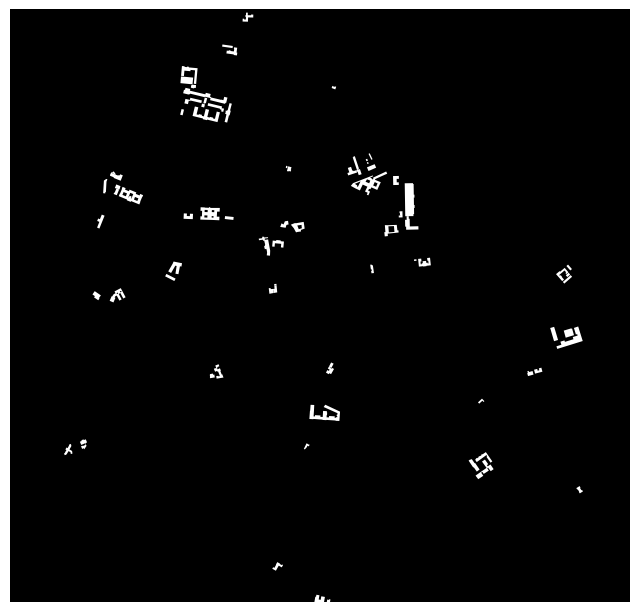

In [ ]:
# Project the GeoDataFrame
gdf_proj = ox.projection.project_gdf(educational_buildings)

# Plot the buildings within the bounding box
fig, ax = ox.plot_footprints(
    gdf_proj,
    bbox=bbox_poly.total_bounds,  # must match projected CRS
    color="white",
    bgcolor="black",  # Black background
    dpi=100,
    save=False,
    show=True,
    close=True
)


High schools


In [ ]:
# Extract schools and buildings
schools = ox.features_from_place(place_name, {"amenity": "school"}).to_crs("EPSG:32632")
print(f"the number of school amenities: {len(schools)}")

# Filter to high schools only (those with 'liceo' in the name)
highschools = schools[schools["name"].str.contains("liceo", case=False, na=False)].copy()
print(f"the number of high school amenities: {len(highschools)}")

# Spatial join: find buildings that intersect or contain these high schools
highschool_buildings = gpd.sjoin(buildings, highschools[["geometry", "name"]],
                                  how="inner", predicate="intersects")

# Drop duplicate buildings (in case multiple amenities fall in the same footprint)
highschool_buildings = highschool_buildings.drop_duplicates(subset="geometry").reset_index(drop=True)
print(f"the number of high school buildings: {len(highschool_buildings)}")

print(f"the unique number of high schools: {highschool_buildings[['name_right']].nunique()}")

the number of school amenities: 55
the number of high school amenities: 5
the number of high school buildings: 22
the unique number of high schools: name_right    4
dtype: int64


In [ ]:
highschool_buildings[['geometry', "name_right", "num_floors", "area_sqm", "volume"]].head(6)
# I suspect of amenities being included in the buildings list

,geometry,name_right,num_floors,area_sqm,volume
0,"POLYGON ((614116.98 4841170.386, 614136.869 48...","Liceo Scientifico ""Filippo Buonarroti"" e I.T.G...",3.0,12686.313740,38058.941221
1,"POLYGON ((612883.251 4840774.869, 612880.931 4...","Liceo Classico ""Galileo Galilei""",4.0,5933.030589,23732.122355
2,"POLYGON ((613121.901 4841983.706, 613131.597 4...",Liceo Giosuè Carducci,3.0,471.009679,1413.029037
3,"POLYGON ((612688.231 4841620.655, 612706.114 4...","Liceo Artistico ""F. Russoli""",3.0,1316.368017,3949.104050
4,"POLYGON ((612745.879 4841633.716, 612758.095 4...","Liceo Artistico ""F. Russoli""",3.0,274.299994,822.899982
5,"POLYGON ((612674.814 4841623.551, 612672.914 4...","Liceo Artistico ""F. Russoli""",3.0,100.008996,300.026989


In [ ]:
universities = ox.features_from_place(place_name, {"amenity": "university"}).to_crs("EPSG:32632")  # University buildings
print(f"the number of university buildings: {len(universities)}")
# research_centers = ox.features_from_place(place_name, {"amenity": "research_institution"})  # Research centers

the number of university buildings: 58


Other workplaces


In [ ]:
workplace_tags = ['hospital', 'industrial', 'clinic', 'office', 'shop', 'manufacture']

workplace_buildings = buildings[buildings["building"].isin(workplace_tags)].copy()

print(f"the number of workplace buildings: {len(workplace_buildings)}")

the number of workplace buildings: 51


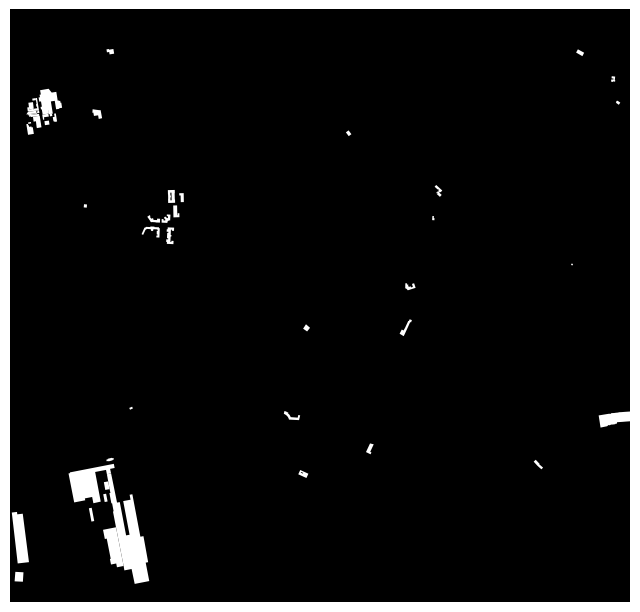

In [ ]:
# Project the GeoDataFrame
gdf_proj = ox.projection.project_gdf(workplace_buildings)

# Plot the buildings within the bounding box
fig, ax = ox.plot_footprints(
    gdf_proj,
    bbox=bbox_poly.total_bounds,  # must match projected CRS
    color="white",
    bgcolor="black",  # Black background
    dpi=100,
    save=False,
    show=True,
    close=True
)


Workplace amenities


In [ ]:
hospitals = ox.features_from_place(place_name, {"amenity": "hospital"}).to_crs("EPSG:32632")  # Large employment centers
print(f"the number of hospitals: {len(hospitals)}")

industrial_facilities = ox.features_from_place(place_name, {"building": "industrial"}).to_crs("EPSG:32632")  # Industrial areas
print(f"the number of industrial zones: {len(industrial_facilities)}")

offices = ox.features_from_place(place_name, {"building": "office"}).to_crs("EPSG:32632")  # Offices scattered across the city
print(f"the number of offices: {len(offices)}")

# noise: commercial area, shops

the number of hospitals: 6
the number of industrial zones: 137
the number of offices: 24


In [ ]:
# list of origins
transit_gdf = [train_stations, bus_stations, parkings]
transit_origins = pd.concat(transit_gdf).reset_index(drop=True)

# List of destination GeoDataFrames
destinations_gdf = [educational_buildings, workplace_buildings]
destinations = pd.concat(destinations_gdf).reset_index(drop=True)

print(f"Transportation hub origins combined: {len(transit_origins)}")
print(f"Residential origins combined: {len(residential_buildings)}")
print(f"Total destinations combined: {len(destinations)}")


Transportation hub origins combined: 552
Residential origins combined: 1513
Total destinations combined: 130


## Build the gravity model


In [ ]:
# Separate origins into two lists
residential_origin_coords = np.array([(p.centroid.x, p.centroid.y) for p in residential_buildings.geometry if p.is_valid])
transit_origin_coords = np.array([(p.centroid.x, p.centroid.y) for p in train_stations.geometry if p.is_valid] +
                           [(p.centroid.x, p.centroid.y) for p in bus_stations.geometry if p.is_valid] +
                           [(p.centroid.x, p.centroid.y) for p in parkings.geometry if p.is_valid])

# Combine them to keep indices aligned
origin_coords = np.concatenate((residential_origin_coords, transit_origin_coords))

destination_coords = np.array([(p.centroid.x, p.centroid.y) for p in destinations.geometry if p.is_valid])



In [ ]:
# Define attractiveness (volume) for origins and destinations
O_home = np.array(residential_buildings["volume"].tolist())  # Home volume
O_station = np.ones(len(transit_origins)) * (sum(O_home) / len(transit_origins))  # Balance station weight

# Normalize total trip production (ensuring 50-50 split)
O_home = (O_home / O_home.sum()) * 0.5  # Homes contribute 50% of trips
O_station = (O_station / O_station.sum()) * 0.5  # Stations contribute 50%

# Combine both origins into a single trip production array
O_i = np.concatenate((O_home, O_station))

# Define attraction values for destinations (building volume)
D_j = np.array(destinations['volume'])


In [ ]:
from scipy.spatial.distance import cdist

# Step 1: Compute Euclidean Distances in Meters
distances = cdist(origin_coords, destination_coords, metric="euclidean")  # Ensure CRS is metric

# Step 2: Apply Gravity Model With Volume-Based Attractiveness
beta = 1.5  # Distance decay parameter
T_ij = (O_i[:, np.newaxis] * D_j) / (distances ** beta)
T_ij = T_ij / T_ij.sum()  # Normalize


Assign a fixed number of trips to the sampled OD pairs.


In [ ]:
# NOTE: Worker/student OD sampling; the saved CSV is an input to exawaro/main.py.
import random

# Step 1: Flatten the probability matrix
flat_T_ij = T_ij.flatten()
flat_OD_pairs = [(o, d) for o in origin_coords for d in destination_coords]

# Step 2: Determine how many OD rows belong to home vs. transit
num_home_origins = len(residential_origin_coords)
num_station_origins = len(transit_origin_coords)
n_destinations = len(destination_coords)

# Step 3: Trip quantities
num_trips = 10000
num_home_trips = num_trips // 2
num_station_trips = num_trips - num_home_trips

# Step 4: Sample home-based OD pairs
home_od_pairs = random.choices(
    flat_OD_pairs[:num_home_origins * n_destinations],
    weights=flat_T_ij[:num_home_origins * n_destinations],
    k=num_home_trips
)

# Step 5: Sample transit-based OD pairs
station_od_pairs = random.choices(
    flat_OD_pairs[num_home_origins * n_destinations:],
    weights=flat_T_ij[num_home_origins * n_destinations:],
    k=num_station_trips
)

# Step 6: Combine samples into one list
sampled_od_pairs = home_od_pairs + station_od_pairs

# Step 7: Save as DataFrame
od_df = pd.DataFrame(sampled_od_pairs, columns=["origin", "destination"])
od_df.head()


,origin,destination
0,"[611495.4419615148, 4840338.217790754]","[614176.8944917693, 4841448.473157815]"
1,"[613037.0487248285, 4840453.659795383]","[613774.1430368883, 4840503.196653403]"
2,"[613487.9985671488, 4840048.353274775]","[611870.2828611074, 4840044.703780443]"
3,"[611693.265067743, 4842569.601705013]","[611388.3717793055, 4840088.082327676]"
4,"[612679.7581382967, 4841757.805544997]","[611952.8396503495, 4840090.932021155]"


In [ ]:
# NOTE: Saved CSV is an input to exawaro/main.py.
od_df.to_csv(exawaro_path + "tables/workers_students_od_pairs_pisa.csv", index=False)
# The index=False argument prevents the dataframe index from being written to the file.

In [ ]:
import pyproj
import osmnx as ox

# Step 1: Transformer from UTM (EPSG:32632) → WGS84 (EPSG:4326)
transformer = pyproj.Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True)

# Step 2: Transform coords → lat/lon for origins and destinations
od_df[["origin_lon", "origin_lat"]] = od_df["origin"].apply(lambda p: pd.Series(transformer.transform(*p)))
od_df[["dest_lon", "dest_lat"]] = od_df["destination"].apply(lambda p: pd.Series(transformer.transform(*p)))

# Step 3: Use OSMnx to get nearest node for each
od_df["origin_node"] = ox.distance.nearest_nodes(graph, X=od_df["origin_lon"], Y=od_df["origin_lat"])
od_df["destination_node"] = ox.distance.nearest_nodes(graph, X=od_df["dest_lon"], Y=od_df["dest_lat"])

# Step 4: Filter valid (unique) OD pairs
od_pairs = od_df[["origin_node", "destination_node"]].dropna().values.tolist()


In [ ]:
print(f"Total valid OD pairs: {len(od_pairs)}")
od_pairs[:5]


Total valid OD pairs: 10000


[[5527368964, 2700692662],
 [10804364793, 5128229248],
 [251213106, 9338126020],
 [1227813198, 1946104011],
 [2261395923, 7362761029]]

In [ ]:
# Generate the first table with detailed routing results

for weight in weights:
    detailed_results = []
    print(f"Routing with weight: {weight}")
    routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs_list, least_cost_weight=weight)
    results_df = pd.DataFrame(routing_results)

    for _, row in results_df.iterrows():
        # Extract route details
        detailed_results.append({
            'origin': row['origin'],
            'destination': row['destination'],
            'weight': weight,

            'fastest_path' : row['fastest_path'],
            'least_cost_path': row['least_cost_path'],

            'least_cost_time': row['least_cost_time'],
            'fastest_time': row['fastest_time'],

            'least_cost_exposure': row['least_cost_exposure'],
            'fastest_exposure': row['fastest_exposure'],

            'similarity': row['similarity']
        })

    # Convert to DataFrame
    detailed_df = pd.DataFrame(detailed_results)
    detailed_df.to_csv(exawaro_path+f"tables/routing_results_{weight}_{num_trips}_workers.csv", index=False)


Routing with weight: 0.8


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:37<00:00, 62.25it/s]


Routing with weight: 0.64


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:41<00:00, 61.01it/s]


Routing with weight: 0.512


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:38<00:00, 62.22it/s]


... (26 outputs left out)

Routing with weight: 0.023


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:33<00:00, 64.02it/s]


Routing with weight: 0.018


Routing for OD Pairs: 100%|██████████| 9833/9833 [02:35<00:00, 63.27it/s]


In [ ]:
import os

# Specify the directory where the files are located
directory = exawaro_path + "tables/"
print(os.listdir(directory))

# Gather all files matching the pattern
files = [f for f in os.listdir(directory) if f.startswith("routing_results_") and f.endswith("10000_workers.csv")]
print(files)

# Initialize an empty list to store DataFrames
dataframes = []

# Loop through the files and read them into DataFrames
for file in files:
    file_path = os.path.join(directory, file)
    df = pd.read_csv(file_path)  # Adjust the function if your file isn't CSV (e.g., pd.read_excel for Excel files)
    dataframes.append(df)

# Concatenate all DataFrames
tradeoff_df = pd.concat(dataframes, ignore_index=True)
tradeoff_df.head()

['.ipynb_checkpoints', 'routing_results_0.134_50000_pairs.csv', 'routing_results_0.107_50000_pairs.csv', 'routing_results_0.086_50000_pairs.csv', 'routing_results_0.069_50000_pairs.csv', 'routing_results_0.055_50000_pairs.csv', 'routing_results_0.044_50000_pairs.csv', 'routing_results_0.035_50000_pairs.csv', 'routing_results_0.028_50000_pairs.csv', 'routing_results_0.023_50000_pairs.csv', 'routing_results_0.018_50000_pairs.csv', 'routing_results_0.014_50000_pairs.csv', 'routing_results_0.8_50000_pairs.csv', 'routing_results_0.64_50000_pairs.csv', 'routing_results_0.512_50000_pairs.csv', 'routing_results_0.41_50000_pairs.csv', 'routing_results_0.328_50000_pairs.csv', 'routing_results_0.262_50000_pairs.csv', 'routing_results_0.21_50000_pairs.csv', 'routing_results_0.168_50000_pairs.csv', 'routing_results_pisa_50000_pairs.csv', 'pareto_df.csv', 'local_hypervolume_df.csv', 'noise_df.csv', 'workers_students_od_pairs_df.csv', 'pisa_places_with_ratings.csv', 'pisa_accomodations_with_ratings.c

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity
0,5022182078,253556308,0.8,"[5022182078, 253555981, 10880438174, 253555982...","[5022182078, 253555981, 10880438174, 253555982...",208.069954,208.069954,0.103116,0.103116,1.000000
1,9705969261,6291016100,0.8,"[9705969261, 9705969253, 9705969255, 970596925...","[9705969261, 9705969253, 9705969255, 970596925...",997.700701,948.077036,0.962541,2.348502,0.198595
2,3461598156,10719520529,0.8,"[3461598156, 3461598157, 3461598158, 334655532...","[3461598156, 3461598157, 3461598158, 334655532...",1303.182465,1303.182465,0.600125,0.600125,1.000000
3,279535284,1596063928,0.8,"[279535284, 9288179885, 245925396, 245925395, ...","[279535284, 9288179885, 245925396, 245925395, ...",228.082111,228.082111,0.025577,0.025577,1.000000
4,10917714279,11479403452,0.8,"[10917714279, 9882762262, 11523685581, 1088043...","[10917714279, 9882762262, 11523685581, 1088043...",334.454696,334.454696,0.188123,0.188123,1.000000


In [ ]:
# Save the concatenated result into a single file
output_file = os.path.join(directory, "routing_results_pisa_10000_workers.csv")
tradeoff_df.to_csv(output_file, index=False)

print(f"Files concatenated and saved to {output_file}")

Files concatenated and saved to /content/drive/MyDrive/Colab Notebooks/exawaro/pedestrian/tables/routing_results_pisa_10000_workers.csv


In [ ]:
tradeoff_df[['similarity', 'least_cost_time', 'fastest_time', 'least_cost_exposure', 'fastest_exposure']].describe()

,similarity,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure
count,340524.000000,340524.000000,340524.000000,340524.000000,340524.000000
mean,0.787398,536.352770,513.033577,0.211139,0.266028
std,0.337443,446.359447,417.524769,0.221115,0.356635
min,0.000000,0.915218,0.915218,0.000238,0.000238
25%,0.587477,168.806850,168.292698,0.049997,0.050489
50%,1.000000,412.668314,403.625623,0.144047,0.152395
75%,1.000000,815.866578,785.211948,0.297587,0.335690
max,1.000000,2749.637152,2732.906697,3.093343,3.093343


## Analysis


In [ ]:
# load calculated routes before the analysis of trade-offs

tradeoff_df = pd.read_csv(exawaro_path + "tables/routing_results_pisa_10000_noise.csv")
tradeoff_df['time_diff_percentage'] = ((tradeoff_df['least_cost_time'] - tradeoff_df['fastest_time']) / tradeoff_df['fastest_time']) * 100
tradeoff_df['exposure_diff_percentage'] = ((tradeoff_df['least_cost_exposure'] - tradeoff_df['fastest_exposure']) / tradeoff_df['fastest_exposure']) * 100

tradeoff_df.head()

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,5022182078,253556308,0.8,"[5022182078, 253555981, 10880438174, 253555982...","[5022182078, 253555981, 10880438174, 253555982...",208.069954,208.069954,0.103116,0.103116,1.000000,0.000000,0.000000
1,9705969261,6291016100,0.8,"[9705969261, 9705969253, 9705969255, 970596925...","[9705969261, 9705969253, 9705969255, 970596925...",997.700701,948.077036,0.962541,2.348502,0.198595,5.234138,-59.014693
2,3461598156,10719520529,0.8,"[3461598156, 3461598157, 3461598158, 334655532...","[3461598156, 3461598157, 3461598158, 334655532...",1303.182465,1303.182465,0.600125,0.600125,1.000000,0.000000,0.000000
3,279535284,1596063928,0.8,"[279535284, 9288179885, 245925396, 245925395, ...","[279535284, 9288179885, 245925396, 245925395, ...",228.082111,228.082111,0.025577,0.025577,1.000000,0.000000,0.000000
4,10917714279,11479403452,0.8,"[10917714279, 9882762262, 11523685581, 1088043...","[10917714279, 9882762262, 11523685581, 1088043...",334.454696,334.454696,0.188123,0.188123,1.000000,0.000000,0.000000


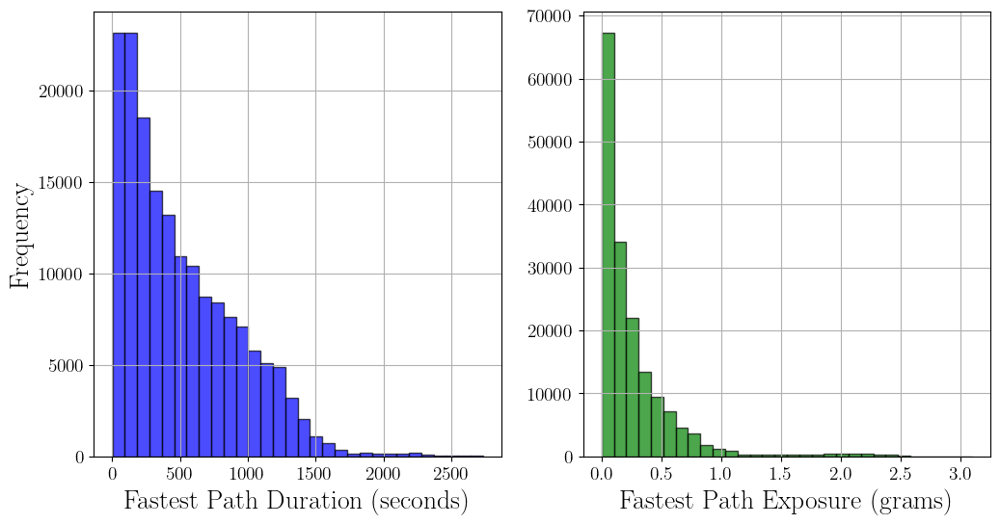

In [ ]:
# Fastest durations and exposures
fastest_durations = tradeoff_df['fastest_time']
fastest_exposures = tradeoff_df['fastest_exposure']

fontsize = 20

# Plot histograms
plt.figure(figsize=(12, 6))

# Histogram for fastest durations
plt.subplot(1, 2, 1)

plt.hist(fastest_durations, bins=30, color='blue', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Duration (seconds)', fontsize=fontsize)
plt.ylabel('Frequency', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)


# Histogram for fastest exposures
plt.subplot(1, 2, 2)

plt.hist(fastest_exposures, bins=30, color='green', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Exposure (grams)', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
# plot_name = "plots/distributions_workers.pdf"
plt.savefig(exawaro_path + plot_name, format='pdf', dpi=300, bbox_inches="tight", pad_inches=0.01)
plt.show()

In [ ]:
# Unique weights
weights = tradeoff_df['weight'].unique()

# Results container
pareto_results = []

# Iterate over each weight
for weight in weights:
    # Filter the DataFrame for the current weight
    filtered_df = tradeoff_df[tradeoff_df['weight'] == weight]

    # Calculate percentage differences
    time_diff = filtered_df['least_cost_time'] - filtered_df['fastest_time']
    exposure_diff = filtered_df['least_cost_exposure'] - filtered_df['fastest_exposure']

    time_diff_percentage = (time_diff / filtered_df['fastest_time']) * 100
    exposure_diff_percentage = (exposure_diff / filtered_df['fastest_exposure']) * 100

    # Replace infinities and NaNs with 0 for clean calculation
    time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    time_diff_percentage.fillna(0, inplace=True)
    exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    exposure_diff_percentage.fillna(0, inplace=True)

    # Store results for this weight
    pareto_results.append({
        'weight': weight,

        'avg_time_diff_percentage': time_diff_percentage.mean(),
        'avg_exposure_diff_percentage': exposure_diff_percentage.mean(),

        'median_time_diff_percentage': time_diff_percentage.median(),
        'median_exposure_diff_percentage': exposure_diff_percentage.median(),

        'time_45th': time_diff_percentage.quantile(0.45),
        'time_55th': time_diff_percentage.quantile(0.55),
        'exposure_45th': exposure_diff_percentage.quantile(0.45),
        'exposure_55th': exposure_diff_percentage.quantile(0.55),

        'time_25th': time_diff_percentage.quantile(0.25),
        'time_75th': time_diff_percentage.quantile(0.75),
        'exposure_25th': exposure_diff_percentage.quantile(0.25),
        'exposure_75th': exposure_diff_percentage.quantile(0.75),
    })

# Convert to DataFrame for plotting
pareto_df = pd.DataFrame(pareto_results)

# Sort Pareto DataFrame by weight
pareto_df = pareto_df.sort_values(by='weight', ascending=True)

# Reset the index.
pareto_df = pareto_df.reset_index(drop=True)

# Display Pareto DataFrame
pareto_df


,weight,avg_time_diff_percentage,avg_exposure_diff_percentage,median_time_diff_percentage,median_exposure_diff_percentage,time_45th,time_55th,exposure_45th,exposure_55th,time_25th,time_75th,exposure_25th,exposure_75th
0,0.018,8.138680,-10.310825,0.005704,-0.013263,0.0,0.276850,-0.854680,0.0,0.0,7.535249,-14.954497,0.0
1,0.023,7.537552,-10.171173,0.000000,0.000000,0.0,0.177523,-0.670357,0.0,0.0,6.644101,-14.312511,0.0
2,0.028,6.697547,-9.946180,0.000000,0.000000,0.0,0.111897,-0.418164,0.0,0.0,5.506042,-13.590826,0.0
3,0.035,5.916492,-9.708363,0.000000,0.000000,0.0,0.052733,-0.220607,0.0,0.0,4.555945,-12.735061,0.0
4,0.044,5.260567,-9.440586,0.000000,0.000000,0.0,0.020071,-0.076957,0.0,0.0,3.907273,-11.946505,0.0
5,0.055,4.600986,-9.101483,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,3.278192,-10.758245,0.0
6,0.069,3.848090,-8.581270,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,2.108886,-9.300852,0.0
7,0.086,2.989367,-7.878377,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,1.135835,-7.023635,0.0
8,0.107,2.498219,-7.361292,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.713218,-5.657661,0.0
9,0.134,2.024113,-6.767575,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.421634,-3.887074,0.0


In [ ]:
# Define the reference point as the worst-case scenario
reference_time = pareto_df['avg_time_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min())
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() #+ 0.1 * (pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min())

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

Best Point on Pareto Front (Highest Hypervolume):
weight                              0.107000
avg_time_diff_percentage            2.498219
avg_exposure_diff_percentage       -7.361292
median_time_diff_percentage         0.000000
median_exposure_diff_percentage     0.000000
time_45th                           0.000000
time_55th                           0.000000
exposure_45th                       0.000000
exposure_55th                       0.000000
time_25th                           0.000000
time_75th                           0.713218
exposure_25th                      -5.657661
exposure_75th                       0.000000
hypervolume                        35.481415
Name: 8, dtype: float64


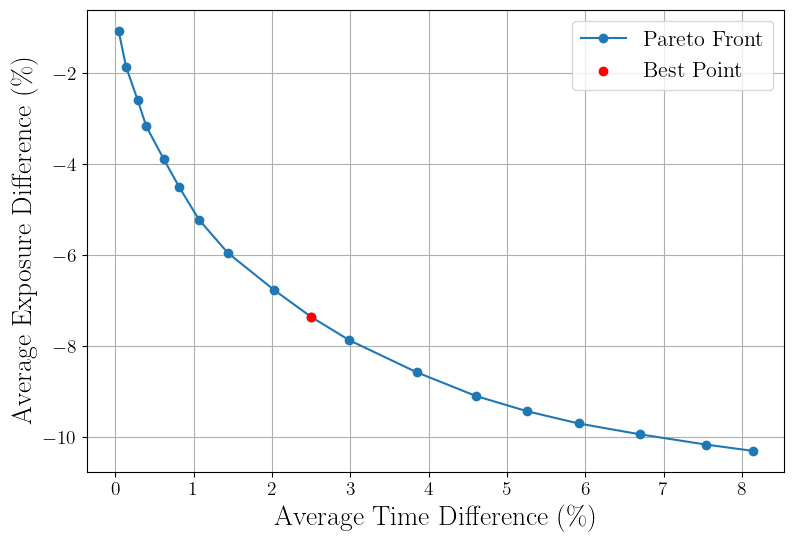

In [ ]:
# NOTE: Worker/student scenario duplicate; sets plot_name but does not save; display-only.
# Print the best point
print("Best Point on Pareto Front (Highest Hypervolume):")
print(best_point)

legend_fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point", zorder=5)

plt.xlabel("Average Time Difference (\%)", fontsize=legend_fontsize)
plt.ylabel("Average Exposure Difference (\%)", fontsize=legend_fontsize)
plt.grid()
plt.legend(fontsize=legend_fontsize-4)
plt.xticks(fontsize=legend_fontsize-6)
plt.yticks(fontsize=legend_fontsize-6)

# Save the plot as a PDF
plot_name = "plots/pareto_avg_differences.pdf"
plt.show()


## Tourist trips

Short-term tourists make shorter trips and long-term tourists make longer trips. Destinations are attractions; origins are transport hubs and accommodation.


## Data sources


OpenStreetMap via Overpass


In [30]:
import requests

overpass_url = "http://overpass-api.de/api/interpreter"

query = """
[out:json];
area[name="Pisa"]->.searchArea;
(
  node["tourism"="attraction"](area.searchArea);
  way["tourism"="attraction"](area.searchArea);
  relation["tourism"="attraction"](area.searchArea);
);
out tags center;
"""

response = requests.get(overpass_url, params={'data': query})
data = response.json()

attractions = []

for el in data['elements']:
    tags = el.get("tags", {})
    wd = tags.get("wikidata")  # this is the key to fetch metadata later
    name = tags.get("name")
    if name and wd:
        attractions.append({"name": name, "wikidata": wd})

print(f"Found {len(attractions)} attractions with Wikidata IDs.")


Found 30 attractions with Wikidata IDs.


In [31]:
from SPARQLWrapper import SPARQLWrapper, JSON

wikidata_ids = [f"wd:{attr['wikidata']}" for attr in attractions]
chunks = [wikidata_ids[i:i+50] for i in range(0, len(wikidata_ids), 50)]

results = []

for chunk in chunks:
    ids_str = " ".join(chunk)
    query = f"""
    SELECT ?place ?placeLabel ?description ?coordinates ?visitors ?official_website WHERE {{
      VALUES ?place {{ {ids_str} }}
      OPTIONAL {{ ?place schema:description ?description FILTER (lang(?description) = "en") }}
      OPTIONAL {{ ?place wdt:P625 ?coordinates }}
      OPTIONAL {{ ?place wdt:P1174 ?visitors }}
      OPTIONAL {{ ?place wdt:P856 ?official_website }}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    """

    sparql = SPARQLWrapper("https://query.wikidata.org/sparql")
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    data = sparql.query().convert()

    for result in data["results"]["bindings"]:
        res = {
            "name": result.get("placeLabel", {}).get("value"),
            "description": result.get("description", {}).get("value", ""),
            "visitors": result.get("visitors", {}).get("value", ""),
            "website": result.get("official_website", {}).get("value", ""),
        }
        results.append(res)

print(f"Enriched {len(results)} places with Wikidata info.")


Enriched 59 places with Wikidata info.


In [32]:
df = pd.DataFrame(results)
df.head()

,name,description,visitors,website
0,Tumulo del Principe etrusco,Etruscan tumulus-type tomb located near Pisa.,,
1,Palazzo comunale,"palazzo in San Miniato, Italy",287,
2,Palazzo comunale,"palazzo in San Miniato, Italy",870,
3,Palazzo comunale,"palazzo in San Miniato, Italy",2197,
4,Palazzo comunale,"palazzo in San Miniato, Italy",3941,


Google Places


Text search by bounding rectangle


In [ ]:
# NOTE: Google Places API demonstration; credentials are placeholders.
import requests

API_KEY = 'YOUR_GOOGLE_MAPS_API_KEY'

query = "tourist attractions in Pisa, Italy"

rectangle = "rectangle:43.6620,10.3280|43.7400,10.4550"  # bounding box for Pisa

url = (
    f"https://maps.googleapis.com/maps/api/place/textsearch/json?"
    f"query={query}&locationbias={rectangle}&type=tourist_attraction&key={API_KEY}"
)

response = requests.get(url)
data = response.json()

for place in data.get("results", []):
    name = place.get("name")
    ratings = place.get("user_ratings_total")
    print(f"{name} — {ratings} ratings")



Tower of Pisa — 168496 ratings
Camposanto — 893 ratings
Chiesa di Santa Maria della Spina — 3620 ratings
Torre di Santa Maria — 48 ratings
Piazza del Duomo — 129650 ratings
Fontana dei Putti — 288 ratings
Porta Santa Maria Pisa — 135 ratings
Piazza dei Cavalieri — 10957 ratings
Palazzo Gambacorti — 329 ratings
Palazzo della Carovana — 149 ratings
Battistero di San Giovanni — 3285 ratings
National Museum of San Matteo — 569 ratings
Cattedrale di Pisa — 11382 ratings
Torre del Campano — 39 ratings
Palazzo dell'Orologio - Torre della Muda o della Fame — 96 ratings
Logge dei Banchi — 1230 ratings
Museo dell'Opera del Duomo — 520 ratings
Porta Nuova Pisa — 230 ratings
Orto e Museo Botanico — 3899 ratings
Lungarni di Pisa — 936 ratings


Nearby search around grid points


In [ ]:
# NOTE: Grid generation for the API demonstration.
# Define a bounding box that roughly matches the city of Pisa
# Bounding box for central Pisa.
lat_min, lat_max = 43.6620, 43.7400
lon_min, lon_max = 10.3280, 10.4550

# Step size for ~100 meters
step = 0.001

# Generate grid points
lat_points = np.arange(lat_min, lat_max, step)
lon_points = np.arange(lon_min, lon_max, step)
grid_points = [(round(lat, 5), round(lon, 5)) for lat in lat_points for lon in lon_points]

# Write the grid points to CSV.
df_points = pd.DataFrame(grid_points, columns=["latitude", "longitude"])
df_points.to_csv("pisa_grid_100m.csv", index=False)

print(f"Generated {len(grid_points)} points")


Generated 10112 points


Attractions around each grid point


In [ ]:
# NOTE: Overpass/Google Places enrichment demonstration; credentials are placeholders.
import requests
import time

# Sample grid points used in the API demonstration.
grid_points = [
    (43.716, 10.396), (43.717, 10.396),
    (43.718, 10.396), (43.719, 10.396)
]

# Set to collect unique places by place_id
unique_places = {}

def fetch_places(lat, lon, radius=100):
    all_results = []
    url = (
        f"https://maps.googleapis.com/maps/api/place/nearbysearch/json?"
        f"location={lat},{lon}&radius={radius}&type=tourist_attraction&key={API_KEY}"
    )
    while url:
        resp = requests.get(url)
        data = resp.json()
        all_results.extend(data.get("results", []))
        next_page = data.get("next_page_token")
        if next_page:
            time.sleep(2)
            url = (
                f"https://maps.googleapis.com/maps/api/place/nearbysearch/json?"
                f"pagetoken={next_page}&key={API_KEY}"
            )
        else:
            break
    return all_results

# Run query for each point
for lat, lon in grid_points:
    print(f"Querying around: {lat}, {lon}")
    places = fetch_places(lat, lon)
    for place in places:
        pid = place.get("place_id")
        if pid and pid not in unique_places:
            unique_places[pid] = {
                "name": place.get("name"),
                "user_ratings_total": place.get("user_ratings_total"),
                "lat": place["geometry"]["location"]["lat"],
                "lon": place["geometry"]["location"]["lng"]
            }

# Convert to DataFrame and save
df = pd.DataFrame(unique_places.values())
df.to_csv("pisa_tourist_places.csv", index=False)
print(f"Saved {len(df)} unique tourist attractions.")


Querying around: 43.716, 10.396
Querying around: 43.717, 10.396
Querying around: 43.718, 10.396
Querying around: 43.719, 10.396
Saved 5 unique tourist attractions.


Retrieve attractions from OpenStreetMap and ratings from Google Places.


In [ ]:
# NOTE: Second API demonstration block with placeholder credentials.
API_KEY = 'YOUR_GOOGLE_MAPS_API_KEY'
overpass_url = "https://overpass-api.de/api/interpreter"


In [ ]:
# Helper: run Overpass query
def get_osm_data(tag_key, tag_value):
    query = f"""
    [out:json][timeout:25];
    area["name"="Pisa"]["boundary"="administrative"]["admin_level"="8"]->.searchArea;
    (
      node["{tag_key}"="{tag_value}"](area.searchArea);
      way["{tag_key}"="{tag_value}"](area.searchArea);
      relation["{tag_key}"="{tag_value}"](area.searchArea);
    );
    out center tags;
    """
    response = requests.get(overpass_url, params={'data': query})
    data = response.json()
    elements = data["elements"]

    places = []
    for el in elements:
        tags = el.get("tags", {})
        name = tags.get("name")
        lat = el.get("lat") or el.get("center", {}).get("lat")
        lon = el.get("lon") or el.get("center", {}).get("lon")
        if name and lat and lon:
            places.append({
                "name": name,
                "lat": lat,
                "lon": lon,
                "category": tag_value
            })
    return places

# Step 1: Get attractions and restaurants from OSM
attractions = get_osm_data("tourism", "attraction")
restaurants = get_osm_data("amenity", "restaurant")
all_places = attractions + restaurants
df_osm = pd.DataFrame(all_places)

print(f"Found {len(attractions)} attractions and {len(restaurants)} restaurants from OpenStreetMap.")

Found 22 attractions and 333 restaurants from OpenStreetMap.


In [ ]:
# NOTE: Broad exception handling in the Google enrichment demonstration; retained for provenance.
# Step 2: Enrich with Google Places API
def enrich_with_google(df):
    enriched = []
    for _, row in df.iterrows():
        query = f"{row['name']} {row['category']} Pisa Italy"
        lat, lon = row["lat"], row["lon"]
        url = (
            f"https://maps.googleapis.com/maps/api/place/textsearch/json?"
            f"query={requests.utils.quote(query)}&location={lat},{lon}&radius=100&key={API_KEY}"
        )
        try:
            resp = requests.get(url)
            data = resp.json()
            if data["status"] == "OK" and data["results"]:
                top = data["results"][0]
                enriched.append({
                    "name": row["name"],
                    "lat": lat,
                    "lon": lon,
                    "category": row["category"],
                    "google_name": top.get("name"),
                    "user_ratings_total": top.get("user_ratings_total"),
                    "rating": top.get("rating"),
                    "place_id": top.get("place_id")
                })
        except Exception as e:
            print(f"Error for {row['name']}: {e}")
        time.sleep(0.5)  # Respect API rate limits
    return pd.DataFrame(enriched)

# Step 3: Run enrichment
df_enriched = enrich_with_google(df_osm)

print(f"Enriched {len(df_enriched)} places with ratings.")


Enriched 355 places with ratings.


In [35]:
# NOTE: Warning from fill-on-copy; retained from the original enrichment demonstration.
df_enriched["user_ratings_total"].fillna(df_enriched["user_ratings_total"].mean(), inplace=True)

<ipython-input-35-f09bb4a36e13>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_enriched["user_ratings_total"].fillna(df_enriched["user_ratings_total"].mean(), inplace=True)


In [36]:
df_enriched.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 355 entries, 0 to 354
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                355 non-null    object 
 1   lat                 355 non-null    float64
 2   lon                 355 non-null    float64
 3   category            355 non-null    object 
 4   google_name         355 non-null    object 
 5   user_ratings_total  355 non-null    float64
 6   rating              352 non-null    float64
 7   place_id            355 non-null    object 
dtypes: float64(4), object(4)
memory usage: 22.3+ KB


Get accommodation from OpenStreetMap.


In [ ]:
# Updated helper to include rooms and beds
def get_osm_data(tag_key, tag_value):
    query = f"""
    [out:json][timeout:25];
    area["name"="Pisa"]["boundary"="administrative"]["admin_level"="8"]->.searchArea;
    (
      node["{tag_key}"="{tag_value}"](area.searchArea);
      way["{tag_key}"="{tag_value}"](area.searchArea);
      relation["{tag_key}"="{tag_value}"](area.searchArea);
    );
    out center tags;
    """
    response = requests.get(overpass_url, params={'data': query})
    data = response.json()
    elements = data["elements"]

    places = []
    for el in elements:
        tags = el.get("tags", {})
        name = tags.get("name")
        lat = el.get("lat") or el.get("center", {}).get("lat")
        lon = el.get("lon") or el.get("center", {}).get("lon")
        rooms = tags.get("rooms")
        beds = tags.get("beds")
        if name and lat and lon:
            places.append({
                "name": name,
                "lat": lat,
                "lon": lon,
                "category": tag_value,
                "rooms": rooms,
                "beds": beds
            })
    return places

# Fetch accommodations
hotels = get_osm_data("tourism", "hotel")
hostels = get_osm_data("tourism", "hostel")
guesthouses = get_osm_data("tourism", "guest_house")
accommodations = hotels + hostels + guesthouses

# Create DataFrame
df_accommodations = pd.DataFrame(accommodations)

print(f"Found {len(df_accommodations)} places for accomodation from OpenStreetMap.")

Found 125 places for accomodation from OpenStreetMap.


In [ ]:
# NOTE: Second enrichment-function variant with broad exception handling; retained for provenance.
# Google enrichment function
def enrich_with_google(df):
    enriched = []
    for _, row in df.iterrows():
        query = f"{row['name']} {row['category']} Pisa Italy"
        lat, lon = row["lat"], row["lon"]
        url = (
            f"https://maps.googleapis.com/maps/api/place/textsearch/json?"
            f"query={requests.utils.quote(query)}&location={lat},{lon}&radius=100&key={API_KEY}"
        )
        try:
            resp = requests.get(url)
            data = resp.json()
            if data["status"] == "OK" and data["results"]:
                top = data["results"][0]
                enriched.append({
                    "name": row["name"],
                    "lat": lat,
                    "lon": lon,
                    "category": row["category"],
                    "rooms": row.get("rooms"),
                    "beds": row.get("beds"),
                    "google_name": top.get("name"),
                    "user_ratings_total": top.get("user_ratings_total"),
                    "rating": top.get("rating"),
                    "place_id": top.get("place_id")
                })
        except Exception as e:
            print(f"Error for {row['name']}: {e}")
        time.sleep(0.5)
    return pd.DataFrame(enriched)

# Run enrichment for a small sample for demo (full run can be done locally)
df_enriched_accomodation = enrich_with_google(df_accommodations)

df_enriched_accomodation.head()
print(f"{len(df_enriched_accomodation)} places for accomodation")

125 places for accomodation


In [ ]:
accommodations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                125 non-null    object 
 1   lat                 125 non-null    float64
 2   lon                 125 non-null    float64
 3   category            125 non-null    object 
 4   rooms               14 non-null     float64
 5   beds                0 non-null      float64
 6   google_name         125 non-null    object 
 7   user_ratings_total  125 non-null    int64  
 8   rating              125 non-null    float64
 9   place_id            125 non-null    object 
dtypes: float64(5), int64(1), object(4)
memory usage: 9.9+ KB


## Generate tourist demand


In [38]:
df_enriched = pd.read_csv(exawaro_path+"tables/pisa_places_with_ratings.csv")
df_enriched.head()

,name,lat,lon,category,google_name,user_ratings_total,rating,place_id
0,Pipistrelli,43.725076,10.338847,attraction,Tower of Pisa,168499.0,4.7,ChIJzYhOxKaR1RIRA_xU1bGp7DI
1,Antichi cippi miliari e confinari,43.639542,10.392492,attraction,Fontana dei Putti,288.0,4.4,ChIJP1TJOaeR1RIRSawJDjv-HCQ
2,Cittadella Nuova,43.712461,10.407409,attraction,Giardino Scotto,3808.0,4.4,ChIJQzVYe6GR1RIRFGhBjXC6jYU
3,Palazzo Gambacorti,43.715521,10.401220,attraction,Palazzo Gambacorti,329.0,4.3,ChIJnwlgv5iR1RIRIf8YzBI7T3I
4,"Locomotiva ""Dante Alighieri""",43.710750,10.395805,attraction,"Locomotiva ""Dante Alighieri""",10.0,4.0,ChIJNVMqNGqV1RIR5WQZ31x4YTk


In [40]:
accommodations = pd.read_csv(exawaro_path+"tables/pisa_accomodations_with_ratings.csv")
accommodations[['name',	'lat',	'lon',	'rooms',	'beds',	'google_name',	'user_ratings_total']].head()

,name,lat,lon,rooms,beds,google_name,user_ratings_total
0,Hotel Repubblica Marinara,43.711291,10.421596,NaN,NaN,Hotel Repubblica Marinara,1208
1,Grand Hotel Continental,43.627877,10.289743,NaN,NaN,Grand Hotel Continental,1422
2,Hotel La Pace,43.709629,10.398267,NaN,NaN,Hotel La Pace,1826
3,Il Giardino,43.723097,10.392459,NaN,NaN,Hotel Il Giardino,398
4,Amalfitana,43.718168,10.395369,NaN,NaN,Hotel Amalfitana,414


## Gravity model


In [47]:
from pyproj import Transformer
from scipy.spatial.distance import cdist

# Reproject origins and destinations
accommodations_gdf = gpd.GeoDataFrame(accommodations, geometry=gpd.points_from_xy(accommodations.lon, accommodations.lat), crs="EPSG:4326").to_crs("EPSG:32632")
destinations_gdf = gpd.GeoDataFrame(df_enriched, geometry=gpd.points_from_xy(df_enriched.lon, df_enriched.lat), crs="EPSG:4326").to_crs("EPSG:32632")

origin_coords = np.array([(p.x, p.y) for p in accommodations_gdf.geometry])
destination_coords = np.array([(p.x, p.y) for p in destinations_gdf.geometry])

print(f"Origins: {len(origin_coords)}")
print(f"Destinations: {len(destination_coords)}")

Origins: 125
Destinations: 355


In [56]:
D_j = destinations_gdf["user_ratings_total"].fillna(destinations_gdf["user_ratings_total"].mean()).values
O_i = accommodations_gdf["user_ratings_total"].fillna(accommodations_gdf["user_ratings_total"].mean()).values

distances = cdist(origin_coords, destination_coords, metric="euclidean")

# different distance decay parameters for short/long-term tourists
beta_short = 2.0  # Higher decay → Prefer nearby attractions
beta_long = 1.2  # Lower decay → Willing to travel farther

# Compute probability matrices for both tourist groups
T_short = (O_i[:, np.newaxis] * D_j) / (distances ** beta_short)
T_long = (O_i[:, np.newaxis] * D_j) / (distances ** beta_long)

In [57]:
# ---------- Short-Term Tourists ----------
T_short = np.nan_to_num(T_short, nan=0, posinf=0, neginf=0)
valid_mask_short = (distances >= 100) & (distances <= 1500)
T_short = np.where(valid_mask_short, T_short, 0)

if T_short.sum() > 0:
    T_short = T_short / T_short.sum()
print(f"Valid OD pairs (short-term): {np.count_nonzero(valid_mask_short)}")


Valid OD pairs (short-term): 16488


In [58]:
# ---------- Long-Term Tourists ----------
T_long = np.nan_to_num(T_long, nan=0, posinf=0, neginf=0)
valid_mask_long = (distances >= 50) & (distances <= 1500)
T_long = np.where(valid_mask_long, T_long, 0)

if T_long.sum() > 0:
    T_long = T_long / T_long.sum()
print(f"Valid OD pairs (long-term): {np.count_nonzero(valid_mask_long)}")

Valid OD pairs (long-term): 16688


In [59]:
# NOTE: Split tourist demand into short and long trips.
# Define number of trips
num_short_trips = 4000
num_long_trips = 1000

# Flatten probability matrices
flat_T_short = T_short.flatten()
flat_T_long = T_long.flatten()
flat_OD_pairs = [(o, d) for o in origin_coords for d in destination_coords]

# Sample trips based on probability weights
short_term_trips = random.choices(flat_OD_pairs, weights=flat_T_short, k=num_short_trips)
long_term_trips = random.choices(flat_OD_pairs, weights=flat_T_long, k=num_long_trips)

# Combine into a DataFrame
tourist_trips = pd.DataFrame(short_term_trips + long_term_trips, columns=["origin", "destination"])
print(f"Total trips: {len(tourist_trips)}")
tourist_trips.head()

# Split tourist trips between transport hubs and accommodation.

Total trips: 5000


,origin,destination
0,"[612100.7562472554, 4842259.283831936]","[612493.8985876413, 4842056.282688012]"
1,"[604085.2879394646, 4832887.411916026]","[603766.5278912184, 4832923.544384374]"
2,"[612606.418745797, 4842001.121085874]","[612493.8985876413, 4842056.282688012]"
3,"[612562.8403753379, 4841850.451705646]","[612493.8985876413, 4842056.282688012]"
4,"[612062.5003821729, 4842213.8367837425]","[612493.8985876413, 4842056.282688012]"


In [60]:
# NOTE: Saved CSV is an input to exawaro/main.py.
tourist_trips.to_csv(exawaro_path + f"tables/tourist_{num_short_trips+num_long_trips}_od_pairs_pisa.csv", index=False)

Inspect the locations of origins and destinations.


In [61]:
import pyproj

od_df = tourist_trips

# Step 1: Transformer from UTM (EPSG:32632) → WGS84 (EPSG:4326)
transformer = pyproj.Transformer.from_crs("EPSG:32632", "EPSG:4326", always_xy=True)

# Step 2: Transform coords → lat/lon for origins and destinations
od_df[["origin_lon", "origin_lat"]] = od_df["origin"].apply(lambda p: pd.Series(transformer.transform(*p)))
od_df[["dest_lon", "dest_lat"]] = od_df["destination"].apply(lambda p: pd.Series(transformer.transform(*p)))

# Step 3: Use OSMnx to get nearest node for each
od_df["origin_node"] = ox.distance.nearest_nodes(graph, X=od_df["origin_lon"], Y=od_df["origin_lat"])
od_df["destination_node"] = ox.distance.nearest_nodes(graph, X=od_df["dest_lon"], Y=od_df["dest_lat"])

# Step 4: Filter valid (unique) OD pairs
od_pairs = od_df[["origin_node", "destination_node"]].dropna().values.tolist()


In [62]:
print(f"Total valid OD pairs: {len(od_pairs)}")
od_pairs[:5]

Total valid OD pairs: 5000


[[2690142409, 1305606019],
 [3895191406, 3895191406],
 [7569684084, 1305606019],
 [1531715583, 1305606019],
 [10167118435, 1305606019]]

In [63]:
# Step 1: Extract origin and destination nodes from OD pairs
origins = {origin for origin, destination in od_pairs}
destinations = {destination for origin, destination in od_pairs}

valid_origins = [n for n in origins if n in graph.nodes]
valid_destinations = [n for n in destinations if n in graph.nodes]

# Step 2: Prepare coordinates for origins and destinations
origin_x = [graph.nodes[node]['x'] for node in valid_origins]  # Longitude
origin_y = [graph.nodes[node]['y'] for node in valid_origins]  # Latitude

destination_x = [graph.nodes[node]['x'] for node in valid_destinations]  # Longitude
destination_y = [graph.nodes[node]['y'] for node in valid_destinations]  # Latitude

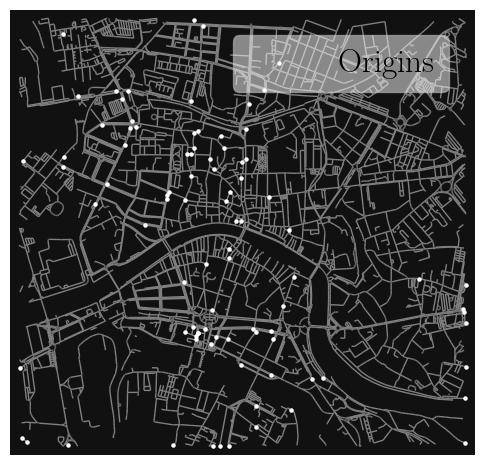

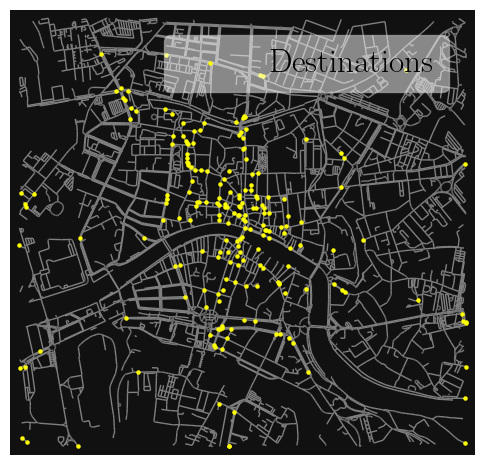

In [64]:
# Step 3: Plot the graph with origins
fig, ax = ox.plot_graph(graph, show=False, close=False, edge_color='gray', node_size=0, figsize=(6, 6))

legend_fontsize = 24

# Plot origins
ax.scatter(origin_x, origin_y, c='white', s=5, label='Origins', zorder=5)
ax.legend(
    fontsize=legend_fontsize,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),  # Fine-tune position within the plot
    frameon=True,                 # Keep the frame
    fancybox=True,                # Rounded edges for the legend box
    framealpha=0.5,               # Set transparency for the legend background
)
plt.show()

# Step 4: Plot the graph with destinations
fig, ax = ox.plot_graph(graph, show=False, close=False, edge_color='gray', node_size=0, figsize=(6, 6))

# Plot destinations
ax.scatter(destination_x, destination_y, c='yellow', s=5, label='Destinations', zorder=5)
ax.legend(
    fontsize=legend_fontsize,
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    frameon=True,
    fancybox=True,
    framealpha=0.5,
)
plt.show()

Compute fastest and least-cost time and exposure.


In [65]:
# Generate the first table with detailed routing results

for weight in weights:
    detailed_results = []
    print(f"Routing with weight: {weight}")
    routing_results = calculate_fastest_and_least_cost_routes(graph, edges_gdf, od_pairs, least_cost_weight=weight)
    results_df = pd.DataFrame(routing_results)

    for _, row in results_df.iterrows():
        # Extract route details
        detailed_results.append({
            'origin': row['origin'],
            'destination': row['destination'],
            'weight': weight,

            'fastest_path' : row['fastest_path'],
            'least_cost_path': row['least_cost_path'],

            'least_cost_time': row['least_cost_time'],
            'fastest_time': row['fastest_time'],

            'least_cost_exposure': row['least_cost_exposure'],
            'fastest_exposure': row['fastest_exposure'],

            'similarity': row['similarity']
        })

    # Convert to DataFrame
    detailed_df = pd.DataFrame(detailed_results)
    detailed_df.to_csv(exawaro_path+f"tables/routing_results_{weight}_{num_short_trips+num_long_trips}_tourists.csv", index=False)


Routing with weight: 0.8


Routing for OD Pairs: 100%|██████████| 5000/5000 [00:50<00:00, 98.06it/s]


Routing with weight: 0.64


Routing for OD Pairs: 100%|██████████| 5000/5000 [00:44<00:00, 112.49it/s]


Routing with weight: 0.512


Routing for OD Pairs: 100%|██████████| 5000/5000 [00:44<00:00, 113.07it/s]


... (26 outputs left out)

Routing with weight: 0.023


Routing for OD Pairs: 100%|██████████| 5000/5000 [00:42<00:00, 118.46it/s]


Routing with weight: 0.018


Routing for OD Pairs: 100%|██████████| 5000/5000 [00:40<00:00, 123.49it/s]


In [67]:
import os

directory = exawaro_path + "tables/"

# Gather all files matching the pattern
files = [f for f in os.listdir(directory) if f.startswith("routing_results_") and f.endswith(f"{num_short_trips+num_long_trips}_tourists.csv")]
print(files)

# Initialize an empty list to store DataFrames
dataframes = []

# Loop through the files and read them into DataFrames
for file in files:
    file_path = os.path.join(directory, file)
    df = pd.read_csv(file_path)  # Adjust the function if your file isn't CSV (e.g., pd.read_excel for Excel files)
    dataframes.append(df)

# Concatenate all DataFrames
tradeoff_df = pd.concat(dataframes, ignore_index=True)
tradeoff_df.head(1)

['routing_results_0.8_5000_tourists.csv', 'routing_results_0.64_5000_tourists.csv', 'routing_results_0.512_5000_tourists.csv', 'routing_results_0.41_5000_tourists.csv', 'routing_results_0.328_5000_tourists.csv', 'routing_results_0.262_5000_tourists.csv', 'routing_results_0.21_5000_tourists.csv', 'routing_results_0.168_5000_tourists.csv', 'routing_results_0.134_5000_tourists.csv', 'routing_results_0.107_5000_tourists.csv', 'routing_results_0.086_5000_tourists.csv', 'routing_results_0.069_5000_tourists.csv', 'routing_results_0.055_5000_tourists.csv', 'routing_results_0.044_5000_tourists.csv', 'routing_results_0.035_5000_tourists.csv', 'routing_results_0.028_5000_tourists.csv', 'routing_results_0.023_5000_tourists.csv', 'routing_results_0.018_5000_tourists.csv', 'routing_results_pisa_5000_tourists.csv']


,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,2690142409,1305606019,0.8,"[2690142409, 11434998441, 11434998442, 1143499...","[2690142409, 11434998441, 11434998442, 1143499...",488.144845,488.144845,0.152059,0.152059,1.0,NaN,NaN


In [68]:
# Save the concatenated result into a single file
output_file = os.path.join(directory, f"routing_results_pisa_{num_short_trips+num_long_trips}_tourists.csv")
# tradeoff_df.to_csv(output_file, index=False)

print(f"Files concatenated and saved to {output_file}")

Files concatenated and saved to /content/drive/MyDrive/Colab Notebooks/exawaro/pedestrian/tables/routing_results_pisa_5000_tourists.csv


In [69]:
tradeoff_df[['similarity', 'least_cost_time', 'fastest_time', 'least_cost_exposure', 'fastest_exposure']].describe()

,similarity,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure
count,984420.000000,984420.000000,984420.000000,984420.000000,984420.000000
mean,0.757955,289.372492,280.005346,0.086636,0.115776
std,0.389084,426.457219,405.702490,0.148989,0.277845
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.568172,21.536338,21.536338,0.004494,0.004494
50%,1.000000,106.161179,106.161179,0.028090,0.028754
75%,1.000000,410.494902,410.494902,0.107490,0.113459
max,1.000000,3817.778440,3029.231839,2.468781,2.771274


## Analysis


In [207]:
# load calculated routes before the analysis of trade-offs

tradeoff_df = pd.read_csv(exawaro_path + f"tables/routing_results_pisa_{num_short_trips+num_long_trips}_tourists.csv")
tradeoff_df['time_diff_percentage'] = ((tradeoff_df['least_cost_time'] - tradeoff_df['fastest_time']) / tradeoff_df['fastest_time']) * 100
tradeoff_df['exposure_diff_percentage'] = ((tradeoff_df['least_cost_exposure'] - tradeoff_df['fastest_exposure']) / tradeoff_df['fastest_exposure']) * 100
tradeoff_df.head(10)

,origin,destination,weight,fastest_path,least_cost_path,least_cost_time,fastest_time,least_cost_exposure,fastest_exposure,similarity,time_diff_percentage,exposure_diff_percentage
0,3528611631,11001274115,0.8,"[3528611631, 11480656514, 11480656516, 1148065...","[3528611631, 11480656514, 11480656516, 1148065...",132.613363,132.613363,0.069744,0.069744,1.0,0.0,0.0
1,8841316522,10923664116,0.8,"[8841316522, 11435293865, 247184489, 10923664116]","[8841316522, 11435293865, 247184489, 10923664116]",21.536338,21.536338,0.004494,0.004494,1.0,0.0,0.0
2,11388380258,1305606019,0.8,"[11388380258, 7681133390, 7681133391, 11388380...","[11388380258, 7681133390, 7681133391, 11388380...",440.736723,440.736723,0.255507,0.255507,1.0,0.0,0.0
3,11435293864,11435293864,0.8,[11435293864],[11435293864],0.000000,0.000000,0.000000,0.000000,0.0,NaN,NaN
4,11435293864,12049099225,0.8,"[11435293864, 12049099225]","[11435293864, 12049099225]",20.883792,20.883792,0.003390,0.003390,1.0,0.0,0.0
5,10923664116,1305606019,0.8,"[10923664116, 247184489, 10923664115, 40617965...","[10923664116, 247184489, 10923664115, 40617965...",404.018497,404.018497,0.069800,0.069800,1.0,0.0,0.0
6,11435293864,10923664116,0.8,"[11435293864, 11435293865, 247184489, 10923664...","[11435293864, 11435293865, 247184489, 10923664...",55.391721,55.391721,0.010755,0.010755,1.0,0.0,0.0
7,8841316522,10923664116,0.8,"[8841316522, 11435293865, 247184489, 10923664116]","[8841316522, 11435293865, 247184489, 10923664116]",21.536338,21.536338,0.004494,0.004494,1.0,0.0,0.0
8,417072496,2268743920,0.8,"[417072496, 252756489, 2350118942, 2268743920]","[417072496, 252756489, 2350118942, 2268743920]",25.596371,25.596371,0.001782,0.001782,1.0,0.0,0.0
9,11435293864,11435293864,0.8,[11435293864],[11435293864],0.000000,0.000000,0.000000,0.000000,0.0,NaN,NaN


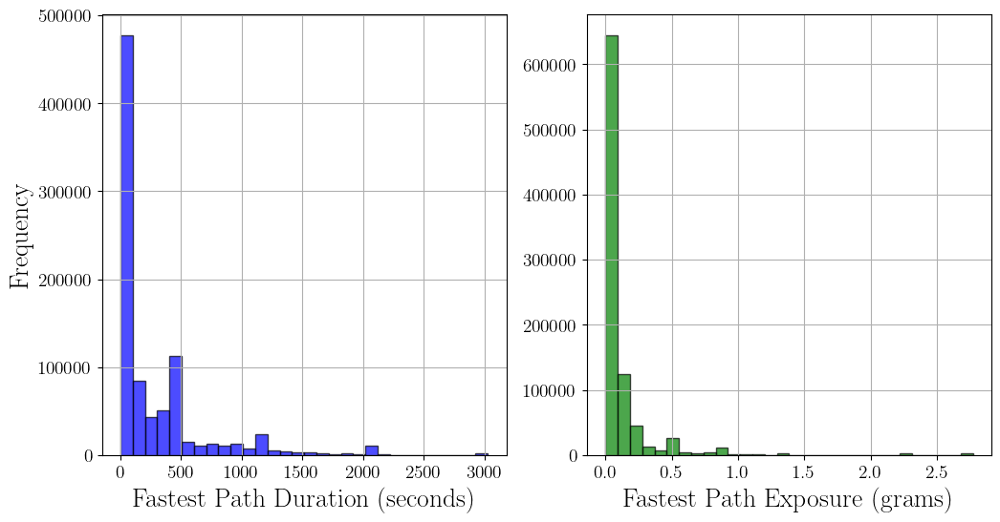

In [200]:
# Fastest durations and exposures
fastest_durations = tradeoff_df['fastest_time']
fastest_exposures = tradeoff_df['fastest_exposure']

fontsize = 20

# Plot histograms
plt.figure(figsize=(12, 6))

# Histogram for fastest durations
plt.subplot(1, 2, 1)

plt.hist(fastest_durations, bins=30, color='blue', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Duration (seconds)', fontsize=fontsize)
plt.ylabel('Frequency', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)


# Histogram for fastest exposures
plt.subplot(1, 2, 2)

plt.hist(fastest_exposures, bins=30, color='green', alpha=0.7, edgecolor='black')

plt.xlabel('Fastest Path Exposure (grams)', fontsize=fontsize)
plt.grid()
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
plot_name = "plots/distributions_tourists.pdf"
plt.show()

## Global weighting


In [208]:
# Unique weights
weights = tradeoff_df['weight'].unique()

# Results container
pareto_results = []

# Iterate over each weight
for weight in weights:
    # Filter the DataFrame for the current weight
    filtered_df = tradeoff_df[tradeoff_df['weight'] == weight]

    # Calculate percentage differences
    time_diff = filtered_df['least_cost_time'] - filtered_df['fastest_time']
    exposure_diff = filtered_df['least_cost_exposure'] - filtered_df['fastest_exposure']

    time_diff_percentage = (time_diff / filtered_df['fastest_time']) * 100
    exposure_diff_percentage = (exposure_diff / filtered_df['fastest_exposure']) * 100

    # Replace infinities and NaNs with 0 for clean calculation
    time_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    time_diff_percentage.fillna(0, inplace=True)
    exposure_diff_percentage.replace([float('inf'), -float('inf')], 0, inplace=True)
    exposure_diff_percentage.fillna(0, inplace=True)

    # Store results for this weight
    pareto_results.append({
        'weight': weight,

        'avg_time_diff_percentage': time_diff_percentage.mean(),
        'avg_exposure_diff_percentage': exposure_diff_percentage.mean(),

        'median_time_diff_percentage': time_diff_percentage.median(),
        'median_exposure_diff_percentage': exposure_diff_percentage.median(),

        'time_45th': time_diff_percentage.quantile(0.45),
        'time_55th': time_diff_percentage.quantile(0.55),
        'exposure_45th': exposure_diff_percentage.quantile(0.45),
        'exposure_55th': exposure_diff_percentage.quantile(0.55),

        'time_25th': time_diff_percentage.quantile(0.25),
        'time_75th': time_diff_percentage.quantile(0.75),
        'exposure_25th': exposure_diff_percentage.quantile(0.25),
        'exposure_75th': exposure_diff_percentage.quantile(0.75),
    })

# Convert to DataFrame for plotting
pareto_df = pd.DataFrame(pareto_results)

# Sort Pareto DataFrame by weight
pareto_df = pareto_df.sort_values(by='weight', ascending=True)

# Reset the index.
pareto_df = pareto_df.reset_index(drop=True)

# Save Pareto DataFrame

# Display Pareto DataFrame
pareto_df.head()


,weight,avg_time_diff_percentage,avg_exposure_diff_percentage,median_time_diff_percentage,median_exposure_diff_percentage,time_45th,time_55th,exposure_45th,exposure_55th,time_25th,time_75th,exposure_25th,exposure_75th
0,0.018,2.574263,-7.088887,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.345963,-4.899267,0.0
1,0.023,2.452922,-7.058949,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.017003,-4.865012,0.0
2,0.028,2.337259,-7.008314,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.881413,-3.744326,0.0
3,0.035,2.279488,-6.985479,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.752341,-3.622783,0.0
4,0.044,2.175709,-6.914071,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.418850,-3.351627,0.0


In [217]:
# pareto_df = pd.read_csv(exawaro_path + "/tables/pareto_df.csv")

# Define the reference point as the worst-case scenario
buffer_reference_time = pareto_df['avg_time_diff_percentage'].max() - pareto_df['avg_time_diff_percentage'].min()
buffer_exposure = pareto_df['avg_exposure_diff_percentage'].max() - pareto_df['avg_exposure_diff_percentage'].min()

reference_time = pareto_df['avg_time_diff_percentage'].max() + 0.1 * buffer_reference_time
reference_exposure = pareto_df['avg_exposure_diff_percentage'].max() + 0.1 * buffer_exposure

# Calculate hypervolume for each point
pareto_df['hypervolume'] = (
    (reference_time - pareto_df['avg_time_diff_percentage']) *
    (reference_exposure - pareto_df['avg_exposure_diff_percentage'])
)

# Find the point with the maximum hypervolume
best_point = pareto_df.loc[pareto_df['hypervolume'].idxmax()]

# hypervolume_df = pd.read_csv(exawaro_path + "/tables/local_hypervolume_tourists.csv")

In [218]:
# discard outliers
global_ideal_time_diff = tradeoff_df[['time_diff_percentage']].quantile(0.9).values[0]
global_ideal_exposure_diff = tradeoff_df[['exposure_diff_percentage']].quantile(0.9).values[0]

print(global_ideal_time_diff)
print(global_ideal_exposure_diff)

4.833515897723574
0.0


In [220]:
# Results container for hypervolume calculations
hypervolume_results = []

# Group by OD pair to compute hypervolume
od_groups = tradeoff_df.groupby(['origin', 'destination'])

for (origin, destination), group in od_groups:
    # print(group[group['least_cost_exposure']==min(group['least_cost_exposure'])])
    # Compute percentage-based differences for each route
    group['time_diff_percentage'] = ((group['least_cost_time'] - group['fastest_time']) / group['fastest_time']) * 100

    # print(group['time_diff_percentage'])

    group['exposure_diff_percentage'] = ((group['least_cost_exposure'] - group['fastest_exposure']) / group['fastest_exposure']) * 100
    group['no_alternatives'] = group.nunique()['least_cost_path']

    buffer_group_time = group['time_diff_percentage'].max() - group['time_diff_percentage'].min()
    buffer_group_exposure = group['exposure_diff_percentage'].max() - group['exposure_diff_percentage'].min()

    # Compute local ideal points (worst-case percentages per OD pair)
    local_ideal_time_diff = max((group['time_diff_percentage'].max() + 0.1 * buffer_group_time), global_ideal_time_diff)
    local_ideal_exposure_diff = max((group['exposure_diff_percentage'].max() + 0.1 * buffer_group_exposure), global_ideal_exposure_diff)

    for _, row in group.iterrows():
        # Compute hypervolume using percentage differences
        hypervolume = (local_ideal_time_diff - row['time_diff_percentage']) * (local_ideal_exposure_diff - row['exposure_diff_percentage'])

        # Store results
        hypervolume_results.append({
            'origin': origin,
            'destination': destination,
            'weight': row['weight'],
            'hypervolume': hypervolume,
            'time_diff_percentage': row['time_diff_percentage'],
            'exposure_diff_percentage': row['exposure_diff_percentage'],
            'fastest_time': row['fastest_time'],
            'fastest_exposure': row['fastest_exposure'],
            'no_alternatives': row['no_alternatives']
        })

# Convert to DataFrame
hypervolume_df = pd.DataFrame(hypervolume_results)
hypervolume_df.head(20)

# Save Pareto DataFrame
# hypervolume_df.to_csv(exawaro_path + "/tables/local_hypervolume_df.csv", index=False)

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,417072496,199399328,0.800,3.745268,0.0,0.0,612.030625,0.179611,3
1,417072496,199399328,0.800,3.745268,0.0,0.0,612.030625,0.179611,3
2,417072496,199399328,0.800,3.745268,0.0,0.0,612.030625,0.179611,3
3,417072496,199399328,0.800,3.745268,0.0,0.0,612.030625,0.179611,3
4,417072496,199399328,0.640,3.745268,0.0,0.0,612.030625,0.179611,3
5,417072496,199399328,0.640,3.745268,0.0,0.0,612.030625,0.179611,3
6,417072496,199399328,0.640,3.745268,0.0,0.0,612.030625,0.179611,3
7,417072496,199399328,0.640,3.745268,0.0,0.0,612.030625,0.179611,3
8,417072496,199399328,0.512,3.745268,0.0,0.0,612.030625,0.179611,3
9,417072496,199399328,0.512,3.745268,0.0,0.0,612.030625,0.179611,3


In [222]:
hypervolume_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900000 entries, 0 to 899999
Data columns (total 9 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   origin                    900000 non-null  int64  
 1   destination               900000 non-null  int64  
 2   weight                    900000 non-null  float64
 3   hypervolume               789012 non-null  float64
 4   time_diff_percentage      789012 non-null  float64
 5   exposure_diff_percentage  789012 non-null  float64
 6   fastest_time              894582 non-null  float64
 7   fastest_exposure          894582 non-null  float64
 8   no_alternatives           900000 non-null  int64  
dtypes: float64(6), int64(3)
memory usage: 61.8 MB


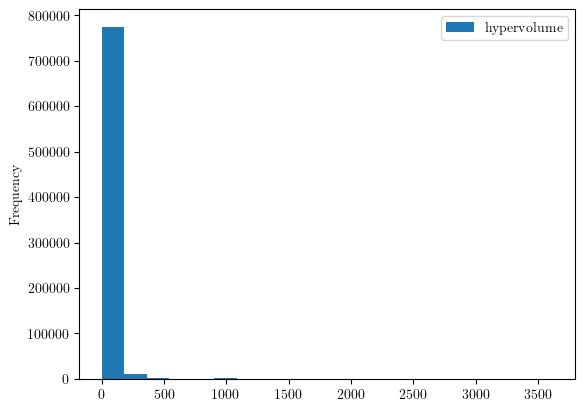

In [223]:
hypervolume_df = hypervolume_df.dropna(subset=["hypervolume"])
hypervolume_df.plot(x='weight', y='hypervolume', kind='hist', bins=20)
plt.show()

In [233]:
hypervolume_df[hypervolume_df['hypervolume']!=0]['no_alternatives'].unique()

array([ 3,  2,  4,  5,  7,  6,  8,  9, 10,  1])

In [235]:
hypervolume_df[hypervolume_df['hypervolume']==0] #['no_alternatives'].unique()

,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
342,417072496,213114076,0.800,0.0,0.0,0.0,691.552506,0.207084,1
343,417072496,213114076,0.800,0.0,0.0,0.0,691.552506,0.207084,1
344,417072496,213114076,0.640,0.0,0.0,0.0,691.552506,0.207084,1
345,417072496,213114076,0.640,0.0,0.0,0.0,691.552506,0.207084,1
346,417072496,213114076,0.512,0.0,0.0,0.0,691.552506,0.207084,1
...,...,...,...,...,...,...,...,...,...
899977,11435293864,12049099225,0.018,0.0,0.0,0.0,20.883792,0.003390,1
899978,11435293864,12049099225,0.018,0.0,0.0,0.0,20.883792,0.003390,1
899979,11435293864,12049099225,0.018,0.0,0.0,0.0,20.883792,0.003390,1
899980,11435293864,12049099225,0.018,0.0,0.0,0.0,20.883792,0.003390,1


In [225]:
# Drop rows without a hypervolume value.
hypervolume_clean = hypervolume_df.dropna(subset=["hypervolume"])

# Group by OD pair and get the index of the max hypervolume
idx = hypervolume_clean.groupby(["origin", "destination"])["hypervolume"].idxmax()

# Select the best routes
best_routes_df = hypervolume_clean.loc[idx].reset_index(drop=True)

best_routes_df.head()


,origin,destination,weight,hypervolume,time_diff_percentage,exposure_diff_percentage,fastest_time,fastest_exposure,no_alternatives
0,417072496,199399328,0.107,17.061321,2.674788,-7.128560,612.030625,0.179611,3
1,417072496,213099394,0.168,32.728113,1.282006,-8.377516,434.782800,0.129889,3
2,417072496,213114076,0.800,0.000000,0.000000,0.000000,691.552506,0.207084,1
3,417072496,215147941,0.069,45.714557,1.432568,-12.219736,167.192109,0.009113,2
4,417072496,243667230,0.086,17.233358,1.510975,-4.538536,1179.679988,0.255796,4


In [226]:
# Summarise the selected local routes.

# Calculate the average time difference percentage
avg_time_diff = best_routes_df['time_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_exposure_diff = best_routes_df['exposure_diff_percentage'].mean()

# Calculate the average exposure difference percentage
avg_weight = best_routes_df['weight'].mean()

# Print the results
print(f"Average Time Difference Percentage: {avg_time_diff:.2f}%")
print(f"Average Exposure Difference Percentage: {avg_exposure_diff:.2f}%")
print(f"Average Weight: {avg_weight:.3f}")


Average Time Difference Percentage: 3.23%
Average Exposure Difference Percentage: -13.53%
Average Weight: 0.392


Best Point on Pareto Front (Highest Hypervolume):
weight                             0.168000
avg_time_diff_percentage           1.323300
avg_exposure_diff_percentage      -5.874997
median_time_diff_percentage        0.000000
median_exposure_diff_percentage    0.000000
time_45th                          0.000000
time_55th                          0.000000
exposure_45th                      0.000000
exposure_55th                      0.000000
time_25th                          0.000000
time_75th                          0.000000
exposure_25th                      0.000000
exposure_75th                      0.000000
hypervolume                        8.725374
Name: 10, dtype: float64


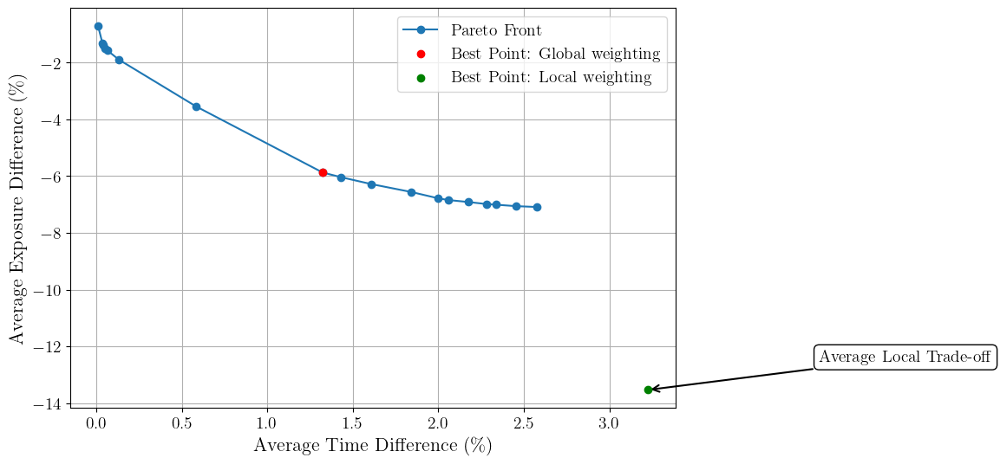

In [227]:
# NOTE: Tourist-scenario Pareto duplicate; saving is disabled, so this is display-only.
print("Best Point on Pareto Front (Highest Hypervolume):")
print(best_point)

fontsize = 20

# Plot Pareto front with the best point highlighted
plt.figure(figsize=(9, 6))

plt.plot(pareto_df['avg_time_diff_percentage'], pareto_df['avg_exposure_diff_percentage'], '-o', label="Pareto Front")

plt.scatter(best_point['avg_time_diff_percentage'], best_point['avg_exposure_diff_percentage'],
            color='red', label="Best Point: Global weighting", zorder=5)
plt.scatter(avg_time_diff, avg_exposure_diff,
            color='green', label="Best Point: Local weighting", zorder=5)

# Add an arrow pointing to the green point
plt.annotate(
    "Average Local Trade-off",
    xy=(avg_time_diff, avg_exposure_diff),  # Point to annotate
    xytext=(avg_time_diff + 1, avg_exposure_diff + 1),
    arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),  # Arrow style
    fontsize=fontsize-6,
    bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white")
)

plt.xlabel("Average Time Difference (\%)", fontsize=fontsize-4)
plt.ylabel("Average Exposure Difference (\%)", fontsize=fontsize-4)
plt.grid()
plt.legend()
plt.legend(fontsize=fontsize-6)
plt.xticks(fontsize=fontsize-6)
plt.yticks(fontsize=fontsize-6)

# Save the plot as a PDF
plot_name = "plots/pareto_avg_differences_tourists_v2.pdf"
plt.show()